# Ebola Bundibugyo 2026 (DRC) — Outbreak Forecasting with Real Transfer Learning, Spatio-Temporal GNN and Explainable AI

**Complete corrected pipeline (v3.1).** This notebook keeps all modules of the previous version (0–12) and fixes the errors and inconsistencies found in it.

**What was corrected (summary)**

| # | Problem in the previous version | Correction |
|---|---|---|
| 1 | **Target leakage**: `roll_mean_*`, `roll_std_*`, `growth_rate`, `zone_cumul` included the value to predict (e.g. `lag_1 × (1 + growth_rate) = value`) | Every feature is computed from information up to *t−1* only; an automatic leakage test (`check_no_leakage`) must pass |
| 2 | Target was the **cumulative** count (persistence gives R² ≈ 1) | Target = **new cases** per period; naive baselines (persistence, rolling mean) added to the leaderboard |
| 3 | Daily data vs weekly historical sources; two competing splits ("few-shot K=14" labels vs realistic split) | One chronological split; weekly resolution by default (`CFG.FREQ`); few-shot appears only in the transfer-learning ablation |
| 4 | Transfer learning used **simulated SIR curves**, a 1→19 input mismatch and a frozen random input layer | Real historical outbreaks (West Africa, North Kivu 2018, …), identical input space, two-stage fine-tuning, scratch control, few-shot ablation, leave-one-outbreak-out check (SIR kept only as a flagged fallback) |
| 5 | LSTM/Transformer windows crossed zone and train/test boundaries | Windows are built **per zone**, on exactly the same test rows as the ML models |
| 6 | GNN: snapshot regression whose node features (`last_val`, `max_val`) equalled the target, random node split, edges computed on the full period | Spatio-temporal GraphSAGE (pure PyTorch), geographic + train-only similarity edges, chronological split, "no-graph" control |
| 7 | Cross-validation was not chronological and **re-fitted the already trained models in place** | Expanding-window CV by date with cloned estimators and per-fold scaling |
| 8 | Scaling / clipping percentiles fitted separately on train and test | `FeaturePrep` fitted on the training period only |
| 9 | SHAP `TreeExplainer` misuse (fell back to Kernel SHAP on 30 rows); LIME disabled by a typo | Exact TreeSHAP on the full test set; LIME enabled, in raw feature units |
| 10 | Probabilistic forecast used in-sample residuals and a single row | Recursive multi-step national forecast with out-of-fold residual bootstrap |
| 11 | Maps placed unknown zones at **random coordinates** (`hash()`-seeded) | Only real coordinates (GeoJSON polygons or known centroids); unmatched zones are reported, never invented |
| 12 | Forecast intervals were far too wide (independent log-residuals compounded across zones); neural/tree models could not beat persistence by construction | Persistence-anchored models (`*_logdelta`, networks with an anchor channel), count-scaled **period-block bootstrap** of out-of-fold residuals, and a bootstrap interval of the skill versus persistence |
| 13 | Null values silently set to 0, duplicated rows, `'nan'` zones, first national increment dropped, mixed French/English, inconsistent module numbers | Validation report, cleaning, consistent English text and numbering |

**Run order:** run all cells from top to bottom. Historical outbreak files go in `historical_data/` (see Module 3); if a file is missing the notebook falls back to a **flagged** simulation and says so in the report.

## MODULE 0 · Configuration & Environment

In [1]:
# MODULE 0 · Imports, optional dependencies and global configuration

import os, sys, json, re, time, copy, math, random, shutil, logging, tarfile, zipfile, warnings
import zlib, unicodedata, fnmatch
from pathlib import Path
from datetime import datetime, timedelta
from typing import Dict, List, Tuple, Optional, Any, Sequence
from dataclasses import dataclass, field

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch

from scipy import stats
from scipy.integrate import odeint

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.svm import SVR

# ── Optional dependencies (the notebook degrades gracefully when one is missing) ──────────
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as tnf
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_OK = True
except Exception as _e:
    TORCH_OK = False
    print(f"PyTorch unavailable ({_e}) — deep-learning modules will be skipped")

try:
    import xgboost as xgb
    XGB_OK = True
except Exception:
    XGB_OK = False
    print("xgboost not installed — sklearn GradientBoosting is used instead")

try:
    import lightgbm as lgb
    LGB_OK = True
except Exception:
    LGB_OK = False
    print("lightgbm not installed — sklearn HistGradientBoosting is used instead")

try:
    import shap
    SHAP_OK = True
except Exception:
    SHAP_OK = False
    print("shap not installed — SHAP analysis will be skipped")

try:
    import lime
    import lime.lime_tabular
    LIME_OK = True
except Exception:
    LIME_OK = False
    print("lime not installed — LIME analysis will be skipped")

try:
    from statsmodels.tsa.stattools import adfuller, acf, pacf
    from statsmodels.stats.diagnostic import acorr_ljungbox
    STATSMODELS_OK = True
except Exception:
    STATSMODELS_OK = False
    print("statsmodels not installed — ADF / Ljung-Box / ACF analysis will be skipped")

try:
    import geopandas as gpd
    from shapely.geometry import Point
    GEO_AVAILABLE = True
except Exception:
    GEO_AVAILABLE = False
    print("geopandas not installed — polygon maps disabled")

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.WARNING)

print(f"Python  : {sys.version.split()[0]}")
print(f"Pandas  : {pd.__version__} | NumPy: {np.__version__}")
if TORCH_OK:
    print(f"PyTorch : {torch.__version__} | CUDA available: {torch.cuda.is_available()}")

C:\Users\Hp\anaconda3\envs\Torch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python  : 3.12.13
Pandas  : 3.0.3 | NumPy: 2.4.6
PyTorch : 2.11.0+cpu | CUDA available: False


In [2]:
# ── Centralised configuration 
@dataclass
class Config:
    # Reproducibility
    SEED: int = 42

    # Paths (folder names kept from the previous version so downloaded data is reused)
    DATA_DIR:    Path = Path("donnees_ebola")
    EXTRACT_DIR: Path = Path("donnees_extraites")
    HIST_DIR:    Path = Path("historical_data")      # put West Africa / North Kivu / ... files here
    OUTPUT_DIR:  Path = Path("outputs")
    FIG_DIR:     Path = Path("outputs/figures")
    REPORT_DIR:  Path = Path("outputs/reports")
    FIG_DPI:     int  = 600

    # GitHub source (INRB-UMIE)
    GITHUB_REPO:    str = "INRB-UMIE/BDBV2026-Data"
    GITHUB_API_URL: str = "https://api.github.com/repos/INRB-UMIE/BDBV2026-Data/releases"

    # Epidemiological files (long format: zone | date | value)
    CSV_MAP: Dict[str, str] = field(default_factory=lambda: {
        "nat_cases":     "long/insp_sitrep__national_cumulative_confirmed_cases.csv",
        "nat_deaths":    "long/insp_sitrep__national_cumulative_confirmed_deaths.csv",
        "nat_recovered": "long/insp_sitrep__national_cumulative_recovered_cases.csv",
        "nat_suspected": "long/insp_sitrep__national_cumulative_suspected_cases.csv",
        "new_cases":     "long/insp_sitrep__new_confirmed_cases.csv",
        "cum_cases":     "long/insp_sitrep__cumulative_confirmed_cases.csv",
        "cum_deaths":    "long/insp_sitrep__cumulative_confirmed_deaths.csv",
        "cum_suspected": "long/insp_sitrep__cumulative_suspected_cases.csv",
    })

    # Time resolution and chronological split
    FREQ:        str = 'W'                 # 'W' = weekly (recommended) | 'D' = daily
    TRAIN_END:   str = '2026-09-30'
    TEST_START:  str = '2026-10-01'
    TEST_END:    Optional[str] = None      # None = up to the last complete period
    VAL_STEPS:   int = 3                   # last periods of the training window used for validation
    USE_ZONE_ID: bool = False              # zone identifier as a feature (not transferable across outbreaks)
    LAGS:  Dict[str, Tuple[int, ...]] = field(default_factory=lambda: {'W': (1, 2, 3, 4), 'D': (1, 2, 3, 7, 14)})
    ROLLS: Dict[str, Tuple[int, ...]] = field(default_factory=lambda: {'W': (2, 4), 'D': (3, 7, 14)})
    SEQ_LEN: Dict[str, int] = field(default_factory=lambda: {'W': 4, 'D': 7})
    FORECAST_STEPS: Dict[str, int] = field(default_factory=lambda: {'W': 4, 'D': 14})

    # Evaluation
    RISK_PCTILE:  int = 75                 # high-risk = above this percentile of positive training targets
    N_CV_FOLDS:   int = 4
    N_BOOTSTRAP:  int = 500
    RESID_LAST_FOLDS: int = 2              # forecast noise: out-of-fold residuals of the most recent CV folds only
    N_SKILL_BOOT: int = 2000               # bootstrap resamples (over test periods) for the skill-vs-persistence interval
    RUN_SVR_POLY: bool = False             # optional third SVM (slow)

    # Deep learning (LSTM / Transformer)
    DL_EPOCHS:   int = 300
    DL_LR:       float = 1e-3
    DL_PATIENCE: int = 30
    DL_BATCH:    int = 16
    DL_HIDDEN:   int = 64
    DL_DROPOUT:  float = 0.3

    # Transfer learning (univariate series model shared by sources and target)
    TL_SEQ_LEN:          int = 6
    TL_HIDDEN:           int = 32
    TL_LAYERS:           int = 2
    TL_PRETRAIN_EPOCHS:  int = 150
    TL_LOO_EPOCHS:       int = 60
    TL_HEAD_EPOCHS:      int = 30
    TL_FT_EPOCHS:        int = 120
    TL_LR_PRETRAIN:      float = 2e-3
    TL_LR_HEAD:          float = 1e-3
    TL_LR_FT:            float = 3e-4
    TL_SEEDS:            int = 3
    TL_K_LIST:           Tuple[int, ...] = (2, 4, 6, 8, 12, 16)   # few-shot: periods of target data used
    TL_EVAL_STEPS:       int = 4
    TL_MIN_CASES_SOURCE: int = 30
    TL_MIN_STEPS_SOURCE: int = 8

    # Spatio-temporal GNN
    GNN_HIDDEN:        int = 32
    GNN_LAYERS:        int = 2
    GNN_EPOCHS:        int = 300
    GNN_LR:            float = 2e-3
    GNN_DROPOUT:       float = 0.2
    GNN_PATIENCE:      int = 40
    GNN_WINDOW:        int = 4
    GNN_SIM_THRESHOLD: float = 0.6
    GNN_SIM_TOPK:      int = 3

    # Historical outbreaks used for transfer learning.
    # Metadata (R0, CFR, ...) is only used by the *fallback* SIR simulation.
    # Real files are searched in HIST_DIR with the `file_patterns`; set `path` to force a file and
    # `columns` / `indicator_regex` / `keep_status` / `cumulative` only if the automatic detection is wrong.
    HISTORICAL_OUTBREAKS: Dict[str, Dict] = field(default_factory=lambda: {
        "WestAfrica_2014": {
            "peak_week": 40, "total_cases": 28616, "R0": 1.71, "cfr": 0.40, "duration_weeks": 104,
            "country": "Guinea/Sierra Leone/Liberia", "strain": "Zaire", "use_in_pretraining": True,
            "file_patterns": ["*west*africa*", "*ebola_data_db_format*", "*ebola*2014*", "*ebola*cases*2014*"],
            "path": None, "columns": None, "indicator_regex": None, "keep_status": None, "cumulative": "auto",
        },
        "DRC_2018_Nord_Kivu": {
            "peak_week": 26, "total_cases": 3481, "R0": 1.59, "cfr": 0.67, "duration_weeks": 94,
            "country": "DRC", "strain": "Zaire", "use_in_pretraining": True,
            "file_patterns": ["*kivu*", "*vossler*", "*zenodo*", "*ituri*", "*drc*", "*rdc*", "*congo*", "*2018*"],
            "path": None, "columns": None, "indicator_regex": None, "keep_status": ("confirmed",), "cumulative": "auto",
        },
        "DRC_2021_Nord_Kivu": {
            "peak_week": 8, "total_cases": 12, "R0": 1.20, "cfr": 0.50, "duration_weeks": 8,
            "country": "DRC", "strain": "Zaire", "use_in_pretraining": False,    # only 12 cases: metadata only
            "file_patterns": ["*butembo*2021*", "*kivu*2021*"],
            "path": None, "columns": None, "indicator_regex": None, "keep_status": None, "cumulative": "auto",
        },
        "Uganda_2022": {
            "peak_week": 8, "total_cases": 164, "R0": 1.40, "cfr": 0.55, "duration_weeks": 16,
            "country": "Uganda", "strain": "Sudan", "use_in_pretraining": True,
            "file_patterns": ["*uganda*", "*sudan*virus*", "*surveillance_data*"],
            "path": None, "columns": None, "indicator_regex": None, "keep_status": ("confirmed",), "cumulative": "auto",
        },
    })

    # Convenience accessors for the active resolution
    @property
    def lags(self) -> Tuple[int, ...]:   return self.LAGS[self.FREQ]
    @property
    def rolls(self) -> Tuple[int, ...]:  return self.ROLLS[self.FREQ]
    @property
    def seq_len(self) -> int:            return self.SEQ_LEN[self.FREQ]
    @property
    def forecast_steps(self) -> int:     return self.FORECAST_STEPS[self.FREQ]
    @property
    def step_days(self) -> int:          return 7 if self.FREQ == 'W' else 1
    @property
    def step_label(self) -> str:         return 'week' if self.FREQ == 'W' else 'day'


CFG = Config()
for _d in [CFG.DATA_DIR, CFG.EXTRACT_DIR, CFG.HIST_DIR, CFG.OUTPUT_DIR, CFG.FIG_DIR, CFG.REPORT_DIR]:
    _d.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int) -> None:
    """Seed Python, NumPy and (if available) PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_OK:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)


def stable_seed(text: str) -> int:
    """Deterministic integer seed from a string (Python's hash() is randomised between sessions)."""
    return zlib.crc32(text.encode('utf-8')) % (2 ** 31)


set_seed(CFG.SEED)
DEVICE = torch.device('cuda' if (TORCH_OK and torch.cuda.is_available()) else 'cpu') if TORCH_OK else None

# Publication style
plt.rcParams.update({
    'figure.dpi': 150, 'font.family': 'DejaVu Sans',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelsize': 11, 'axes.titlesize': 13, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
})
PALETTE = ["#2C3E50", "#E74C3C", "#3498DB", "#2ECC71", "#F39C12", "#9B59B6", "#1ABC9C", "#E67E22"]


def save_fig(fig, filename: str) -> Path:
    """Save a figure in CFG.FIG_DIR with the publication settings."""
    path = CFG.FIG_DIR / filename
    fig.savefig(path, dpi=CFG.FIG_DPI, bbox_inches='tight', facecolor='white', edgecolor='none')
    print(f"Saved figure: {filename}")
    return path


# Global registries filled by the modules
RUN_STATUS: Dict[str, str] = {}      # section -> "ok" | "skipped: reason" | "failed: error"
PROVENANCE: Dict[str, Any] = {}      # data release, source kinds, ...

print(f"Config initialised | device: {DEVICE} | resolution: {CFG.FREQ} | seed: {CFG.SEED}")
print(f"Directories: {[str(d) for d in [CFG.OUTPUT_DIR, CFG.FIG_DIR, CFG.REPORT_DIR, CFG.HIST_DIR]]}")

Config initialised | device: cpu | resolution: W | seed: 42
Directories: ['outputs', 'outputs\\figures', 'outputs\\reports', 'historical_data']


In [3]:
# ── PyTorch training utilities (shared by Modules 3, 9 and 10) ───────
def fit_torch(model, X, y, Xv=None, yv=None, epochs: int = 100, lr: float = 1e-3,
              weight_decay: float = 1e-4, patience: int = 20, batch_size: int = 32,
              seed: int = 0, params=None, name: str = '', verbose: bool = True):
    """Train a sequence model (X: (N, T, F) -> y: (N,)) with Huber loss and early stopping.

    Early stopping monitors the validation loss when (Xv, yv) is given, otherwise the training loss.
    The best weights are restored at the end. Returns (model, history)."""
    if not TORCH_OK:
        raise RuntimeError("PyTorch is not available")
    if len(X) == 0:
        raise ValueError("empty training set")
    torch.manual_seed(seed)
    model = model.to(DEVICE)
    params = list(params) if params is not None else [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    crit = nn.HuberLoss()

    Xt = torch.as_tensor(np.asarray(X), dtype=torch.float32)
    yt = torch.as_tensor(np.asarray(y), dtype=torch.float32)
    has_val = Xv is not None and yv is not None and len(Xv) > 0
    if has_val:
        Xvt = torch.as_tensor(np.asarray(Xv), dtype=torch.float32, device=DEVICE)
        yvt = torch.as_tensor(np.asarray(yv), dtype=torch.float32, device=DEVICE)
    gen = torch.Generator()
    gen.manual_seed(seed)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True, generator=gen)

    best_loss, best_state, best_epoch, wait = float('inf'), None, 0, 0
    hist = {'train': [], 'val': []}
    for epoch in range(epochs):
        model.train()
        ep_loss, n_batches = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            ep_loss += loss.item()
            n_batches += 1
        ep_loss /= max(n_batches, 1)
        hist['train'].append(ep_loss)
        if has_val:
            model.eval()
            with torch.no_grad():
                v_loss = crit(model(Xvt), yvt).item()
            hist['val'].append(v_loss)
            monitored = v_loss
        else:
            monitored = ep_loss
        if monitored < best_loss - 1e-6:
            best_loss, best_epoch, wait = monitored, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    hist['best_epoch'] = best_epoch
    if verbose:
        tag = 'val' if has_val else 'train'
        print(f"   {name:24s} {epoch + 1:4d} epochs | best epoch {best_epoch + 1:4d} | best {tag} loss {best_loss:.5f}")
    return model, hist


def predict_torch(model, X, batch_size: int = 2048) -> np.ndarray:
    """Batched inference for sequence models; returns a NumPy array."""
    model.eval()
    X = np.asarray(X, dtype=np.float32)
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.as_tensor(X[i:i + batch_size], device=DEVICE)
            out.append(model(xb).cpu().numpy())
    return np.concatenate(out) if out else np.array([])

## MODULE 1 · Data Acquisition & Validation

In [4]:
# MODULE 1 · Data acquisition & validation (INRB-UMIE BDBV2026)

INVALID_ZONE_NAMES = {'', 'nan', 'none', 'null', 'na', 'n/a'}


def parse_dates_series(s: pd.Series) -> pd.Series:
    """Vectorised robust date parsing: ISO first, then a day-first fallback (French-style sources)."""
    s = s.astype(str).str.strip().str.replace(r'[\[\]"]', '', regex=True)
    out = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    bad = out.isna() & ~s.str.lower().isin(INVALID_ZONE_NAMES)
    if bad.any():
        alt = pd.to_datetime(s[bad], errors='coerce', format='mixed', dayfirst=True)
        if getattr(alt.dt, 'tz', None) is not None:
            alt = alt.dt.tz_localize(None)
        out = out.fillna(alt)
    return out


def _pick_col(df: pd.DataFrame, candidates: Sequence[str]) -> Optional[str]:
    """First column whose normalised name equals one of the candidates."""
    norm = {c: re.sub(r'[^a-z]', '', str(c).lower()) for c in df.columns}
    for cand in candidates:
        for c, n in norm.items():
            if n == cand:
                return c
    return None


def normalize_long_df(df: pd.DataFrame, agg: str = 'max') -> pd.DataFrame:
    """Normalise a CSV to long format (zone | date | value).

    * columns are detected by name when possible (positional order zone, date, value otherwise);
    * null values are DROPPED (never silently replaced by 0) and counted in `df.attrs`;
    * invalid zone names ('nan', '') are dropped; duplicated (zone, date) rows are aggregated with `agg`."""
    raw = df.copy()
    zc = _pick_col(raw, ('zone', 'zonesante', 'healthzone', 'zs', 'region', 'province', 'location'))
    dc = _pick_col(raw, ('date', 'jour', 'day'))
    vc = _pick_col(raw, ('value', 'valeur', 'cases', 'count', 'n'))
    if zc and dc and vc:
        raw = raw[[zc, dc, vc]]
        raw.columns = ['zone', 'date', 'value']
    elif len(raw.columns) == 3:
        raw.columns = ['zone', 'date', 'value']
    elif len(raw.columns) == 2:
        raw.columns = ['date', 'value']
        raw.insert(0, 'zone', 'DRC')
    else:
        raise ValueError(f"Cannot interpret columns: {list(df.columns)}")

    n0 = len(raw)
    raw['zone'] = raw['zone'].astype(str).str.strip()
    raw['date'] = parse_dates_series(raw['date'])
    raw['value'] = pd.to_numeric(raw['value'], errors='coerce')
    null_rows = int(raw['value'].isna().sum())
    date_fail = int(raw['date'].isna().sum())
    bad_zone = int(raw['zone'].str.lower().isin(INVALID_ZONE_NAMES).sum())
    raw = raw.dropna(subset=['date', 'value'])
    raw = raw[~raw['zone'].str.lower().isin(INVALID_ZONE_NAMES)]
    n_dupes = int(raw.duplicated(['zone', 'date']).sum())
    out = raw.groupby(['zone', 'date'], as_index=False)['value'].agg(agg)
    out = out.sort_values(['zone', 'date']).reset_index(drop=True)
    out.attrs.update(rows_raw=n0, null_value_rows=null_rows, date_parse_failures=date_fail,
                     invalid_zone_rows=bad_zone, duplicate_rows=n_dupes,
                     raw_null_pct=100.0 * null_rows / max(n0, 1))
    return out


def validate_dataframe(df: pd.DataFrame, name: str, cumulative: bool = True) -> Dict:
    """Short data-quality report (cumulative files: monotonicity and final total are checked)."""
    zones = df['zone'].unique()
    sub = df[df['zone'] != 'DRC'] if len(zones) > 1 else df
    last_per_zone = sub.sort_values('date').groupby('zone')['value'].last()
    violations = 0
    if cumulative:
        for _, g in df.groupby('zone'):
            violations += int((g['value'].diff() < -1e-9).sum())
    return {
        'name': name, 'rows': len(df), 'n_zones': int(df['zone'].nunique()),
        'null_pct': float(df.attrs.get('raw_null_pct', 0.0)),
        'neg_count': int((df['value'] < 0).sum()),
        'duplicates': int(df.attrs.get('duplicate_rows', 0)),
        'monotonic_violations': violations,
        'date_min': df['date'].min(), 'date_max': df['date'].max(),
        'final_total': float(last_per_zone.sum()) if cumulative else float(sub['value'].sum()),
    }


def fetch_latest_release(cfg: Config) -> Optional[Dict]:
    """Metadata of the latest 'build' release of the data repository."""
    try:
        r = requests.get(cfg.GITHUB_API_URL, timeout=20)
        r.raise_for_status()
        builds = [rel for rel in r.json() if 'build' in rel.get('tag_name', '')]
        if not builds:
            raise ValueError("no release containing 'build' found")
        latest = builds[0]
        print(f" Release: {latest['tag_name']} ({latest['published_at'][:10]})")
        return latest
    except Exception as e:
        print(f" GitHub unavailable: {e}")
        return None


def _safe_extract_tar(path: Path, dest: Path) -> None:
    with tarfile.open(path, 'r:gz') as tar:
        try:
            tar.extractall(dest, filter='data')      # Python >= 3.12: blocks path traversal
        except TypeError:
            tar.extractall(dest)


def download_assets(release: Dict, cfg: Config) -> List[Path]:
    """Download and extract the assets of a release."""
    downloaded = []
    for asset in release.get('assets', []):
        name = asset['name']
        dst = cfg.DATA_DIR / name
        if dst.exists():
            print(f"   (already present) {name}")
        else:
            try:
                r = requests.get(asset['browser_download_url'], timeout=120)
                r.raise_for_status()
                dst.write_bytes(r.content)
                print(f"   downloaded {name} ({len(r.content) // 1024} KB)")
            except Exception as e:
                print(f"   failed {name}: {e}")
                continue
        downloaded.append(dst)
        if name.endswith('.tar.gz'):
            _safe_extract_tar(dst, cfg.EXTRACT_DIR)
        elif name.endswith('.zip'):
            with zipfile.ZipFile(dst, 'r') as z:
                z.extractall(cfg.DATA_DIR)
    return downloaded


def load_epidemio_data(cfg: Config) -> Dict[str, pd.DataFrame]:
    """Load every epidemiological CSV in normalised long format."""
    base = cfg.EXTRACT_DIR / 'build'
    data = {}
    print("\n── Loading epidemiological data ──────────────────────────")
    for key, relpath in cfg.CSV_MAP.items():
        path = base / relpath
        if not path.exists():
            print(f"    {key}: {relpath} not found")
            continue
        try:
            incident = key.startswith('new')
            df = normalize_long_df(pd.read_csv(path), agg='sum' if incident else 'max')
            rep = validate_dataframe(df, key, cumulative=not incident)
            data[key] = df
            flags = []
            if rep['duplicates']:           flags.append(f"{rep['duplicates']} duplicate rows merged")
            if rep['monotonic_violations']: flags.append(f"{rep['monotonic_violations']} downward corrections")
            if rep['null_pct'] > 0:         flags.append(f"{rep['null_pct']:.1f}% null values dropped")
            print(f"    {key:15s} {rep['rows']:5d} rows {rep['n_zones']:3d} zones | "
                  f"{rep['date_min'].date()} → {rep['date_max'].date()} | final total={rep['final_total']:,.0f}"
                  + (f" | {'; '.join(flags)}" if flags else ""))
        except Exception as e:
            print(f"    {key}: {e}")
    return data


print("=" * 68)
print("DATA ACQUISITION — INRB-UMIE BDBV2026")
print("=" * 68)
RELEASE = fetch_latest_release(CFG)
if RELEASE:
    download_assets(RELEASE, CFG)
    PROVENANCE['data_release'] = RELEASE.get('tag_name')
    PROVENANCE['data_release_date'] = RELEASE.get('published_at', '')[:10]
else:
    PROVENANCE['data_release'] = 'local copy (GitHub unavailable)'

DATA = load_epidemio_data(CFG)
print(f"\n→ {len(DATA)} files loaded")
if 'cum_cases' not in DATA:
    raise RuntimeError("cum_cases is required: check the extracted data in "
                       f"{CFG.EXTRACT_DIR / 'build'} or your internet connection.")
PROVENANCE['n_files_loaded'] = len(DATA)

# Consistency check: sum of the zone-level cumulative counts vs. the national cumulative count
if 'nat_cases' in DATA:
    _z = DATA['cum_cases']
    _z = _z[_z['zone'] != 'DRC'].sort_values('date').groupby('zone')['value'].last().sum()
    _n = float(DATA['nat_cases'].sort_values('date')['value'].iloc[-1])
    PROVENANCE['zone_sum_vs_national'] = {'zones_total': float(_z), 'national_total': _n, 'difference': float(_z - _n)}
    print(f"Consistency: sum over zones = {_z:,.0f} | national series = {_n:,.0f} | difference = {_z - _n:+,.0f} "
          f"({(_z - _n) / max(_n, 1):+.1%}) — zone-level modelling uses the zone files")

DATA ACQUISITION — INRB-UMIE BDBV2026
 Release: build-2026-11-17-d796b0a (2026-11-17)
   (already present) build-2026-11-17-d796b0a.tar.gz

── Loading epidemiological data ──────────────────────────
    nat_cases         154 rows   1 zones | 2026-05-17 → 2026-11-15 | final total=11,432
    nat_deaths        154 rows   1 zones | 2026-05-17 → 2026-11-15 | final total=5,593
    nat_recovered     143 rows   1 zones | 2026-05-28 → 2026-11-15 | final total=3,109
    nat_suspected      69 rows   1 zones | 2026-05-17 → 2026-08-04 | final total=270 | 31 downward corrections
    new_cases         184 rows  35 zones | 2026-05-15 → 2026-07-15 | final total=327 | 12.3% null values dropped
    cum_cases        7331 rows  75 zones | 2026-05-15 → 2026-11-15 | final total=11,479 | 26 downward corrections; 0.1% null values dropped
    cum_deaths       7259 rows  76 zones | 2026-05-19 → 2026-11-15 | final total=5,117 | 22 downward corrections; 0.3% null values dropped
    cum_suspected     163 rows  22 z

## MODULE 2 · Exploratory Analysis, Statistical Tests and Maps

Period        : 2026-05-17 → 2026-11-15 (29 days without report carried forward)
Max cumulative: 11,432
Sum of new    : 11,432  (equals the maximum cumulative value)
Complete weeks: 27 (2026-05-17 → 2026-11-15)
Saved figure: 01_eda_national.png


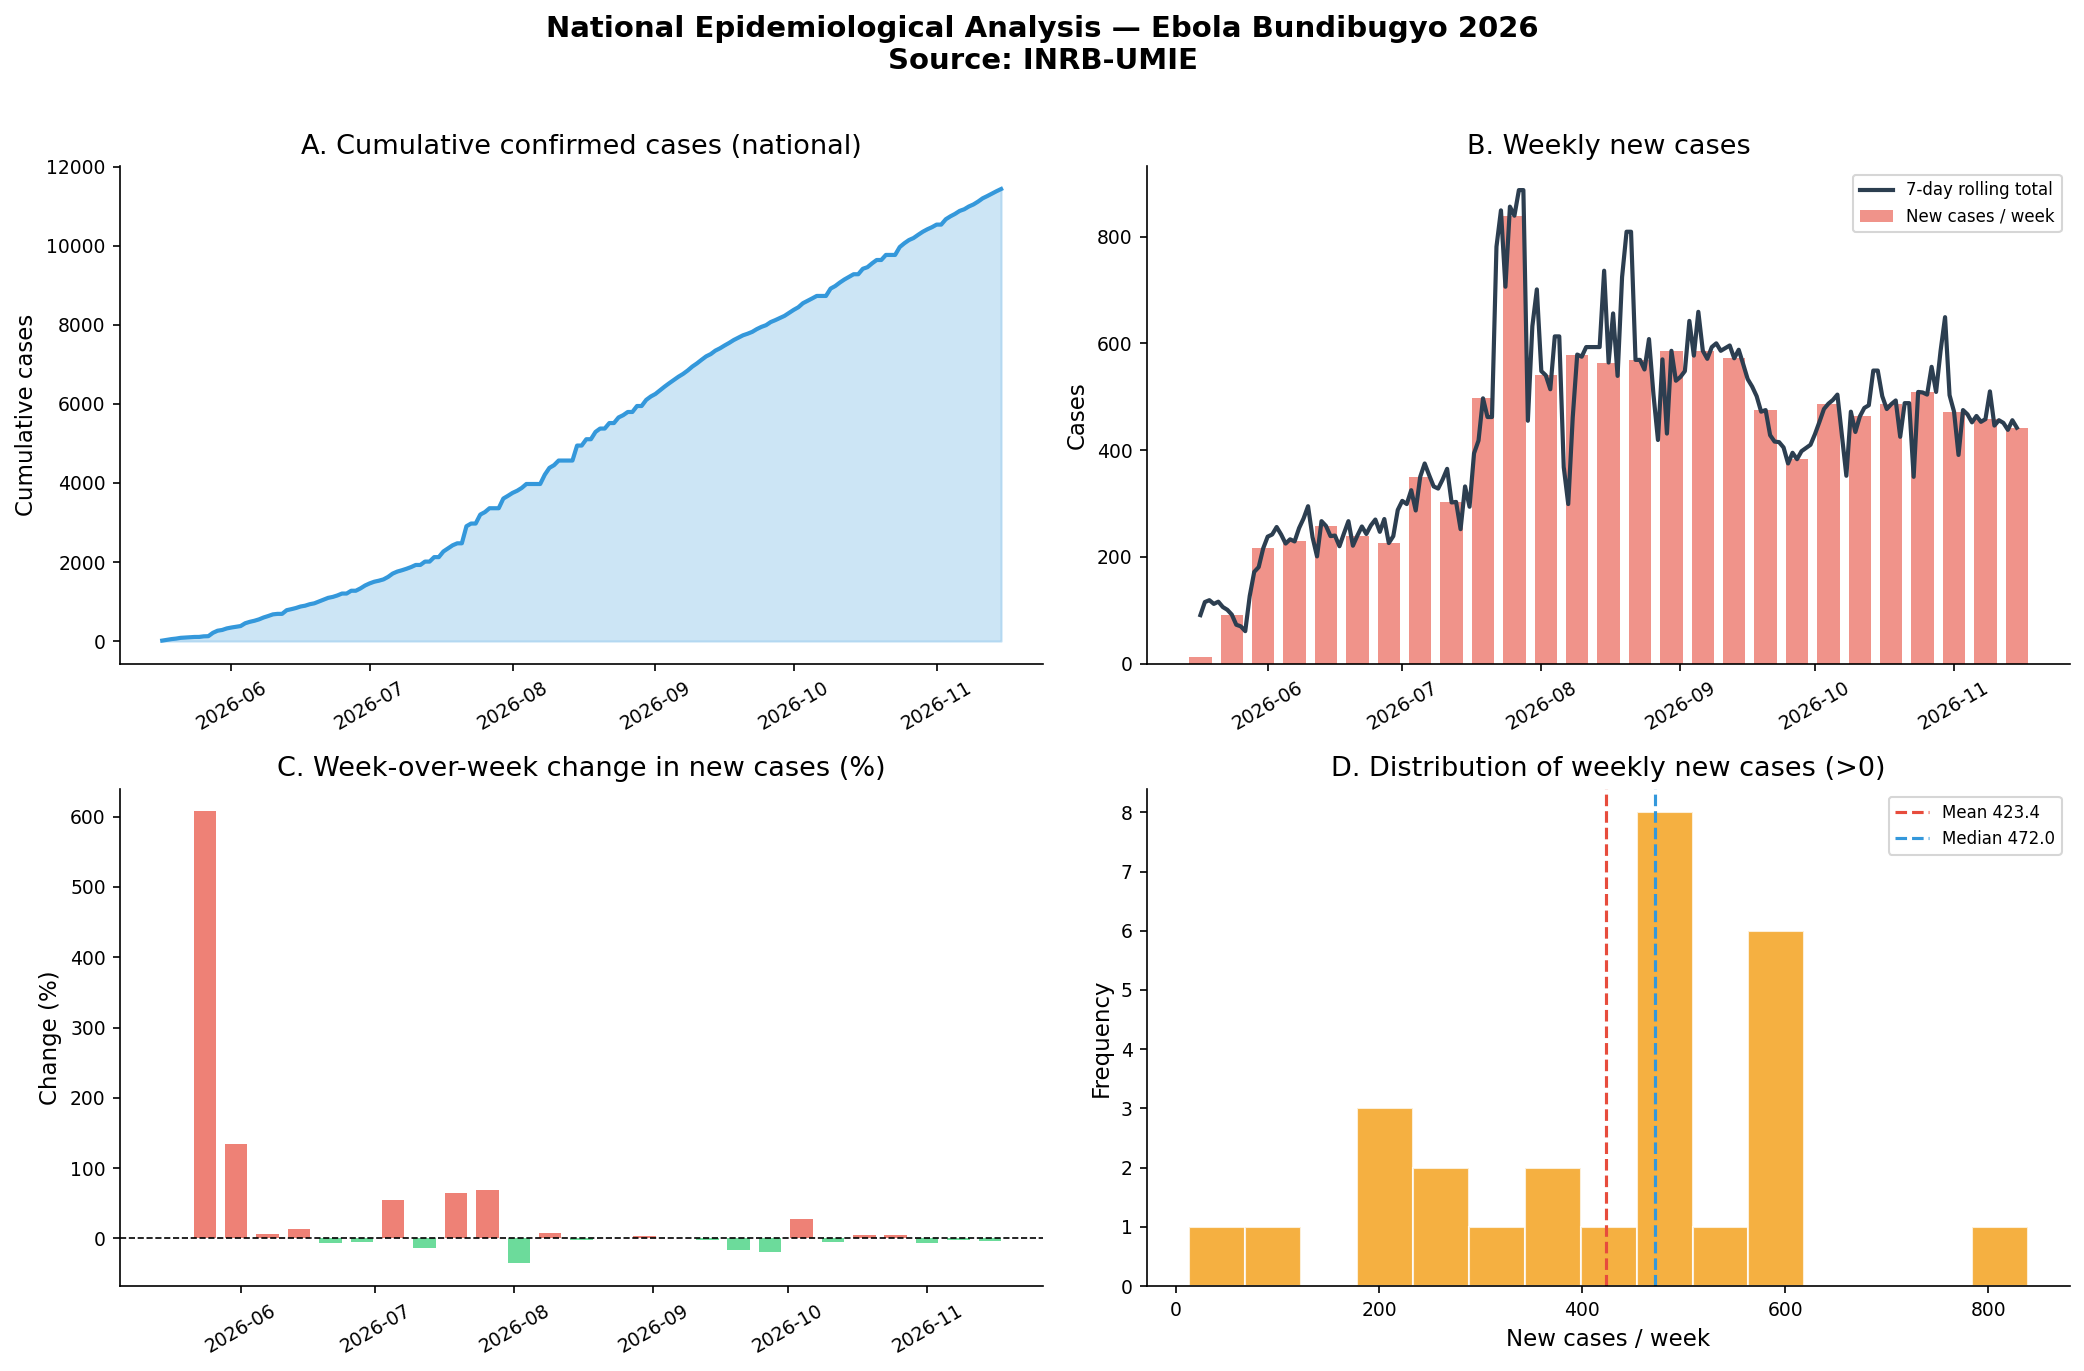

Saved figure: 02_top_zones.png


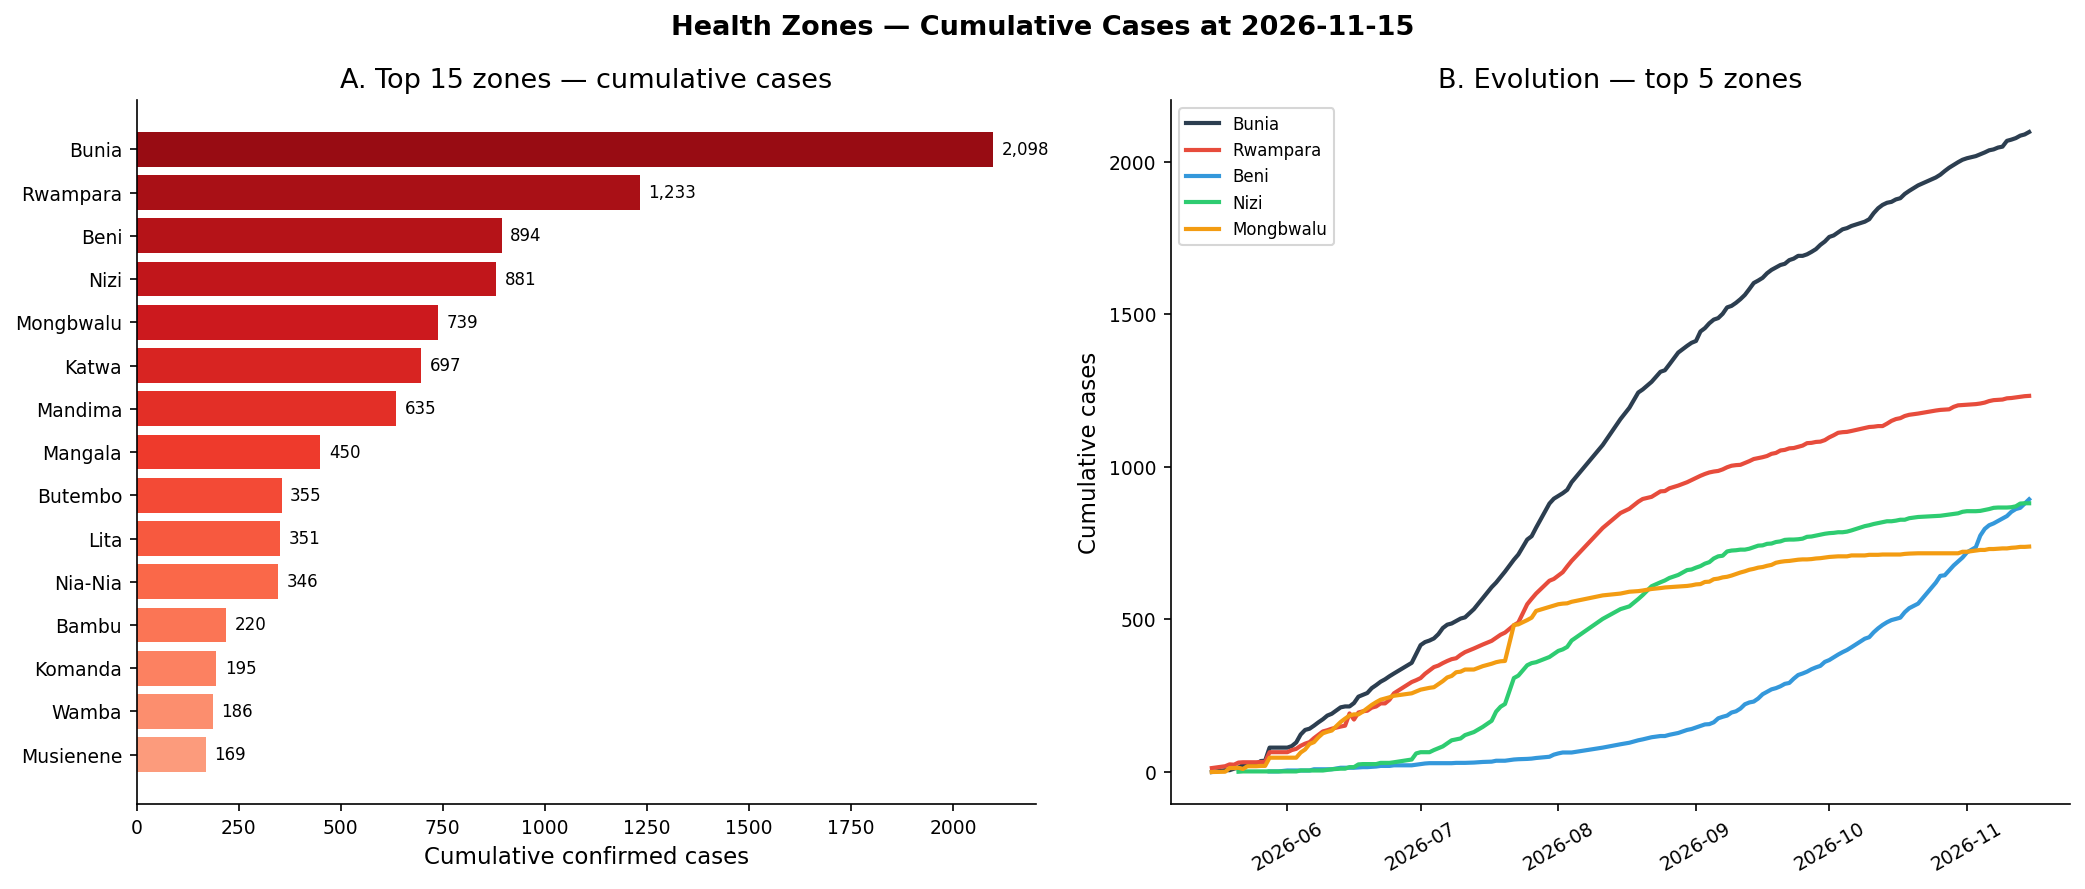

── Statistical tests ─────────────────────────────────────────
   [daily] ADF: stat=-2.7086 p=0.0726 → NON-STATIONARY
   [daily] Ljung-Box: significant lags = [1, 5, 6, 7, 8, 9, 10]
   [daily] Shapiro-Wilk: stat=0.7785 p=0.0000
   [weekly] ADF: stat=-9.6662 p=0.0000 → STATIONARY
   [weekly] Ljung-Box: significant lags = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
   [weekly] Shapiro-Wilk: stat=0.9420 p=0.1500
Saved figure: 03_acf_pacf.png


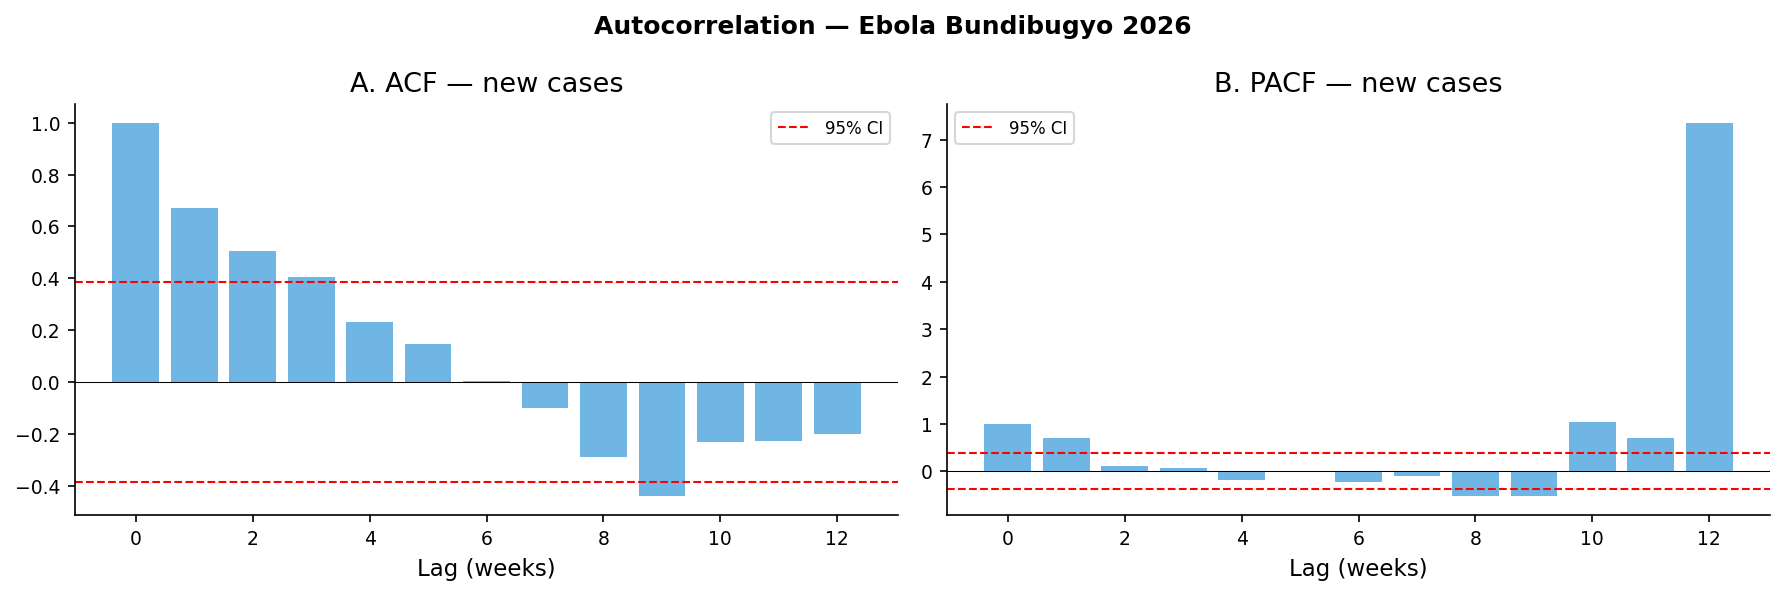

In [5]:
# MODULE 2 · Exploratory analysis & statistical tests

def _weekly_new_from_cumulative(daily: pd.DataFrame) -> pd.DataFrame:
    """Daily cumulative series -> weekly (Mon–Sun, labelled by the Sunday) new cases; complete weeks only."""
    s = daily.set_index('date')['value']
    wk = s.resample('W-SUN').last()
    if s.index.max().weekday() != 6:          # last week incomplete
        wk = wk.iloc[:-1]
    new = wk.diff()
    new.iloc[0] = wk.iloc[0]
    return pd.DataFrame({'date': wk.index, 'cum_cases': wk.to_numpy(), 'new_cases': new.clip(lower=0).to_numpy()})


def get_national_series(data: Dict, key: str = 'nat_cases') -> Optional[pd.DataFrame]:
    """National (DRC) daily series. Days without a report carry the previous cumulative value forward
    (so unreported days show 0 new cases and the jump appears on the next reported day)."""
    if key not in data:
        print(f" Key '{key}' missing")
        return None
    df = data[key]
    drc = df[df['zone'] == 'DRC']
    if drc.empty:
        drc = df.groupby('date', as_index=False)['value'].sum()
    s = drc.groupby('date')['value'].max().sort_index()
    idx = pd.date_range(s.index.min(), s.index.max(), freq='D')
    reported = idx.isin(s.index)
    s = s.reindex(idx).ffill().cummax()
    out = pd.DataFrame({'zone': 'DRC', 'date': idx, 'value': s.to_numpy(), 'reported': reported})
    new = out['value'].diff()
    new.iloc[0] = out['value'].iloc[0]                    # first increment = first cumulative value (was dropped before)
    out['new_cases'] = new.clip(lower=0)
    prev = out['value'].shift(1).replace(0, np.nan)
    out['growth_rate'] = (out['value'].diff() / prev * 100).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    out['rolling7'] = out['new_cases'].rolling(7, min_periods=1).mean()
    out.attrs['unreported_days'] = int((~reported).sum())
    return out


NAT = get_national_series(DATA, 'nat_cases')
NAT_W = None
if NAT is not None:
    NAT_W = _weekly_new_from_cumulative(NAT[['date', 'value']])
    print(f"Period        : {NAT['date'].min().date()} → {NAT['date'].max().date()} "
          f"({NAT.attrs['unreported_days']} days without report carried forward)")
    print(f"Max cumulative: {int(NAT['value'].max()):,}")
    print(f"Sum of new    : {int(NAT['new_cases'].sum()):,}  (equals the maximum cumulative value)")
    print(f"Complete weeks: {len(NAT_W)} ({NAT_W['date'].min().date()} → {NAT_W['date'].max().date()})")


def plot_eda_national(nat: pd.DataFrame, nat_w: pd.DataFrame, cfg: Config) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle("National Epidemiological Analysis — Ebola Bundibugyo 2026\nSource: INRB-UMIE",
                 fontsize=14, fontweight='bold', y=1.01)
    ax = axes[0, 0]
    ax.fill_between(nat['date'], nat['value'], alpha=0.25, color=PALETTE[2])
    ax.plot(nat['date'], nat['value'], color=PALETTE[2], lw=2)
    ax.set_title("A. Cumulative confirmed cases (national)")
    ax.set_ylabel("Cumulative cases"); ax.tick_params(axis='x', rotation=30)

    ax = axes[0, 1]
    ax.bar(nat_w['date'], nat_w['new_cases'], width=5, alpha=0.6, color=PALETTE[1], label="New cases / week")
    ax.plot(nat['date'], nat['rolling7'] * 7, color=PALETTE[0], lw=2, label="7-day rolling total")
    ax.set_title("B. Weekly new cases")
    ax.set_ylabel("Cases"); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)

    ax = axes[1, 0]
    g = nat_w['new_cases'].pct_change().replace([np.inf, -np.inf], np.nan).fillna(0) * 100
    ax.bar(nat_w['date'], g, width=5, color=[PALETTE[1] if v > 0 else PALETTE[3] for v in g], alpha=0.7)
    ax.axhline(0, color='black', lw=0.8, ls='--')
    ax.set_title("C. Week-over-week change in new cases (%)")
    ax.set_ylabel("Change (%)"); ax.tick_params(axis='x', rotation=30)

    ax = axes[1, 1]
    nc_pos = nat_w['new_cases'][nat_w['new_cases'] > 0]
    if len(nc_pos):
        ax.hist(nc_pos, bins=min(15, len(nc_pos)), color=PALETTE[4], edgecolor='white', alpha=0.8)
        ax.axvline(nc_pos.mean(), color=PALETTE[1], ls='--', lw=1.5, label=f"Mean {nc_pos.mean():.1f}")
        ax.axvline(nc_pos.median(), color=PALETTE[2], ls='--', lw=1.5, label=f"Median {nc_pos.median():.1f}")
        ax.legend(fontsize=8)
    ax.set_title("D. Distribution of weekly new cases (>0)")
    ax.set_xlabel("New cases / week"); ax.set_ylabel("Frequency")
    plt.tight_layout()
    save_fig(fig, "01_eda_national.png")
    plt.show()


if NAT is not None:
    plot_eda_national(NAT, NAT_W, CFG)


def plot_top_zones(data: Dict, cfg: Config, top_n: int = 15) -> Optional[pd.DataFrame]:
    if 'cum_cases' not in data:
        print(" 'cum_cases' missing")
        return None
    df = data['cum_cases']
    df = df[df['zone'] != 'DRC']
    last = df.sort_values('date').groupby('zone', as_index=False).agg(value=('value', 'last'))
    last_dt = df['date'].max()
    df_last = last[last['value'] > 0].sort_values('value', ascending=False).head(top_n)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Health Zones — Cumulative Cases at {last_dt.date()}", fontsize=13, fontweight='bold')
    ax = axes[0]
    cmap = plt.cm.Reds(np.linspace(0.9, 0.35, len(df_last)))
    bars = ax.barh(df_last['zone'], df_last['value'], color=cmap)
    for bar, val in zip(bars, df_last['value']):
        ax.text(bar.get_width() + df_last['value'].max() * 0.01, bar.get_y() + bar.get_height() / 2,
                f"{int(val):,}", va='center', fontsize=8)
    ax.set_xlabel("Cumulative confirmed cases"); ax.set_title(f"A. Top {top_n} zones — cumulative cases")
    ax.invert_yaxis()
    ax = axes[1]
    for i, z in enumerate(df_last['zone'].head(5)):
        zd = df[df['zone'] == z].sort_values('date')
        ax.plot(zd['date'], zd['value'], lw=2, label=z, color=PALETTE[i])
    ax.set_title("B. Evolution — top 5 zones"); ax.set_ylabel("Cumulative cases")
    ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    save_fig(fig, "02_top_zones.png")
    plt.show()
    return df_last


ZONE_RANK = plot_top_zones(DATA, CFG)


def _tests_on(series: pd.Series, label: str, results: Dict) -> None:
    """ADF, Ljung-Box and Shapiro-Wilk on one series."""
    series = series.astype(float).fillna(0)
    n = len(series)
    if n < 12 or series.nunique() < 3:
        print(f"   [{label}] series too short or constant — tests skipped")
        return
    if STATSMODELS_OK:
        try:
            adf_stat, adf_p, *_ = adfuller(series, autolag='AIC')
            results[f'{label}_ADF_stat'], results[f'{label}_ADF_pval'] = round(float(adf_stat), 4), round(float(adf_p), 4)
            print(f"   [{label}] ADF: stat={adf_stat:.4f} p={adf_p:.4f} → "
                  f"{'STATIONARY' if adf_p <= 0.05 else 'NON-STATIONARY'}")
        except Exception as e:
            print(f"   [{label}] ADF failed: {e}")
        try:
            lb = acorr_ljungbox(series, lags=min(10, n // 2 - 1), return_df=True)
            sig = [int(i) for i in lb[lb['lb_pvalue'] < 0.05].index]
            results[f'{label}_LjungBox_sig_lags'] = sig
            print(f"   [{label}] Ljung-Box: significant lags = {sig}")
        except Exception as e:
            print(f"   [{label}] Ljung-Box failed: {e}")
    if n <= 5000:
        sw_stat, sw_p = stats.shapiro(series)
        results[f'{label}_Shapiro_stat'], results[f'{label}_Shapiro_pval'] = round(float(sw_stat), 4), round(float(sw_p), 4)
        print(f"   [{label}] Shapiro-Wilk: stat={sw_stat:.4f} p={sw_p:.4f}")


def run_statistical_tests(nat: pd.DataFrame, nat_w: pd.DataFrame, cfg: Config) -> Dict:
    """ADF / Ljung-Box / Shapiro on daily and weekly new cases, ACF/PACF at the modelling resolution."""
    results: Dict[str, Any] = {}
    print("── Statistical tests ─────────────────────────────────────────")
    _tests_on(nat.set_index('date')['new_cases'], 'daily', results)
    _tests_on(nat_w.set_index('date')['new_cases'].iloc[1:], 'weekly', results)      # first week = cases accumulated before reporting started
    series = (nat_w.set_index('date')['new_cases'].iloc[1:] if cfg.FREQ == 'W' else nat.set_index('date')['new_cases']).astype(float)
    n_lags = min(20, len(series) // 2 - 1)
    if STATSMODELS_OK and n_lags >= 3 and series.nunique() >= 3:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        ci = 1.96 / np.sqrt(len(series))
        for ax, func, title in zip(axes, [acf, pacf], ["A. ACF — new cases", "B. PACF — new cases"]):
            vals = func(series, nlags=n_lags)
            ax.bar(range(len(vals)), vals, color=PALETTE[2], alpha=0.7)
            ax.axhline(ci, color='red', ls='--', lw=1, label='95% CI'); ax.axhline(-ci, color='red', ls='--', lw=1)
            ax.axhline(0, color='black', lw=0.5)
            ax.set_title(title); ax.set_xlabel(f"Lag ({cfg.step_label}s)"); ax.legend(fontsize=8)
        plt.suptitle("Autocorrelation — Ebola Bundibugyo 2026", fontweight='bold', fontsize=12)
        plt.tight_layout()
        save_fig(fig, "03_acf_pacf.png")
        plt.show()
    else:
        print("   ACF/PACF skipped (statsmodels missing or series too short)")
    return results


STAT_RESULTS = run_statistical_tests(NAT, NAT_W, CFG) if NAT is not None else {}

DRC HEALTH ZONE MAP — EBOLA BUNDIBUGYO OUTBREAK 2026
GeoJSON loaded: 519 health zones | name column: 'nom'
Merge: 72 of 75 case zones matched to polygons | 3 unmatched: Gethy, Lubunga, Rumba
Saved figure: 13_geo_points_map.png


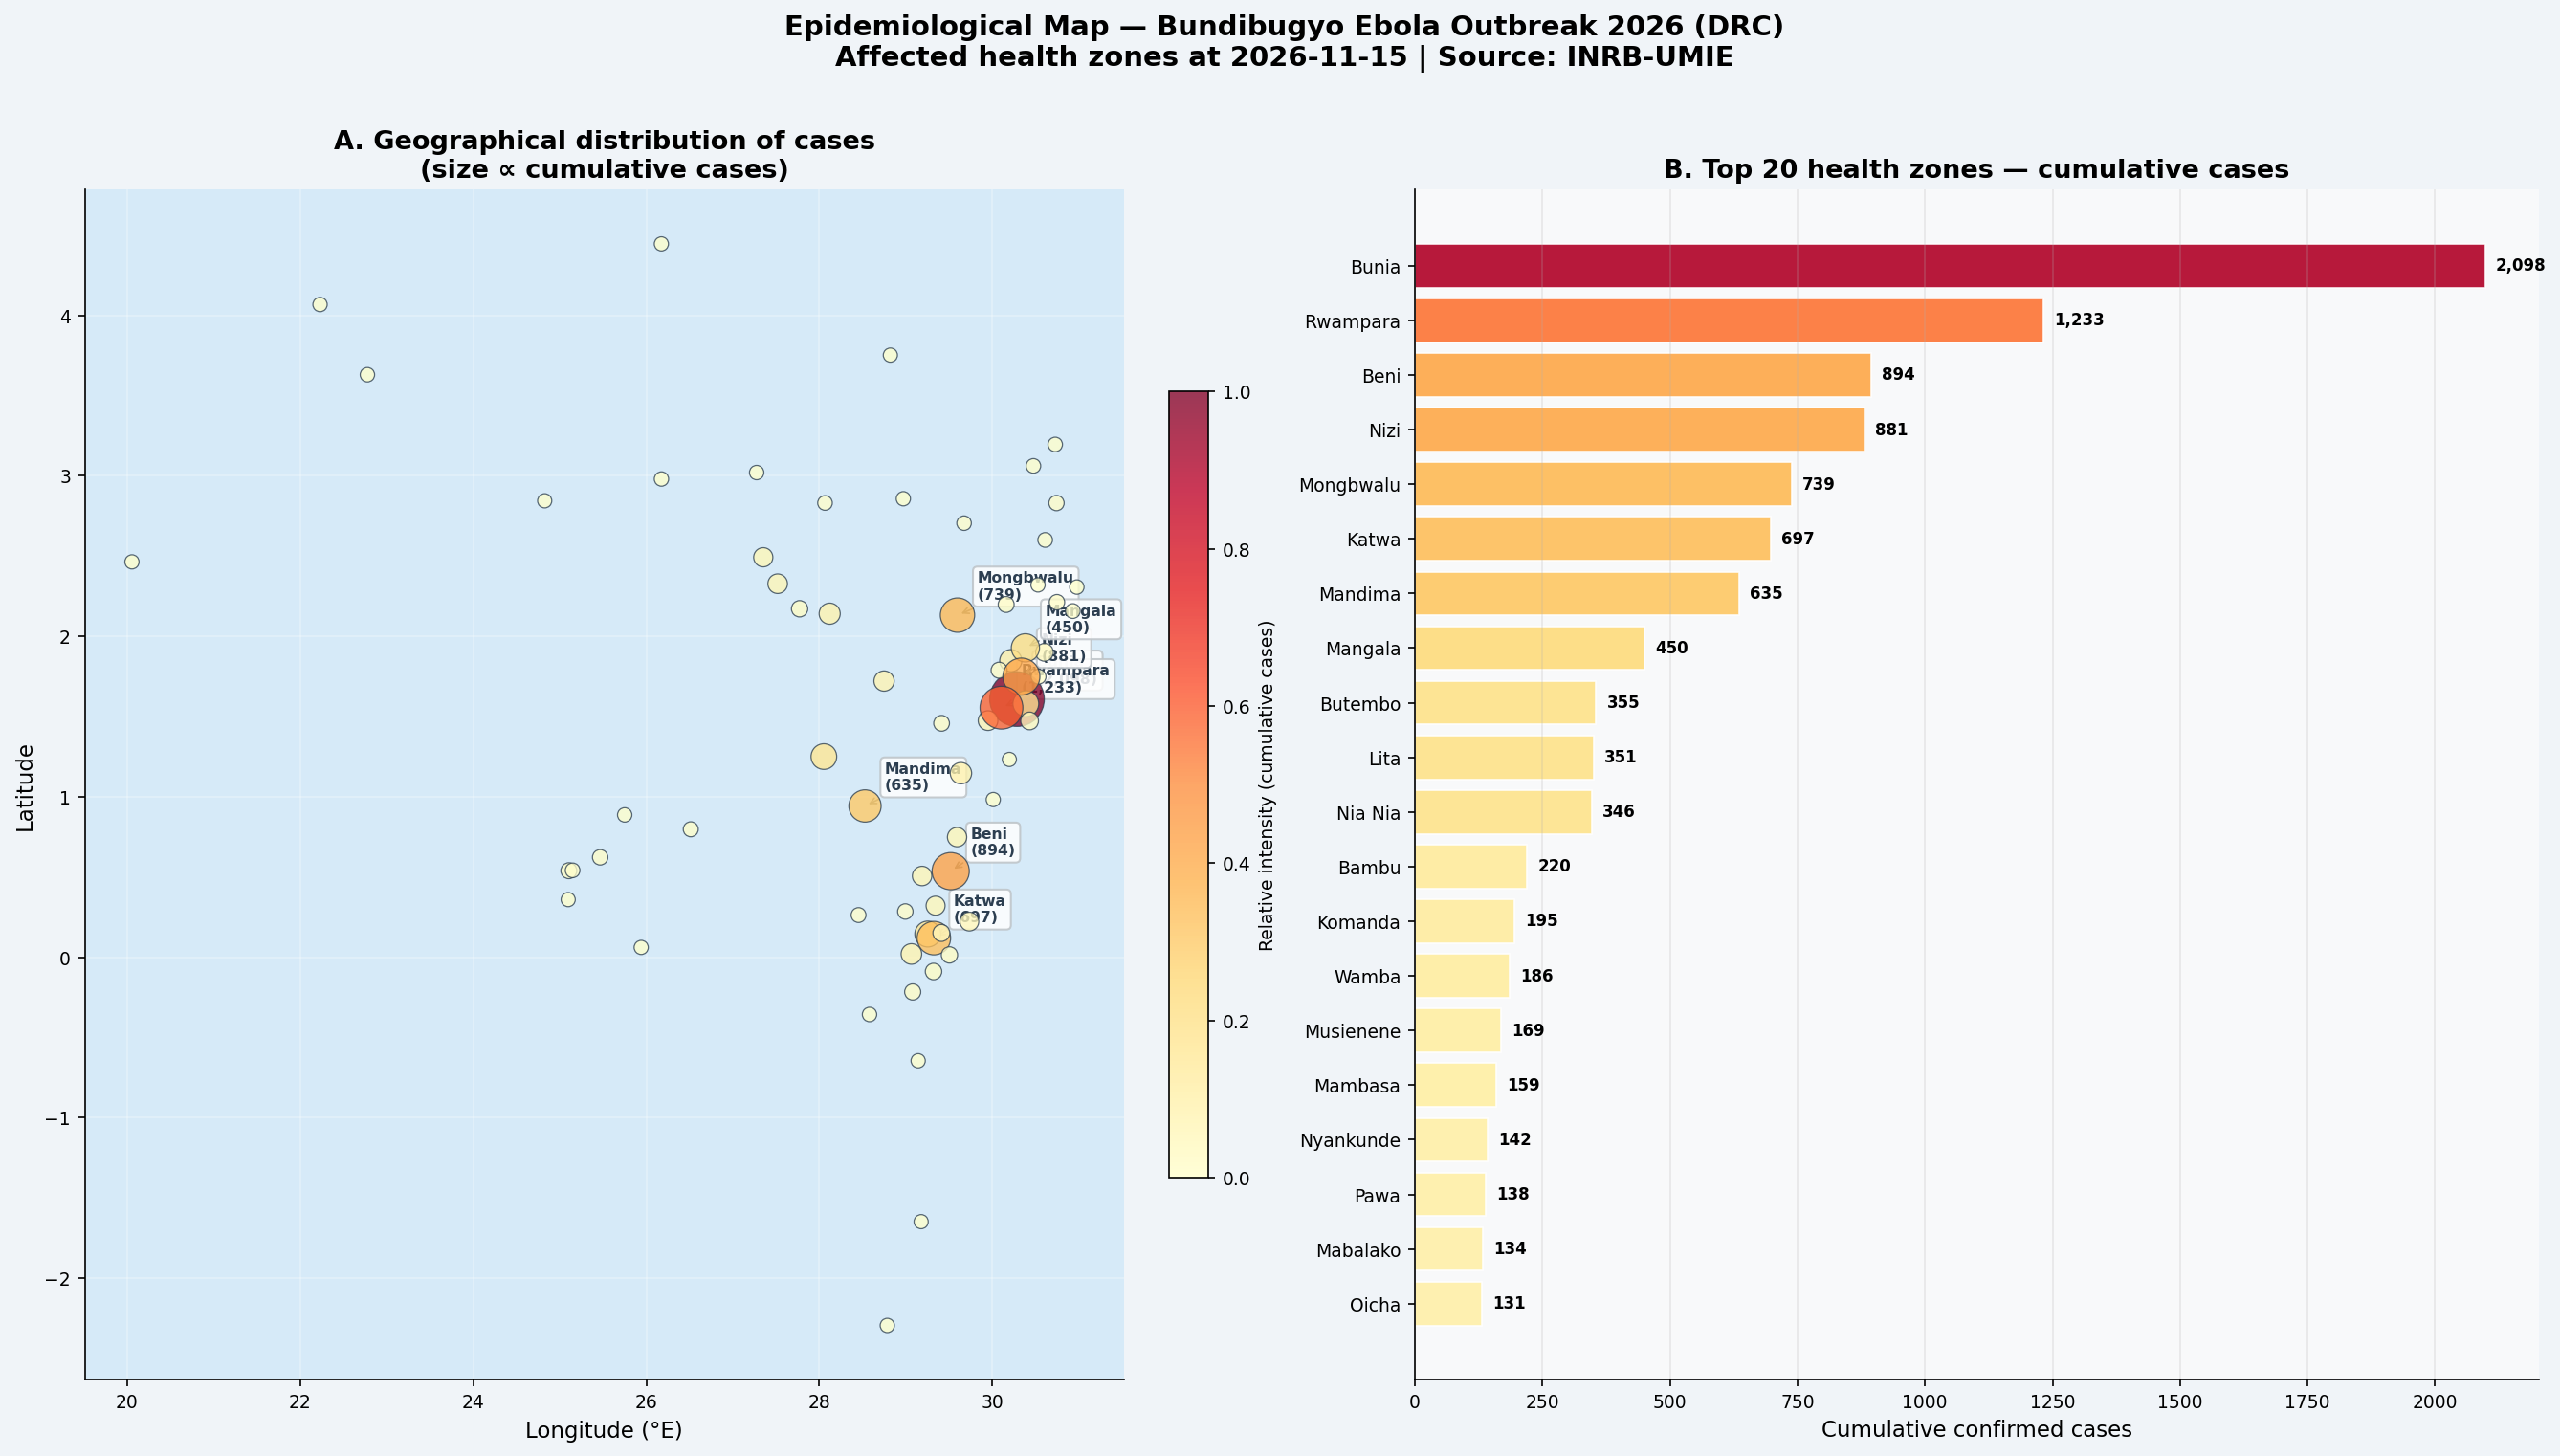

   Active zones: 68 | total cases (zones with coordinates): 11,422 | most affected: Bunia (2,098)
Saved figure: 14_drc_choropleth_map.png


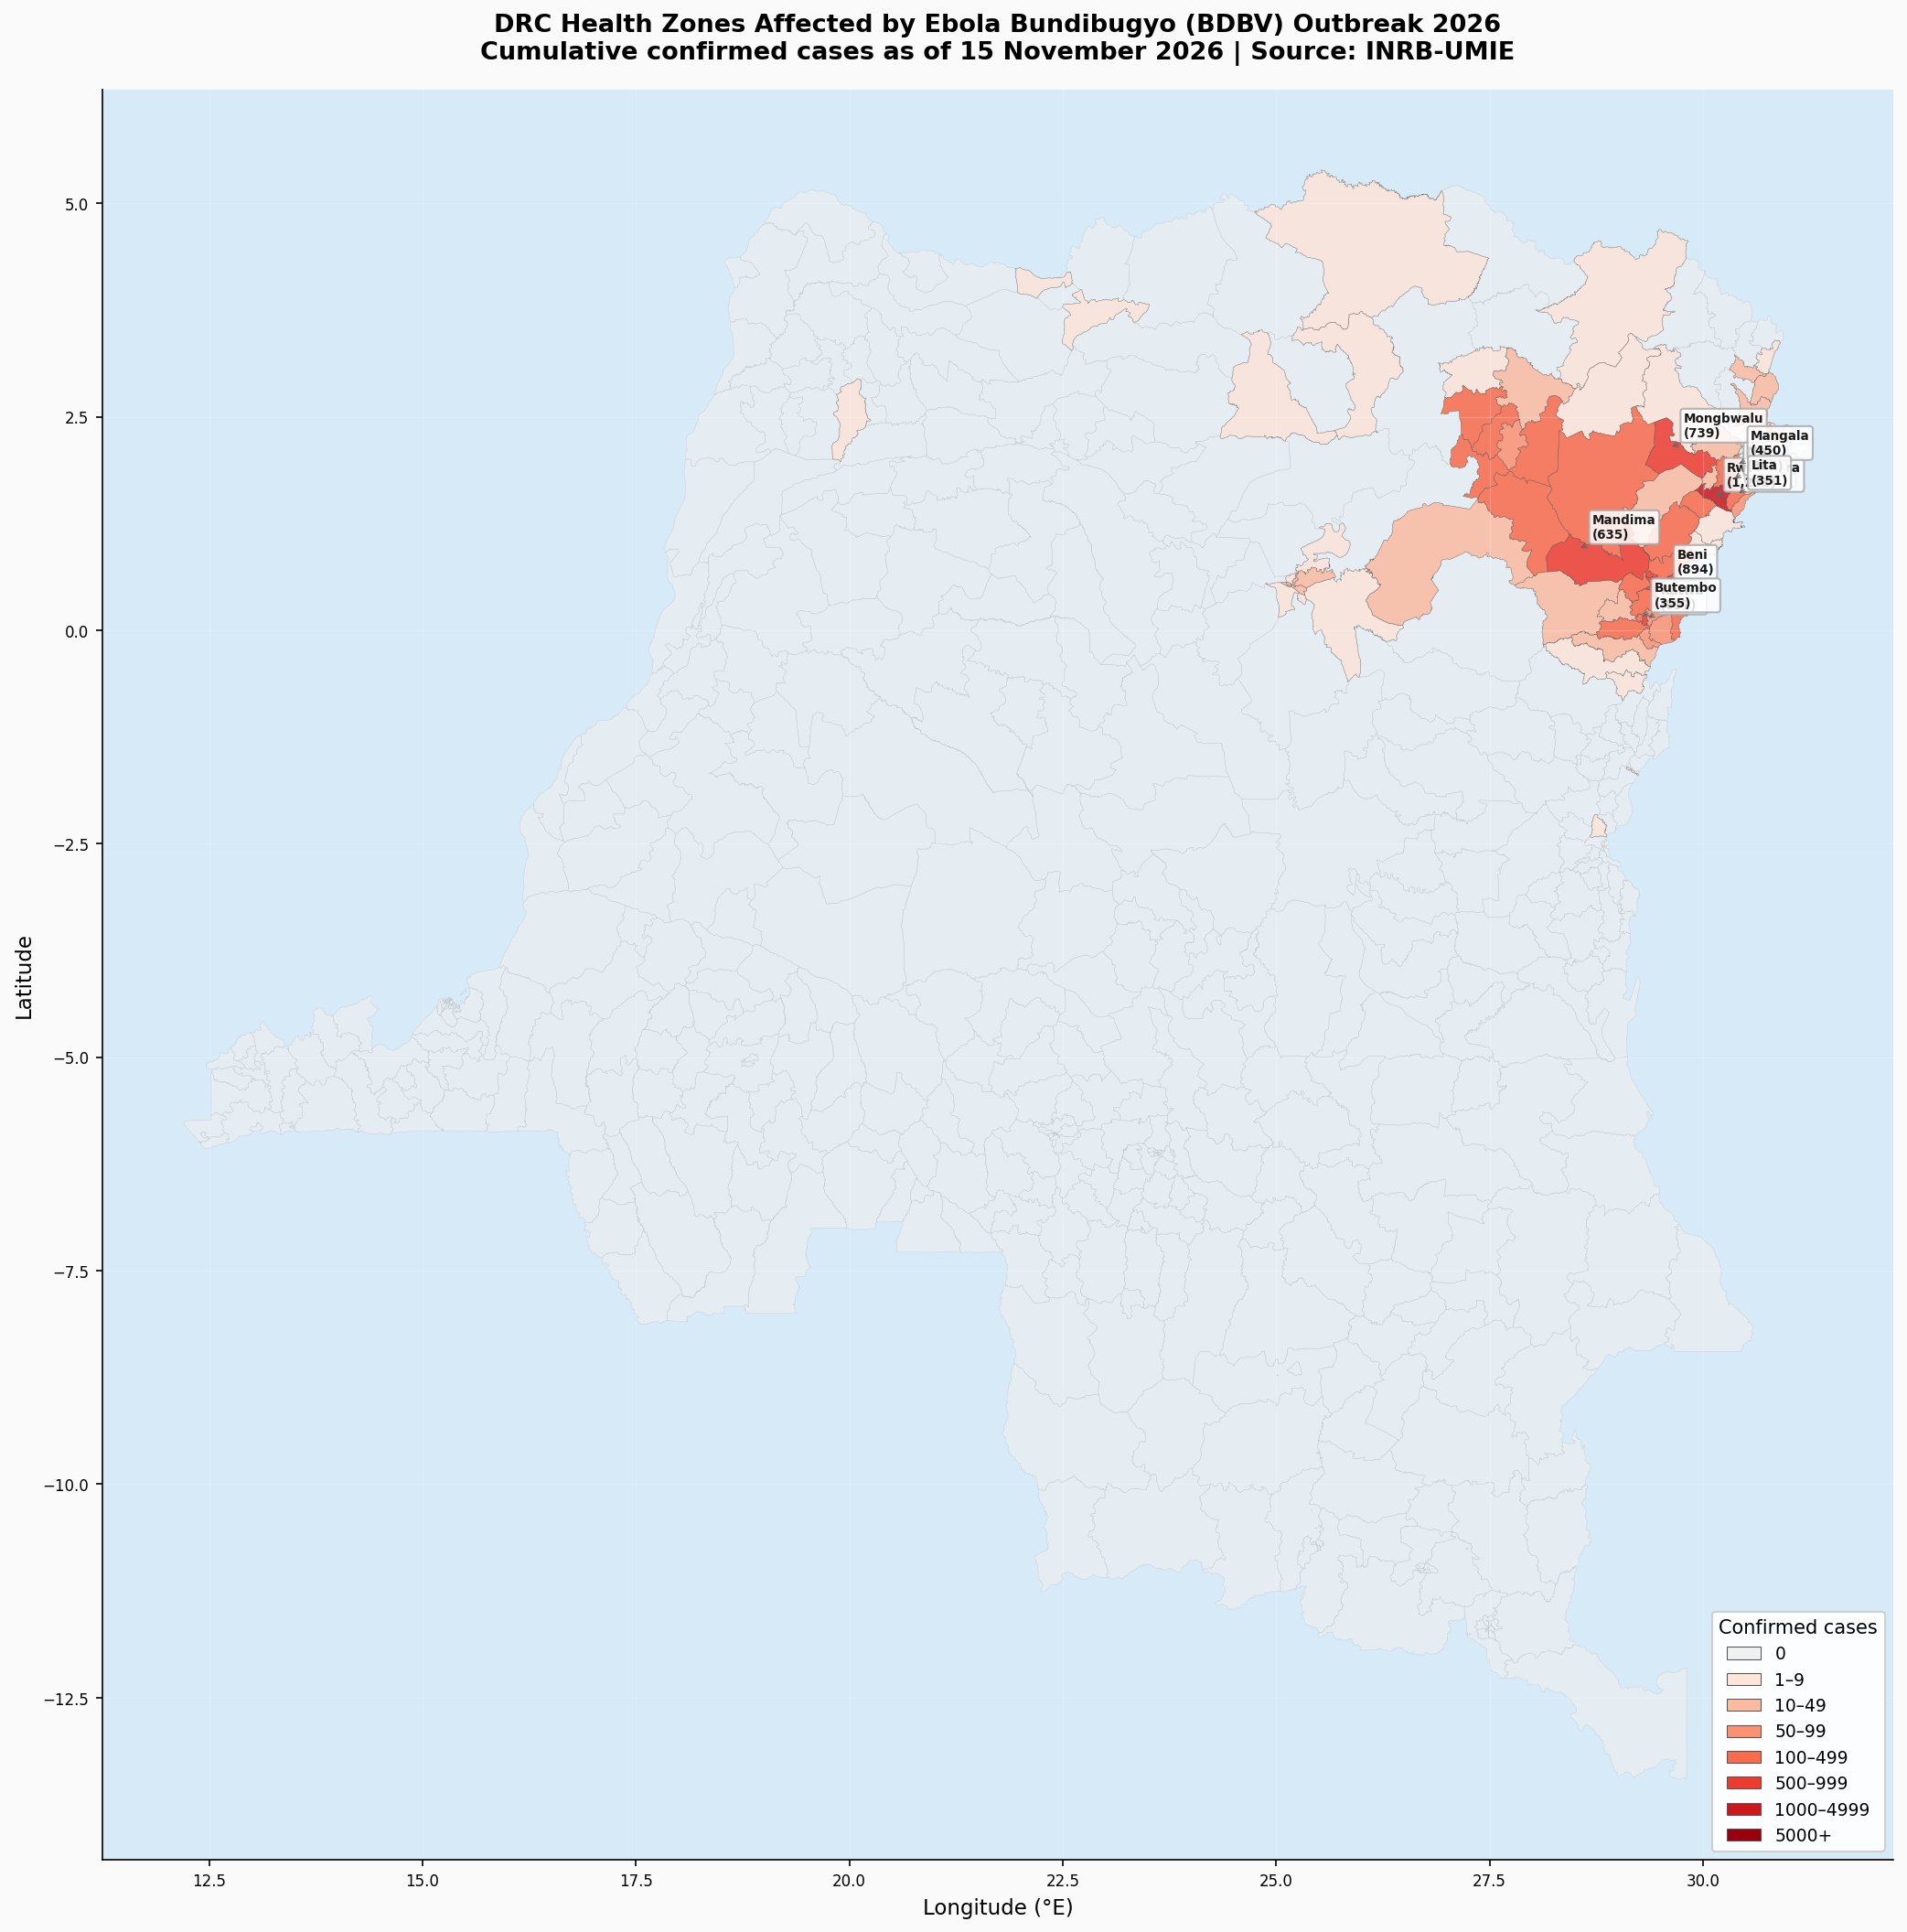

Interactive map saved: outputs\15_drc_interactive_map.html

── Zone statistics ───────────────────────────────────────────
   Total health zones (polygons): 519
   Affected zones               : 68 (13.1%)
   Case distribution:
            1–9 →  22 zones
          10–49 →  17 zones
          50–99 →   6 zones
        100–499 →  16 zones
        500–999 →   5 zones
      1000–4999 →   2 zones
   Top 10 most affected zones:
      1. Bunia                      2,098 cases
      2. Rwampara                   1,233 cases
      3. Beni                         894 cases
      4. Nizi                         881 cases
      5. Mongbwalu                    739 cases
      6. Katwa                        697 cases
      7. Mandima                      635 cases
      8. Mangala                      450 cases
      9. Butembo                      355 cases
     10. Lita                         351 cases
   Statistics exported: outputs\reports\zone_statistics.json

MAPPING COMPLETE


In [6]:
# ── Geographic mapping (real coordinates only)
# Approximate centroids (lat, lon). NOT verified: used only when no GeoJSON polygons are available.
ZONE_GEO = {
    'Butembo': (0.148, 29.293), 'Beni': (0.489, 29.473), 'Katwa': (0.193, 29.378), 'Mabalako': (-0.226, 29.452),
    'Musienene': (0.291, 29.215), 'Kalunguta': (1.231, 29.209), 'Vuhovi': (0.369, 29.326), 'Oicha': (0.706, 29.498),
    'Biena': (0.081, 29.145), 'Alimbongo': (0.850, 28.850), 'Lubero': (0.171, 29.254), 'Kayna': (-0.870, 28.830),
    'Rwangoma': (0.127, 29.345), 'Kyondo': (0.059, 29.119), 'Mutwanga': (0.562, 29.661),
    'Kanyabayonga': (-0.600, 28.720), 'Nyankunde': (1.420, 30.090), 'Manguredjipa': (0.495, 28.938),
    'Pinga': (-0.880, 27.600), 'Masisi': (-1.410, 28.820), 'Walikale': (-1.416, 28.039),
    'Rutshuru': (-1.183, 29.448), 'Kiwanja': (-1.046, 29.481),
    'Bunia': (1.561, 30.251), 'Mandima': (1.127, 27.875), 'Mambasa': (1.349, 28.938), 'Nia-Nia': (1.410, 27.590),
    'Komanda': (1.810, 29.730), 'Lolwa': (1.530, 28.750),
    'Lubutu': (-0.712, 26.585), 'Uvira': (-3.396, 29.138), 'Fizi': (-4.296, 29.110),
    'Bikoro': (-0.754, 18.144), 'Mbandaka': (0.047, 18.261),
}
BINS = [0, 1, 10, 50, 100, 500, 1000, 5000, np.inf]
LABELS = ['0', '1–9', '10–49', '50–99', '100–499', '500–999', '1000–4999', '5000+']
COLORS = ['#f0f0f0', '#fee5d9', '#fcbba1', '#fc9272', '#fb6a4a', '#ef3b2d', '#cb181d', '#99000d']
COLOR_MAP = dict(zip(LABELS, COLORS))


def norm_zone_name(s) -> str:
    """Accent-, case-, punctuation-insensitive key used to match zone names across files."""
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    s = re.sub(r'\b(zone de sante|health zone|zs|hz)\b', ' ', s)
    return re.sub(r'[^a-z0-9]', '', s)


def assign_category(val: float) -> str:
    if val <= 0:
        return '0'
    for i in range(1, len(BINS)):
        if val < BINS[i]:
            return LABELS[i - 1]
    return LABELS[-1]


def get_color(val: float) -> str:
    return COLOR_MAP[assign_category(val)]


def latest_cases_by_zone(data: Dict) -> pd.DataFrame:
    """Last known cumulative confirmed count per health zone (national aggregate excluded)."""
    df = data['cum_cases']
    df = df[df['zone'] != 'DRC'].sort_values('date')
    last = df.groupby('zone', as_index=False).agg(value=('value', 'last'), date=('date', 'max'))
    last['zone_key'] = last['zone'].map(norm_zone_name)
    return last


def find_geojson(cfg: Config) -> Optional[Path]:
    preferred = cfg.EXTRACT_DIR / 'build' / 'drc_health_zones.geojson'
    if preferred.exists():
        return preferred
    for p in cfg.EXTRACT_DIR.rglob('*.geojson'):
        return p
    return None


def load_shapefile(cfg: Config):
    """Load the DRC health-zone polygons. Returns a GeoDataFrame or None."""
    if not GEO_AVAILABLE:
        print("geopandas not available — no polygons")
        return None
    path = find_geojson(cfg)
    if path is None:
        print(f"GeoJSON not found under {cfg.EXTRACT_DIR} — using known centroids for points only")
        return None
    try:
        gdf = gpd.read_file(path)
        name_col = next((c for c in gdf.columns if str(c).lower() in ('nom', 'name', 'zone', 'zone_sante', 'zs', 'sante')),
                        next((c for c in gdf.columns if gdf[c].dtype == object or str(gdf[c].dtype).startswith('str')), gdf.columns[0]))
        gdf['zone_label'] = gdf[name_col].astype(str).str.strip()
        gdf['zone_key'] = gdf['zone_label'].map(norm_zone_name)
        print(f"GeoJSON loaded: {len(gdf)} health zones | name column: '{name_col}'")
        return gdf
    except Exception as e:
        print(f"GeoJSON load error: {e}")
        return None


def merge_geo_cases(gdf, cases: pd.DataFrame):
    """Attach case counts to polygons using normalised names. Returns (gdf_with_values, report).
    Duplicated polygon names are resolved with the province that holds most uniquely-matched zones."""
    gdf = gdf.copy()
    gdf['value'] = 0.0
    case_map = dict(zip(cases['zone_key'], cases['value']))
    key_to_case_zone = dict(zip(cases['zone_key'], cases['zone']))
    counts = gdf['zone_key'].value_counts()
    prov_rank: Dict[str, int] = {}
    if 'province' in gdf.columns:
        uniq = gdf[gdf['zone_key'].map(counts) == 1]
        for prov in uniq.loc[uniq['zone_key'].isin(case_map), 'province']:
            prov_rank[prov] = prov_rank.get(prov, 0) + 1
    selected: Dict[str, Any] = {}
    n_dup_resolved = 0
    for key, g in gdf.groupby('zone_key'):
        if key not in case_map:
            continue
        if len(g) == 1 or 'province' not in g.columns:
            selected[key] = g.index[0]
        else:
            selected[key] = g.assign(_r=g['province'].map(prov_rank).fillna(0)).sort_values('_r', ascending=False).index[0]
            n_dup_resolved += 1
    for key, idx in selected.items():
        gdf.loc[idx, 'value'] = float(case_map[key])
    gdf['zone_clean'] = gdf['zone_label']
    unmatched = sorted(cases.loc[~cases['zone_key'].isin(selected), 'zone'])
    n_matched_zones = int(len(cases) - len(unmatched))
    geoms = {key_to_case_zone[k]: gdf.loc[i, 'geometry'] for k, i in selected.items()}
    report = {'matched': n_matched_zones, 'unmatched': unmatched, 'duplicate_names_resolved': n_dup_resolved}
    print(f"Merge: {n_matched_zones} of {len(cases)} case zones matched to polygons | "
          f"{len(unmatched)} unmatched{': ' + ', '.join(unmatched[:12]) + (' …' if len(unmatched) > 12 else '') if unmatched else ''}"
          + (f" | {n_dup_resolved} duplicated polygon names resolved" if n_dup_resolved else ""))
    return gdf, report, geoms


def build_point_table(cases: pd.DataFrame, gdf_merged=None) -> pd.DataFrame:
    """Zone | value | lat | lon from polygon representative points, else from ZONE_GEO. No coordinates are invented."""
    rows, dropped = [], []
    if gdf_merged is not None:
        sub = gdf_merged[gdf_merged['value'] > 0]
        for _, r in sub.iterrows():
            pt = r.geometry.representative_point()
            rows.append({'zone_clean': r['zone_clean'], 'value': float(r['value']), 'lat': pt.y, 'lon': pt.x})
    else:
        for _, r in cases.iterrows():
            if r['zone'] in ZONE_GEO:
                lat, lon = ZONE_GEO[r['zone']]
                rows.append({'zone_clean': r['zone'], 'value': float(r['value']), 'lat': lat, 'lon': lon})
            elif r['value'] > 0:
                dropped.append(r['zone'])
    if dropped:
        print(f"{len(dropped)} zones have no known coordinates and are omitted from the map: "
              f"{', '.join(dropped[:12])}{' …' if len(dropped) > 12 else ''}")
    return pd.DataFrame(rows)


def plot_geo_points_map(points: pd.DataFrame, last_dt, cfg: Config) -> None:
    """Point map (size ∝ cumulative cases) + ranking of the top 20 zones."""
    if points.empty:
        print("No zone with coordinates — point map skipped")
        return
    fig, axes = plt.subplots(1, 2, figsize=(18, 10))
    fig.patch.set_facecolor('#F0F4F8')
    fig.suptitle(f"Epidemiological Map — Bundibugyo Ebola Outbreak 2026 (DRC)\n"
                 f"Affected health zones at {last_dt.date()} | Source: INRB-UMIE", fontsize=14, fontweight='bold', y=1.01)
    ax1 = axes[0]; ax1.set_facecolor('#D6EAF8')
    pts = points[points['value'] > 0].copy()
    norm = pts['value'] / max(pts['value'].max(), 1)
    sizes = np.clip(norm * 700 + 50, 30, 800)
    sc = ax1.scatter(pts['lon'], pts['lat'], c=norm, cmap='YlOrRd', vmin=0, vmax=1, s=sizes, alpha=0.78,
                     edgecolors='#2C3E50', linewidths=0.6, zorder=5)
    for _, r in pts.nlargest(8, 'value').iterrows():
        ax1.annotate(f"{r['zone_clean']}\n({int(r['value']):,})", xy=(r['lon'], r['lat']), xytext=(10, 8),
                     textcoords='offset points', fontsize=7.5, fontweight='bold', color='#2C3E50',
                     bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#BDC3C7', alpha=0.85),
                     arrowprops=dict(arrowstyle='->', color='#7F8C8D', lw=0.8))
    cbar = plt.colorbar(sc, ax=ax1, fraction=0.035, pad=0.04)
    cbar.set_label('Relative intensity (cumulative cases)', fontsize=9)
    ax1.set_xlabel('Longitude (°E)'); ax1.set_ylabel('Latitude')
    ax1.set_title('A. Geographical distribution of cases\n(size ∝ cumulative cases)', fontweight='bold')
    ax1.grid(True, alpha=0.3, color='white', lw=0.8)

    ax2 = axes[1]; ax2.set_facecolor('#F8F9FA')
    top20 = pts.nlargest(20, 'value').sort_values('value')
    cmap = plt.cm.YlOrRd
    bars = ax2.barh(top20['zone_clean'], top20['value'],
                    color=[cmap(v * 0.85 + 0.05) for v in top20['value'] / (top20['value'].max() + 1e-8)],
                    edgecolor='white', lw=0.8, alpha=0.9)
    for bar, val in zip(bars, top20['value']):
        ax2.text(bar.get_width() + top20['value'].max() * 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{int(val):,}", va='center', fontsize=8, fontweight='bold')
    ax2.set_title('B. Top 20 health zones — cumulative cases', fontweight='bold')
    ax2.set_xlabel('Cumulative confirmed cases'); ax2.grid(True, alpha=0.25, axis='x')
    plt.tight_layout()
    save_fig(fig, "13_geo_points_map.png")
    plt.show()
    top1 = pts.nlargest(1, 'value').iloc[0]
    print(f"   Active zones: {len(pts)} | total cases (zones with coordinates): {int(pts['value'].sum()):,} | "
          f"most affected: {top1['zone_clean']} ({int(top1['value']):,})")


def create_static_map(merged, last_date, use_polygons: bool, cfg: Config) -> None:
    """Publication-quality static choropleth (polygons) or proportional-point map."""
    m = merged.copy()
    m['category'] = m['value'].apply(assign_category)
    fig, ax = plt.subplots(1, 1, figsize=(14, 18))
    fig.patch.set_facecolor('#FAFAFA'); ax.set_facecolor('#D6EAF8')
    touched, untouched = m[m['value'] > 0], m[m['value'] == 0]
    if use_polygons:
        untouched.plot(ax=ax, color='#f0f0f0', edgecolor='#AAAAAA', linewidth=0.15, alpha=0.6)
        for label in LABELS[1:]:
            sub = touched[touched['category'] == label]
            if not sub.empty:
                sub.plot(ax=ax, color=COLOR_MAP[label], edgecolor='#555555', linewidth=0.2, alpha=0.85)
        for _, row in touched.nlargest(10, 'value').iterrows():
            try:
                c = row.geometry.representative_point()
                ax.annotate(f"{row['zone_clean']}\n({int(row['value']):,})", xy=(c.x, c.y), xytext=(8, 6),
                            textcoords='offset points', fontsize=6.5, fontweight='bold', color='#1A1A1A',
                            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#AAAAAA', alpha=0.85),
                            arrowprops=dict(arrowstyle='->', color='#666666', lw=0.6))
            except Exception:
                pass
        ax.legend(handles=[Patch(facecolor=COLOR_MAP[l], edgecolor='#555555', linewidth=0.5, label=l) for l in LABELS],
                  title='Confirmed cases', title_fontsize=10, fontsize=9, loc='lower right', frameon=True, framealpha=0.92)
    else:
        mx = max(touched['value'].max(), 1) if len(touched) else 1
        sc = ax.scatter(touched['lon'], touched['lat'], c=touched['value'], cmap='YlOrRd',
                        s=np.clip(touched['value'] / mx * 600 + 40, 40, 700), alpha=0.8, edgecolors='#333333',
                        linewidths=0.5, zorder=5)
        plt.colorbar(sc, ax=ax, fraction=0.03, pad=0.02, label='Cumulative confirmed cases')
        for _, row in touched.nlargest(8, 'value').iterrows():
            ax.annotate(f"{row['zone_clean']}\n({int(row['value']):,})", xy=(row['lon'], row['lat']), xytext=(10, 8),
                        textcoords='offset points', fontsize=7, fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#AAAAAA', alpha=0.88),
                        arrowprops=dict(arrowstyle='->', color='#888888', lw=0.7))
    ax.set_title(f"DRC Health Zones Affected by Ebola Bundibugyo (BDBV) Outbreak 2026\n"
                 f"Cumulative confirmed cases as of {last_date.strftime('%d %B %Y')} | Source: INRB-UMIE",
                 fontsize=13, fontweight='bold', pad=16)
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude'); ax.tick_params(labelsize=8)
    ax.grid(True, alpha=0.2, color='white', lw=0.6)
    plt.tight_layout()
    save_fig(fig, "14_drc_choropleth_map.png")
    plt.show()


def create_interactive_map(merged, last_date, use_polygons: bool, cfg: Config) -> None:
    """Interactive Folium map (polygons or markers)."""
    try:
        import folium
    except ImportError:
        print("folium not installed — interactive map skipped (pip install folium)")
        return
    center = [0.0, 29.0] if use_polygons else [float(merged['lat'].mean()), float(merged['lon'].mean())]
    m = folium.Map(location=center, zoom_start=7 if use_polygons else 6, tiles='CartoDB positron')
    title = (f"<div style='position:fixed;top:10px;left:50%;transform:translateX(-50%);background:white;padding:10px 20px;"
             f"border-radius:8px;box-shadow:2px 2px 6px rgba(0,0,0,.3);z-index:1000;font-family:Arial;font-size:13px;"
             f"font-weight:bold;text-align:center;'>DRC — Ebola Bundibugyo 2026<br><span style='font-size:10px;font-weight:normal;'>"
             f"Cumulative confirmed cases per health zone — {last_date.strftime('%d %B %Y')}</span></div>")
    m.get_root().html.add_child(folium.Element(title))
    if use_polygons:
        for _, row in merged.iterrows():
            if row.geometry is None:
                continue
            cases = float(row['value']); color = get_color(cases)
            folium.GeoJson(row.geometry.__geo_interface__,
                           style_function=lambda x, c=color, cs=cases: {'fillColor': c, 'color': '#333333', 'weight': 0.5,
                                                                        'fillOpacity': 0.82 if cs > 0 else 0.25},
                           tooltip=folium.Tooltip(f"{row['zone_clean']}: {int(cases):,} cases"),
                           popup=folium.Popup(f"<b>Health zone:</b> {row['zone_clean']}<br><b>Cumulative cases:</b> {int(cases):,}",
                                              max_width=260)).add_to(m)
    else:
        mx = max(merged['value'].max(), 1)
        for _, row in merged[merged['value'] > 0].iterrows():
            cases = float(row['value'])
            folium.CircleMarker(location=[row['lat'], row['lon']], radius=max(5, min(22, cases / mx * 20 + 4)),
                                color=get_color(cases), fill=True, fill_color=get_color(cases), fill_opacity=0.75,
                                tooltip=folium.Tooltip(f"{row['zone_clean']}: {int(cases):,} cases")).add_to(m)
    items = "".join(f"<p style='margin:0'><span style='background:{c};padding:2px 10px;'>&nbsp;&nbsp;</span> {l}</p>"
                    for l, c in COLOR_MAP.items())
    m.get_root().html.add_child(folium.Element(
        f"<div style='position:fixed;bottom:40px;right:40px;border:1.5px solid #888;z-index:9999;background:white;"
        f"padding:12px;border-radius:6px;font-size:11px;font-family:Arial;'><p style='margin:0 0 6px;font-weight:bold;'>"
        f"Confirmed cases</p>{items}</div>"))
    folium.LayerControl().add_to(m)
    out = cfg.OUTPUT_DIR / "15_drc_interactive_map.html"
    m.save(str(out))
    print(f"Interactive map saved: {out}")


def generate_zone_statistics(table: pd.DataFrame, last_date, total_zones: Optional[int], cfg: Config) -> Dict:
    """Zone-level statistics (table: zone_clean | value)."""
    touched = table[table['value'] > 0]
    print("\n── Zone statistics ───────────────────────────────────────────")
    if total_zones:
        print(f"   Total health zones (polygons): {total_zones}")
        print(f"   Affected zones               : {len(touched)} ({len(touched) / total_zones * 100:.1f}%)")
    else:
        print(f"   Affected zones (in case data): {len(touched)}")
    print("   Case distribution:")
    for i in range(1, len(BINS)):
        n = int(((touched['value'] >= BINS[i - 1]) & (touched['value'] < BINS[i])).sum())
        if n:
            print(f"     {LABELS[i - 1]:>10} → {n:3d} zones")
    top10 = touched.nlargest(10, 'value')
    print("   Top 10 most affected zones:")
    for rank, (_, r) in enumerate(top10.iterrows(), 1):
        print(f"     {rank:2d}. {r['zone_clean']:<25} {int(r['value']):>6,} cases")
    out = {'total_zones': int(total_zones) if total_zones else None, 'affected_zones': int(len(touched)),
           'last_update': last_date.strftime('%Y-%m-%d'),
           'top10_zones': [{'rank': i + 1, 'zone': r['zone_clean'], 'cases': int(r['value'])}
                           for i, (_, r) in enumerate(top10.iterrows())]}
    with open(cfg.REPORT_DIR / "zone_statistics.json", 'w', encoding='utf-8') as f:
        json.dump(out, f, indent=2, ensure_ascii=False)
    print(f"   Statistics exported: {cfg.REPORT_DIR / 'zone_statistics.json'}")
    return out


# ── Run the mapping pipeline 
print("=" * 68)
print("DRC HEALTH ZONE MAP — EBOLA BUNDIBUGYO OUTBREAK 2026")
print("=" * 68)
CASES_BY_ZONE = latest_cases_by_zone(DATA)
MAP_LAST_DATE = DATA['cum_cases']['date'].max()
GEO_GDF = load_shapefile(CFG)          # polygons (or None)
GEO_ZONE_GEOMS: Dict[str, Any] = {}    # case-zone name -> polygon (used by the GNN adjacency)
GEO_REPORT: Dict[str, Any] = {}
_merged_poly = None
if GEO_GDF is not None:
    _merged_poly, GEO_REPORT, GEO_ZONE_GEOMS = merge_geo_cases(GEO_GDF, CASES_BY_ZONE)

POINTS = build_point_table(CASES_BY_ZONE, _merged_poly)
if len(POINTS):
    plot_geo_points_map(POINTS, MAP_LAST_DATE, CFG)

if GEO_AVAILABLE and _merged_poly is not None:
    create_static_map(_merged_poly, MAP_LAST_DATE, True, CFG)
    create_interactive_map(_merged_poly, MAP_LAST_DATE, True, CFG)
    ZONE_STATS = generate_zone_statistics(_merged_poly[['zone_clean', 'value']], MAP_LAST_DATE, len(_merged_poly), CFG)
elif GEO_AVAILABLE and len(POINTS):
    create_static_map(POINTS, MAP_LAST_DATE, False, CFG)
    create_interactive_map(POINTS, MAP_LAST_DATE, False, CFG)
    ZONE_STATS = generate_zone_statistics(POINTS[['zone_clean', 'value']], MAP_LAST_DATE, None, CFG)
else:
    ZONE_STATS = generate_zone_statistics(CASES_BY_ZONE.rename(columns={'zone': 'zone_clean'})[['zone_clean', 'value']],
                                          MAP_LAST_DATE, None, CFG)
print("\n" + "=" * 68 + "\nMAPPING COMPLETE\n" + "=" * 68)

## MODULE 3 · Transfer Learning from Real Historical Outbreaks

Sources (West Africa 2014-16, North Kivu 2018, Uganda 2022 when available) are converted to the **same representation as the 2026 target: weekly new cases per zone**. A univariate series model is pre-trained on them with a *local* normalisation (log-scale divided by the window maximum) so that the input space is **identical** in pre-training and fine-tuning. Put the files in `historical_data/` (sub-folders allowed); file names are matched with the patterns of `CFG.HISTORICAL_OUTBREAKS`, or set `['path']` explicitly. Supported layouts include period-wide tables (e.g. the North Kivu 2018–2020 epi-week table: periods of irregular length are spread over days, only *confirmed* cases are kept, negative reclassifications are absorbed) and files containing several separate outbreaks (e.g. Uganda 2022 and 2025: the largest segment is kept and the others are reported).

In [7]:
# MODULE 3.1 · Loaders for historical outbreak files (any common layout → weekly new cases per zone)
# Supported layouts: aggregated counts (cumulative or incident), long "indicator | country | date | value" files,
# wide tables (date + one column per zone), period-wide tables (one column per reporting period such as
# '5 Aug 2018 - 12 Aug 2018', rows = zones x case definition) and individual line lists (one row per case).
# A file holding several separate outbreaks (e.g. Uganda 2022 and 2025) is split at silent gaps; the largest is kept.
# ═══════════════════════════════════════════════════════════════════
HIST_TOTAL = '__total__'
DATE_PREFER = ('onset', 'confirm', 'report', 'notif')
ZONE_PREFER = ('healthzone', 'zonedesante', 'zone', 'district', 'adminarealevel2', 'admin2',
               'location', 'area', 'province', 'region', 'country')
DEFAULT_CASE_REGEXES = [r'cumul.*confirm.*(cas|case)', r'confirm.*(cas|case)', r'cumul.*(cas|case)', r'(cas|case)']
HARD_EXCLUDE = r'death|deces|décès|mort|recover|gueri|guéri|contact|sample|test|bed|hcw|health.?care'
SOFT_EXCLUDE = r'suspect|probable'
VALUE_NAMES = ('value', 'valeur', 'cases', 'cas', 'count', 'n', 'nombre', 'nouveauxcas', 'newcases', 'incidence')


def read_table(path) -> pd.DataFrame:
    """Read CSV (delimiter auto-detected for small files), compressed CSV or Excel."""
    path = Path(path)
    if path.name.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path)
    err = None
    for enc in ('utf-8', 'utf-8-sig', 'latin-1'):
        try:
            if path.stat().st_size < 5_000_000:
                return pd.read_csv(path, encoding=enc, sep=None, engine='python')   # sniff ',', ';', tab
            return pd.read_csv(path, encoding=enc, low_memory=False)
        except UnicodeDecodeError as e:
            err = e
    raise err


def _norm_col(s) -> str:
    return re.sub(r'[^a-z0-9]', '', str(s).lower())


def _is_text(s: pd.Series) -> bool:
    return not (pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s))


def parse_dates_flexible(s: pd.Series) -> pd.Series:
    """ISO / day-first dates, plus ISO-week strings such as '2018-W32'."""
    out = parse_dates_series(s)
    if out.notna().mean() < 0.6:
        m = s.astype(str).str.strip().str.extract(r'^(\d{4})\D{0,2}[Ww](\d{1,2})$')
        if m.notna().all(axis=1).mean() > 0.6:
            def _iso(y, w):
                try:
                    return pd.Timestamp(datetime.fromisocalendar(int(y), int(w), 1))
                except Exception:
                    return pd.NaT
            alt = pd.Series([_iso(y, w) if pd.notna(y) else pd.NaT for y, w in zip(m[0], m[1])], index=s.index)
            out = out.fillna(alt)
    return out


def add_date_from_year_week(df: pd.DataFrame) -> Optional[str]:
    """If the table has numeric year and week columns, add '_date' (Monday of the ISO week)."""
    nm = {c: _norm_col(c) for c in df.columns}
    yc = next((c for c, n in nm.items() if n in ('year', 'annee', 'epiyear') and pd.api.types.is_numeric_dtype(df[c])), None)
    wc = next((c for c, n in nm.items() if n in ('week', 'semaine', 'epiweek', 'weekno', 'semaineepi', 'epiweekno')
               and pd.api.types.is_numeric_dtype(df[c])), None)
    if yc is None or wc is None:
        return None
    def _iso(y, w):
        try:
            return pd.Timestamp(datetime.fromisocalendar(int(y), int(w), 1))
        except Exception:
            return pd.NaT
    df['_date'] = [_iso(y, w) for y, w in zip(df[yc], df[wc])]
    return '_date'


def guess_columns(df: pd.DataFrame) -> Dict[str, Optional[str]]:
    """Heuristic guess of the date / zone / status / value / indicator columns."""
    cols = list(df.columns)
    nm = {c: _norm_col(c) for c in cols}
    out: Dict[str, Optional[str]] = dict(date=None, zone=None, status=None, value=None, indicator=None)

    scored = {}
    for c in cols:
        if not any(h in nm[c] for h in ('date', 'week', 'semaine', 'period') + DATE_PREFER):
            continue
        s = df[c].dropna()
        if s.empty or pd.api.types.is_numeric_dtype(s):
            continue
        ratio = parse_dates_flexible(s.astype(str).head(300)).notna().mean()
        if ratio >= 0.6:
            scored[c] = ratio
    for hint in DATE_PREFER:
        hit = [c for c in scored if hint in nm[c]]
        if hit:
            out['date'] = hit[0]
            break
    if out['date'] is None and scored:
        out['date'] = max(scored, key=scored.get)

    for hint in ZONE_PREFER:
        for c in cols:
            if hint in nm[c] and c != out['date'] and _is_text(df[c]) and 2 <= df[c].nunique() <= 1000:
                out['zone'] = c
                break
        if out['zone']:
            break

    for c in cols:
        if out['status'] is None and any(h in nm[c] for h in ('status', 'classification', 'casedef', 'statut')) \
                and _is_text(df[c]) and 1 <= df[c].nunique() <= 12:
            out['status'] = c
        if out['indicator'] is None and nm[c] in ('indicator', 'indicateur', 'variable', 'series', 'metric'):
            out['indicator'] = c
        if out['value'] is None and pd.api.types.is_numeric_dtype(df[c]) and \
                (nm[c] in VALUE_NAMES or nm[c].endswith(('cases', 'cas')) or nm[c].startswith(('nouveau', 'new'))):
            out['value'] = c
    return out


def inspect_table(df: pd.DataFrame, n: int = 3) -> Dict[str, Optional[str]]:
    """Print columns, a few values and the guessed roles (diagnostic helper)."""
    print(f"   {len(df):,} rows x {df.shape[1]} columns")
    for c in df.columns:
        sample = df[c].dropna().astype(str).unique()[:n].tolist()
        print(f"     {str(c)[:40]:40s} {str(df[c].dtype):10s} nunique={df[c].nunique():<6} e.g. {sample}")
    g = guess_columns(df)
    print(f"   guessed roles: {g}")
    return g


def _week_label(dates: pd.Series) -> pd.Series:
    """Week label = the Sunday that ends the Monday–Sunday week (same convention as the 2026 data)."""
    return dates.dt.to_period('W-SUN').dt.end_time.dt.normalize()


def select_indicator(df: pd.DataFrame, ind_col: str, regexes=None) -> List[str]:
    """Pick the case-count indicator(s) of a long file (confirmed cases preferred; deaths etc. excluded)."""
    inds = pd.Series(df[ind_col].dropna().astype(str).unique())
    regs = ([regexes] if isinstance(regexes, str) else list(regexes)) if regexes else DEFAULT_CASE_REGEXES
    pools = (inds[~inds.str.contains(HARD_EXCLUDE + '|' + SOFT_EXCLUDE, case=False, regex=True)],
             inds[~inds.str.contains(HARD_EXCLUDE, case=False, regex=True)])
    for pool in pools:
        for rg in regs:
            hit = pool[pool.str.contains(rg, case=False, regex=True)].tolist()
            if hit:
                return hit
    raise ValueError("no case indicator found. Available: " + "; ".join(inds.tolist()[:25]))


def infer_cumulative(long_df: pd.DataFrame, label: str = '') -> bool:
    """Cumulative vs incident counts: by name first, then by monotonicity of the per-zone series."""
    lab = label.lower()
    if re.search(r'cumul|\bcum\b|total', lab):
        return True
    if re.search(r'\bnew\b|nouveau|weekly|hebdo|incid|daily', lab):
        return False
    ok, n = 0.0, 0
    for _, g in long_df.sort_values('date').groupby('zone'):
        d = g['value'].diff().dropna()
        if len(d) >= 3:
            ok += float((d >= -1e-9).mean())
            n += 1
    return bool(n and ok / n >= 0.97)


def counts_to_weekly(long_df: pd.DataFrame, cumulative: bool) -> pd.DataFrame:
    """zone | date | value (cumulative or incident, any resolution) -> weekly new cases per zone."""
    d = long_df.dropna(subset=['date', 'value']).copy()
    d['week'] = _week_label(d['date'])
    wk = d.groupby(['zone', 'week'])['value'].agg('max' if cumulative else 'sum').reset_index()
    frames = []
    for z, g in wk.groupby('zone'):
        g = g.set_index('week')['value'].sort_index()
        s = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq='7D'))
        if cumulative:
            s = s.ffill().cummax()
            new = s.diff()
            new.iloc[0] = s.iloc[0]
        else:
            new = s.fillna(0.0)
        frames.append(pd.DataFrame({'zone': z, 'date': new.index, 'value': new.clip(lower=0).to_numpy(float)}))
    return pd.concat(frames, ignore_index=True)


def linelist_to_weekly(df: pd.DataFrame, date_col: str, zone_col: Optional[str] = None,
                       status_col: Optional[str] = None, keep_status: Optional[Sequence[str]] = None) -> pd.DataFrame:
    """One row per case -> weekly new cases per zone (zero-filled until the last week of the outbreak)."""
    d = df.copy()
    d['_date'] = parse_dates_flexible(d[date_col])
    d = d.dropna(subset=['_date'])
    if status_col and keep_status:
        keep = {k.lower() for k in keep_status}
        d = d[d[status_col].astype(str).str.strip().str.lower().isin(keep)]
    if d.empty:
        raise ValueError("no rows left after date/status filtering")
    d['_zone'] = d[zone_col].fillna('Unknown').astype(str).str.strip() if zone_col else 'ALL'
    d['_week'] = _week_label(d['_date'])
    wk = d.groupby(['_zone', '_week']).size().rename('value').reset_index()
    last = wk['_week'].max()
    frames = []
    for z, g in wk.groupby('_zone'):
        g = g.set_index('_week')['value']
        idx = pd.date_range(g.index.min(), last, freq='7D')
        frames.append(pd.DataFrame({'zone': z, 'date': idx, 'value': g.reindex(idx, fill_value=0).to_numpy(float)}))
    return pd.concat(frames, ignore_index=True)


def add_total_series(weekly: pd.DataFrame, total_name: str = HIST_TOTAL) -> pd.DataFrame:
    """Append the sum over zones as an extra series (no-op when there is a single zone)."""
    base = weekly[weekly['zone'] != total_name]
    if base['zone'].nunique() < 2:
        return base.reset_index(drop=True)
    tot = base.groupby('date', as_index=False)['value'].sum()
    tot['zone'] = total_name
    return pd.concat([base, tot[['zone', 'date', 'value']]], ignore_index=True)


def parse_period_columns(columns) -> List[Tuple[Any, pd.Timestamp]]:
    """Columns named like '5 Aug 2018 - 12 Aug 2018' or 'unknown - 5 August 2018' -> [(column, end date)] sorted by end date."""
    out = []
    for c in columns:
        m = re.match(r'^(.*?)\s+[-–—]\s+(.+)$', str(c).strip())
        if not m:
            continue
        end = pd.to_datetime(m.group(2), errors='coerce', format='mixed', dayfirst=True)
        if pd.notna(end):
            out.append((c, end))
    return sorted(out, key=lambda t: t[1])


def promote_header_row(df: pd.DataFrame, period_names: List[Any]) -> pd.DataFrame:
    """Some exports keep the real column labels in the first data row ('Unnamed: 1' -> 'Location').
    Applied only when that row is empty in all period columns."""
    row0 = df.iloc[0]
    if not row0[period_names].isna().all():
        return df
    ren = {c: str(row0[c]).strip() for c in df.columns
           if str(c).startswith('Unnamed') and isinstance(row0[c], str) and row0[c].strip()}
    if not ren:
        return df
    out = df.rename(columns=ren).iloc[1:].reset_index(drop=True)
    first = out.columns[0]
    if not pd.api.types.is_numeric_dtype(out[first]):
        out[first] = out[first].ffill()                     # province label written only on its first row
    return out


def periodwide_to_weekly(df: pd.DataFrame, period_cols, zone_col: str, status_col: Optional[str],
                         keep_status: Optional[Sequence[str]]) -> pd.DataFrame:
    """Rows = zones (x case definition), columns = reporting periods of irregular length.
    Each period count is spread evenly over the days of the period (previous end, end], then summed by week.
    Negative cells (reclassifications) are absorbed through the cumulative series: net totals are preserved and
    weekly values are never negative."""
    d = df.copy()
    if status_col and keep_status:
        keep = {k.lower() for k in keep_status}
        d = d[d[status_col].astype(str).str.strip().str.lower().isin(keep)]
    d = d.dropna(subset=[zone_col])
    d = d[~d[zone_col].astype(str).str.contains(r'^\s*(total|grand\s*total|sous.?total)', case=False, regex=True)]
    if d.empty:
        raise ValueError("no zone rows left after filtering (check keep_status / zone column)")
    d['_zone'] = d[zone_col].astype(str).str.strip()
    cols = [c for c, _ in period_cols]
    num = d[cols].apply(pd.to_numeric, errors='coerce').fillna(0.0)
    num['_zone'] = d['_zone'].to_numpy()
    by_zone = num.groupby('_zone').sum()
    acc: Dict[Tuple[str, pd.Timestamp], float] = {}
    prev_end = None
    for col, end in period_cols:
        start = end if prev_end is None else prev_end + pd.Timedelta(days=1)
        days = pd.date_range(start, end, freq='D')
        if len(days) == 0:                                   # unsorted/duplicate period: attribute to its end day
            days = pd.DatetimeIndex([end])
        weeks, counts = np.unique(_week_label(pd.Series(days)).to_numpy(), return_counts=True)
        for z, v in by_zone[col].items():
            if v != 0:
                for w, c in zip(weeks, counts):
                    acc[(z, pd.Timestamp(w))] = acc.get((z, pd.Timestamp(w)), 0.0) + v * c / len(days)
        prev_end = end
    inc = pd.DataFrame([(z, w, v) for (z, w), v in acc.items()], columns=['zone', 'date', 'value'])
    last = inc['date'].max()
    frames = []
    for z, g in inc.groupby('zone'):
        g = g.set_index('date')['value'].sort_index()
        idx = pd.date_range(g.index.min(), last, freq='7D')
        cum = np.maximum.accumulate(np.r_[0.0, np.cumsum(g.reindex(idx, fill_value=0.0).to_numpy())])[1:]
        new = np.diff(np.r_[0.0, cum])
        frames.append(pd.DataFrame({'zone': z, 'date': idx, 'value': np.clip(new, 0, None)}))
    return pd.concat(frames, ignore_index=True)


def keep_main_segment(weekly: pd.DataFrame, name: str, gap_weeks: int = 12) -> pd.DataFrame:
    """A file can hold several separate outbreaks (e.g. Uganda 2022 and 2025). Series are split at silent gaps of more
    than `gap_weeks` weeks and only the segment with the most cases is kept (the others are reported)."""
    base = weekly[weekly['zone'] != HIST_TOTAL]
    tot = base.groupby('date')['value'].sum().sort_index()
    tot = tot.reindex(pd.date_range(tot.index.min(), tot.index.max(), freq='7D'), fill_value=0.0)
    nz = tot[tot > 0].index
    if len(nz) < 2:
        return weekly
    gaps = (np.diff(nz.values).astype('timedelta64[D]').astype(int)) // 7
    cuts = [i for i, g in enumerate(gaps) if g > gap_weeks]
    if not cuts:
        return weekly
    bounds, start = [], 0
    for c in cuts + [len(nz) - 1]:
        bounds.append((nz[start], nz[c]))
        start = c + 1
    totals = [float(tot[a:b].sum()) for a, b in bounds]
    k = int(np.argmax(totals))
    for i, ((a, b), t) in enumerate(zip(bounds, totals)):
        print(f"   segment {i + 1}: {a.date()} → {b.date()} | {t:,.0f} cases{'  <- kept' if i == k else '  (dropped: separate outbreak)'}")
    a, b = bounds[k]
    return weekly[(weekly['date'] >= a) & (weekly['date'] <= b + pd.Timedelta(weeks=4))].reset_index(drop=True)


def load_historical_file(path, spec: Dict, name: str) -> pd.DataFrame:
    """Read one file and return weekly new cases (zone | date | value). Raises ValueError with a diagnosis."""
    df = read_table(path)
    period_cols = parse_period_columns(df.columns)
    if spec.get('kind', 'auto') in ('auto', 'periodwide') and len(period_cols) >= 6:
        df = promote_header_row(df, [c for c, _ in period_cols])
        g = guess_columns(df)
        g.update({k: v for k, v in (spec.get('columns') or {}).items() if v})
        if g['zone'] is None:
            raise ValueError(f"period-wide layout detected but no zone column found among {list(df.columns)[:6]}")
        weekly = periodwide_to_weekly(df, parse_period_columns(df.columns), g['zone'], g['status'], spec.get('keep_status'))
        print(f"   layout=periodwide ({len(period_cols)} reporting periods, irregular length spread over days) | "
              f"zone column: '{g['zone']}' | status column: '{g['status']}' | kept: {spec.get('keep_status') or 'all case definitions'}")
        return weekly
    g = guess_columns(df)
    g.update({k: v for k, v in (spec.get('columns') or {}).items() if v})
    if g['date'] is None:
        g['date'] = add_date_from_year_week(df)
    if g['date'] is None:
        raise ValueError(f"no date column found among {list(df.columns)}")

    nm = {c: _norm_col(c) for c in df.columns}
    numeric_cols = [c for c in df.columns if c != g['date'] and pd.api.types.is_numeric_dtype(df[c])]
    date_unique_ratio = df[g['date']].nunique() / max(len(df), 1)
    kind = spec.get('kind', 'auto')
    if kind == 'auto':
        if g['value'] is not None:
            kind = 'counts'
        elif len(numeric_cols) >= 2 and date_unique_ratio > 0.8:
            kind = 'wide'
        else:
            kind = 'linelist'

    label = ''
    if kind == 'linelist':
        weekly = linelist_to_weekly(df, g['date'], g['zone'], g['status'], spec.get('keep_status'))
        cum = False
        label = 'linelist'
    else:
        if kind == 'wide':
            wide = df[[g['date']] + numeric_cols].copy()
            long = wide.melt(id_vars=g['date'], var_name='zone', value_name='value')
            long = long.rename(columns={g['date']: 'date'})
        else:                                           # counts (possibly several indicators)
            if g['value'] is None:
                raise ValueError("no numeric count column found; set spec['columns']['value']")
            sub = df
            if g['indicator']:
                chosen = select_indicator(df, g['indicator'], spec.get('indicator_regex'))
                if g['zone'] is None and len(chosen) > 1:           # indicator carries the zone (e.g. one per country)
                    pass
                elif len(chosen) > 1:
                    pref = [c for c in chosen if re.search('confirm', c, re.I) and not re.search(SOFT_EXCLUDE, c, re.I)]
                    chosen = [(pref or sorted(chosen, key=len))[0]]
                sub = df[df[g['indicator']].astype(str).isin(chosen)]
                label = '; '.join(chosen)
                zone_series = sub[g['indicator']].astype(str) if (g['zone'] is None) else sub[g['zone']].astype(str)
            else:
                zone_series = sub[g['zone']].astype(str) if g['zone'] else pd.Series('ALL', index=sub.index)
                label = str(g['value'])
            long = pd.DataFrame({'zone': zone_series.str.strip(), 'date': sub[g['date']], 'value': sub[g['value']]})
        long['date'] = parse_dates_flexible(long['date'])
        long['value'] = pd.to_numeric(long['value'], errors='coerce')
        long = long.dropna(subset=['date', 'value'])
        cum_spec = spec.get('cumulative', 'auto')
        cum = infer_cumulative(long, label) if cum_spec == 'auto' else bool(cum_spec)
        weekly = counts_to_weekly(long, cum)
    print(f"   layout={kind} | {'cumulative' if cum else 'incident'} counts"
          f"{' | indicator: ' + label if label and kind == 'counts' else ''} | columns used: "
          f"{ {k: v for k, v in g.items() if v} }")
    return weekly


def validate_weekly(weekly: pd.DataFrame, name: str, expected_total: Optional[float]) -> Dict:
    base = weekly[weekly['zone'] != HIST_TOTAL]
    by_week = base.groupby('date')['value'].sum()
    rep = dict(name=name, zones=int(base['zone'].nunique()), weeks=int(by_week.size),
               start=str(by_week.index.min().date()), end=str(by_week.index.max().date()),
               total=float(base['value'].sum()), peak_week=str(by_week.idxmax().date()), peak_value=float(by_week.max()))
    print(f"   {rep['zones']} zones | {rep['weeks']} weeks | {rep['start']} → {rep['end']} | total={rep['total']:,.0f} | "
          f"peak {rep['peak_value']:,.0f} on {rep['peak_week']}")
    if expected_total and not (0.25 * expected_total <= rep['total'] <= 1.35 * expected_total):
        warnings.warn(f"{name}: total {rep['total']:,.0f} is far from the published ~{expected_total:,.0f}. "
                      "Wrong indicator, case classification or cumulative/incident detection? Check before trusting it.")
        print(f"   WARNING: total far from the published ~{expected_total:,.0f}")
    return rep


def fetch_hdx(package_id: str, dest: Path, formats=('csv', 'xlsx', 'xls')) -> List[Path]:
    """Download the CSV/Excel resources of an HDX (CKAN) dataset."""
    dest.mkdir(parents=True, exist_ok=True)
    meta = requests.get("https://data.humdata.org/api/3/action/package_show", params={'id': package_id}, timeout=30).json()
    if not meta.get('success'):
        raise RuntimeError(f"HDX package '{package_id}' not found")
    paths = []
    for res in meta['result'].get('resources', []):
        fmt = (res.get('format') or '').lower()
        url = res.get('download_url') or res.get('url')
        if fmt not in formats or not url:
            continue
        out = dest / (Path(url.split('?')[0]).name or f"{res['id']}.{fmt}")
        if not out.exists():
            r = requests.get(url, timeout=120)
            r.raise_for_status()
            out.write_bytes(r.content)
        paths.append(out)
        print(f"   HDX: {out.name}")
    return paths


def find_historical_files(name: str, spec: Dict, cfg: Config) -> List[Path]:
    """Files matching the patterns of one outbreak (HIST_DIR recursively, then the working directory)."""
    if spec.get('path'):
        p = Path(spec['path'])
        return [p] if p.exists() else []
    pats = [p.lower() for p in spec.get('file_patterns', [])]
    exts = ('.csv', '.csv.gz', '.xlsx', '.xls')
    found = []
    for folder, recursive in ((cfg.HIST_DIR, True), (Path('.'), False)):
        it = folder.rglob('*') if recursive else folder.glob('*')
        for p in it:
            fn = p.name.lower()
            if p.is_file() and fn.endswith(exts) and any(fnmatch.fnmatch(fn, pat) for pat in pats):
                found.append(p)
    return sorted(set(found), key=lambda p: p.stat().st_size, reverse=True)


def load_historical_outbreak(name: str, spec: Dict, cfg: Config):
    """Try every candidate file; returns (weekly_df, path) or (None, None)."""
    files = find_historical_files(name, spec, cfg)
    if not files and name.startswith('WestAfrica'):
        try:
            print(f"   no local file — trying to download the HDX dataset 'ebola-cases-2014' …")
            fetch_hdx('ebola-cases-2014', cfg.HIST_DIR / 'hdx')
            files = find_historical_files(name, spec, cfg) or sorted((cfg.HIST_DIR / 'hdx').glob('*.csv'))
        except Exception as e:
            print(f"   HDX download failed: {e}")
    if not files:
        present = [str(p) for p in cfg.HIST_DIR.rglob('*') if p.is_file()]
        print(f"   no file matches the patterns {spec.get('file_patterns')}")
        print(f"   files present in '{cfg.HIST_DIR}': {present[:15] if present else 'none'}")
        print(f"   -> rename the file to match a pattern, or set CFG.HISTORICAL_OUTBREAKS['{name}']['path'] = 'your/file.csv'")
    for f in files:
        print(f"   candidate file: {f}")
        try:
            weekly = load_historical_file(f, spec, name)
            weekly = keep_main_segment(weekly, name, spec.get('gap_weeks', 12))
            validate_weekly(weekly, name, spec.get('total_cases'))
            return weekly, f
        except Exception as e:
            print(f"   could not use {f.name}: {e}")
            try:
                print("   --- table diagnostic (use it to set CFG.HISTORICAL_OUTBREAKS[name]['columns']) ---")
                inspect_table(read_table(f))
            except Exception:
                pass
    return None, None

── Historical outbreaks for transfer learning ─────────────────

[WestAfrica_2014] Guinea/Sierra Leone/Liberia | Zaire | published total ~28,616
   candidate file: historical_data\hdx\ebola_data_db_format.csv
   layout=counts | cumulative counts | indicator: Cumulative number of confirmed Ebola cases | columns used: {'date': 'Date', 'zone': 'Country', 'value': 'value', 'indicator': 'Indicator'}
   segment 1: 2014-08-31 → 2015-11-29 | 15,251 cases  <- kept
   segment 2: 2016-03-27 → 2016-03-27 | 2 cases  (dropped: separate outbreak)
   11 zones | 70 weeks | 2014-08-31 → 2015-12-27 | total=15,251 | peak 2,036 on 2014-11-02

[DRC_2018_Nord_Kivu] DRC | Zaire | published total ~3,481
   candidate file: historical_data\hdx\dataonly_ebolaDRC.csv
   layout=periodwide (77 reporting periods, irregular length spread over days) | zone column: 'Location' | status column: 'Case definition' | kept: ('confirmed',)
   29 zones | 78 weeks | 2018-08-05 → 2020-01-26 | total=3,301 | peak 123 on 2019-04-28


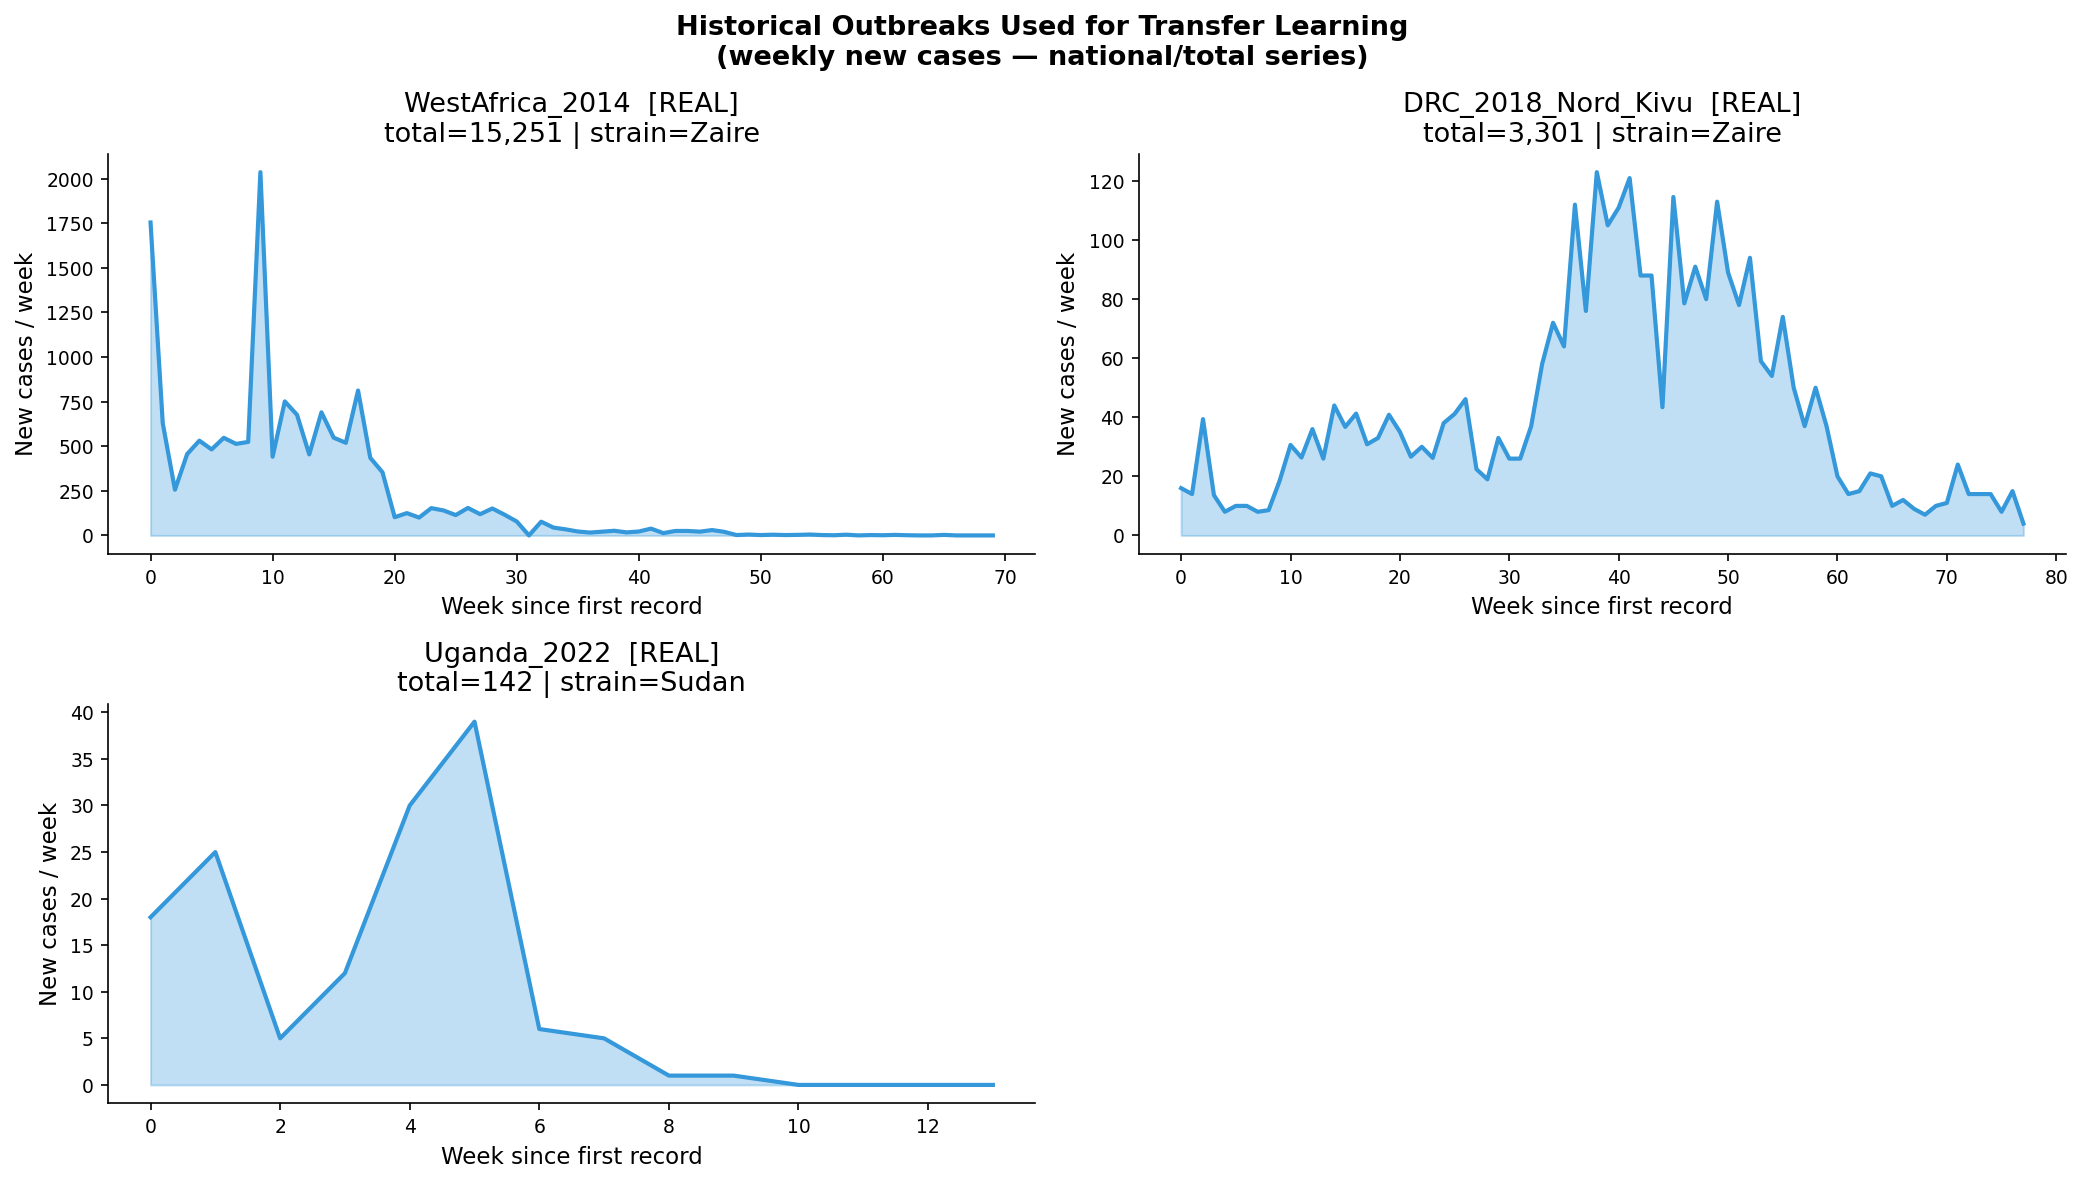

In [8]:
# MODULE 3.2 · Load the historical outbreaks (real files first, flagged SIR fallback otherwise)

def simulate_sir_epidemic(R0: float, total_cases: float, duration_weeks: int, name: str,
                          gamma: float = 1 / 7.0, N: int = 1_000_000, I0: int = 5) -> np.ndarray:
    """FALLBACK ONLY. SIR simulation rescaled to the published total, with Poisson noise.
    Only R0, duration and total are used: this is NOT a reconstruction of the real outbreak."""
    beta = R0 * gamma

    def sir(y, t):
        S, I, R = y
        return [-beta * S * I / N, beta * S * I / N - gamma * I, gamma * I]

    t = np.arange(0, duration_weeks * 7 + 1)
    sol = odeint(sir, [N - I0, I0, 0], t)
    new_daily = np.maximum(-np.diff(sol[:, 0]), 0)
    weeks = len(new_daily) // 7
    weekly = new_daily[:weeks * 7].reshape(weeks, 7).sum(axis=1)
    weekly = weekly * (total_cases / max(weekly.sum(), 1e-8))
    rng = np.random.default_rng(stable_seed(name))          # deterministic (hash() is not)
    return rng.poisson(weekly).astype(float)


def load_all_historical(cfg: Config):
    """Returns (weekly tables, kind per outbreak, source file per outbreak)."""
    weekly_by: Dict[str, pd.DataFrame] = {}
    kind_by: Dict[str, str] = {}
    file_by: Dict[str, str] = {}
    print("── Historical outbreaks for transfer learning ─────────────────")
    for name, spec in cfg.HISTORICAL_OUTBREAKS.items():
        if not spec.get('use_in_pretraining', True):
            print(f"\n[{name}] metadata only ({spec['total_cases']} cases: too small for pre-training)")
            continue
        print(f"\n[{name}] {spec['country']} | {spec['strain']} | published total ~{spec['total_cases']:,}")
        weekly, path = load_historical_outbreak(name, {**spec, 'total_cases': spec['total_cases']}, cfg)
        if weekly is not None:
            weekly_by[name], kind_by[name], file_by[name] = weekly, 'real', str(path)
        else:
            sim = simulate_sir_epidemic(spec['R0'], spec['total_cases'], spec['duration_weeks'], name)
            dates = pd.date_range('2000-01-02', periods=len(sim), freq='7D')
            weekly_by[name] = pd.DataFrame({'zone': 'ALL', 'date': dates, 'value': sim})
            kind_by[name], file_by[name] = 'simulated', 'SIR fallback'
            print(f"   >>> NO REAL FILE USED: '{name}' is a SIMULATED fallback (R0={spec['R0']}, total={spec['total_cases']:,}).")
    return weekly_by, kind_by, file_by


HIST_WEEKLY, HIST_KIND, HIST_FILES = load_all_historical(CFG)
PROVENANCE['historical_sources'] = {n: {'kind': HIST_KIND[n], 'file': HIST_FILES[n]} for n in HIST_KIND}
if any(k == 'simulated' for k in HIST_KIND.values()):
    print("\n" + "!" * 68)
    print("WARNING: at least one transfer-learning source is SIMULATED (no real file found).")
    print(f"         Put the real files in '{CFG.HIST_DIR}/' and re-run Module 3 for genuine transfer learning.")
    print("!" * 68)
else:
    print("\nAll transfer-learning sources are REAL data.")


def plot_historical_outbreaks(weekly_by: Dict[str, pd.DataFrame], kind_by: Dict[str, str], cfg: Config) -> None:
    n = len(weekly_by)
    if n == 0:
        return
    nc = min(2, n)
    nr = (n + nc - 1) // nc
    fig, axes = plt.subplots(nr, nc, figsize=(7 * nc, 4 * nr), squeeze=False)
    fig.suptitle("Historical Outbreaks Used for Transfer Learning\n(weekly new cases — national/total series)",
                 fontsize=13, fontweight='bold')
    for ax, (name, w) in zip(axes.flatten(), weekly_by.items()):
        tot = add_total_series(w)
        series = tot[tot['zone'] == HIST_TOTAL] if (tot['zone'] == HIST_TOTAL).any() else tot
        series = series.groupby('date')['value'].sum().sort_index()
        ax.fill_between(range(len(series)), series.to_numpy(), alpha=0.3, color=PALETTE[2])
        ax.plot(series.to_numpy(), color=PALETTE[2], lw=2)
        meta = cfg.HISTORICAL_OUTBREAKS.get(name, {})
        ax.set_title(f"{name}  [{kind_by[name].upper()}]\ntotal={series.sum():,.0f} | strain={meta.get('strain', '?')}")
        ax.set_xlabel("Week since first record"); ax.set_ylabel("New cases / week")
    for ax in axes.flatten()[n:]:
        ax.axis('off')
    plt.tight_layout()
    save_fig(fig, "04_historical_outbreaks.png")
    plt.show()


plot_historical_outbreaks(HIST_WEEKLY, HIST_KIND, CFG)

── Pre-training corpus ───────────────────────────────────────
          outbreak kind  series  cases
   WestAfrica_2014 real       4  15208
DRC_2018_Nord_Kivu real      15   3170
       Uganda_2022 real       1    142
   pre-training               46 epochs | best epoch   16 | best val loss 0.09119
Saved figure: 05_pretrain_loss.png


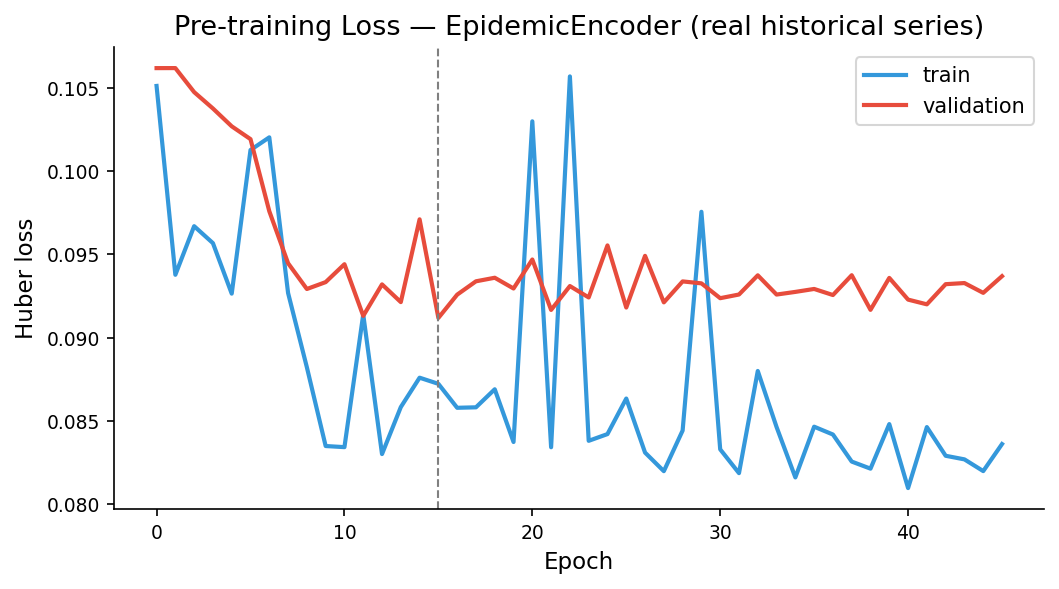

Pre-training windows per outbreak: {'WestAfrica_2014': 224, 'DRC_2018_Nord_Kivu': 900, 'Uganda_2022': 13}

── Leave-one-outbreak-out transfer check (zero-shot) ─────────
          held_out kind  n_windows  RMSE_model  RMSE_persistence  skill
DRC_2018_Nord_Kivu real        900      0.5048            0.5216  0.032
       Uganda_2022 real         13      0.2680            0.2314 -0.158
   WestAfrica_2014 real        224      0.2741            0.2987  0.082
Saved figure: 04b_tl_leave_one_outbreak_out.png


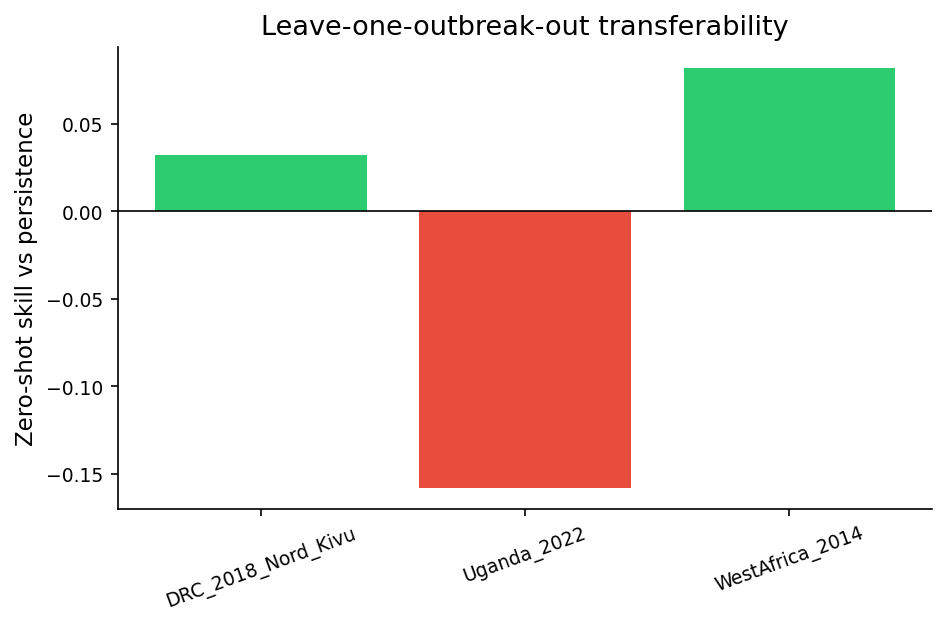


Pre-trained encoder ready: True


In [9]:
# MODULE 3.3 · Series corpus, local normalisation, pre-trained encoder, leave-one-outbreak-out check

S_MIN = float(np.log1p(1.0))       # minimum scale (one case) so that empty windows are well defined


def weekly_to_items(weekly: pd.DataFrame, outbreak: str, cfg: Config) -> List[Dict]:
    """One item per zone (plus the total), trimmed to start at the first case and to end 4 weeks after the last."""
    items = []
    for z, g in add_total_series(weekly).groupby('zone'):
        v = g.sort_values('date')['value'].to_numpy(float)
        nz = np.flatnonzero(v > 0)
        if nz.size == 0:
            continue
        v = v[nz[0]: nz[-1] + 5]
        if v.sum() < cfg.TL_MIN_CASES_SOURCE or len(v) < cfg.TL_MIN_STEPS_SOURCE:
            continue
        items.append(dict(outbreak=outbreak, zone=z, series=v, total=float(v.sum())))
    return items


def local_windows_from_series(v: np.ndarray, seq_len: int):
    """Windows over one series that starts at its first case.
    Input  : log1p(past `seq_len` values) / s        (left-padded with zeros = "no cases before the first one")
    Target : log1p(next value) / s,  s = max(window max, log1p(1))   -> scale-free, no knowledge of the future peak.
    The first value (index 0) is never a target (emergence is not forecastable). Returns X (n, seq_len, 1), y (n,), s (n,)."""
    lv = np.log1p(np.asarray(v, float))
    pad = np.concatenate([np.zeros(seq_len - 1), lv])
    X, y, s = [], [], []
    for i in range(1, len(lv)):
        w = pad[i - 1: i - 1 + seq_len]
        sc = max(float(w.max()), S_MIN)
        X.append(w / sc); y.append(lv[i] / sc); s.append(sc)
    return (np.asarray(X, np.float32)[..., None], np.asarray(y, np.float32), np.asarray(s, np.float32))


def items_to_windows(items: List[Dict], seq_len: int, val_frac: float = 0.15) -> Dict[str, Any]:
    """Pool the windows of all items; the last `val_frac` windows of every item (chronologically) form the validation set."""
    Xtr, ytr, Xva, yva, counts = [], [], [], [], {}
    for it in items:
        X, y, _ = local_windows_from_series(it['series'], seq_len)
        n = len(X)
        n_val = max(1, int(round(val_frac * n))) if (n >= 8 and val_frac > 0) else 0
        Xtr.append(X[:n - n_val]); ytr.append(y[:n - n_val])
        if n_val:
            Xva.append(X[n - n_val:]); yva.append(y[n - n_val:])
        counts[it['outbreak']] = counts.get(it['outbreak'], 0) + n
    cat = lambda a, shape: np.concatenate(a) if a else np.empty(shape, np.float32)
    return dict(Xtr=cat(Xtr, (0, seq_len, 1)), ytr=cat(ytr, (0,)), Xva=cat(Xva, (0, seq_len, 1)),
                yva=cat(yva, (0,)), counts=counts)


if TORCH_OK:
    class EpidemicEncoder(nn.Module):
        """Univariate LSTM on locally-normalised log-incidence windows. The SAME input space is used for
        pre-training (historical outbreaks) and fine-tuning (2026 zones), so every weight is transferable."""
        def __init__(self, hidden: int = 32, n_layers: int = 2, dropout: float = 0.2):
            super().__init__()
            self.hidden = hidden
            self.n_layers = n_layers
            self.dropout_p = dropout
            self.lstm = nn.LSTM(1, hidden, n_layers, batch_first=True, dropout=dropout if n_layers > 1 else 0.0)
            self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))

        def forward(self, x):
            # Persistence-anchored: prediction = last observed (normalised) value + learned correction.
            out, _ = self.lstm(x)
            return x[:, -1, 0] + self.head(out[:, -1, :]).squeeze(-1)

        def encode(self, x):
            _, (h, _) = self.lstm(x)
            return h[-1]


def pretrain_encoder(items: List[Dict], cfg: Config, epochs: Optional[int] = None, seed: int = 0,
                     plot: bool = True, verbose: bool = True):
    """Pre-train the encoder on historical series. Returns (model, history, windows_info)."""
    win = items_to_windows(items, cfg.TL_SEQ_LEN)
    if len(win['Xtr']) < 20:
        raise ValueError(f"only {len(win['Xtr'])} pre-training windows — not enough historical data")
    torch.manual_seed(seed)
    model = EpidemicEncoder(cfg.TL_HIDDEN, cfg.TL_LAYERS)
    model, hist = fit_torch(model, win['Xtr'], win['ytr'], win['Xva'], win['yva'],
                            epochs=epochs or cfg.TL_PRETRAIN_EPOCHS, lr=cfg.TL_LR_PRETRAIN, patience=30,
                            batch_size=64, seed=seed, name='pre-training', verbose=verbose)
    if plot:
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(hist['train'], color=PALETTE[2], lw=2, label='train')
        if hist['val']:
            ax.plot(hist['val'], color=PALETTE[1], lw=2, label='validation')
        ax.axvline(hist['best_epoch'], color='gray', ls='--', lw=1)
        ax.set_title("Pre-training Loss — EpidemicEncoder (real historical series)")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Huber loss"); ax.legend()
        save_fig(fig, "05_pretrain_loss.png")
        plt.show()
    return model, hist, win


def loo_transfer_check(items: List[Dict], kinds: Dict[str, str], cfg: Config) -> pd.DataFrame:
    """Leave-one-outbreak-out: pre-train on the other outbreaks, evaluate ZERO-SHOT on the held-out one.
    Errors are compared with persistence ("next = last") in the same normalised space.
    skill > 0 means that what is learned on other outbreaks transfers to an unseen one."""
    outbreaks = sorted({it['outbreak'] for it in items})
    if len(outbreaks) < 2:
        print("   leave-one-outbreak-out skipped: at least two outbreaks are needed")
        return pd.DataFrame()
    rows = []
    for held in outbreaks:
        tr_items = [it for it in items if it['outbreak'] != held]
        te_items = [it for it in items if it['outbreak'] == held]
        try:
            model, _, _ = pretrain_encoder(tr_items, cfg, epochs=cfg.TL_LOO_EPOCHS, plot=False, verbose=False)
        except ValueError as e:
            print(f"   {held}: skipped ({e})")
            continue
        win = items_to_windows(te_items, cfg.TL_SEQ_LEN, val_frac=0.0)
        X, y = win['Xtr'], win['ytr']
        if len(X) < 5:
            continue
        pred = predict_torch(model, X)
        rmse_m = float(np.sqrt(np.mean((pred - y) ** 2)))
        rmse_n = float(np.sqrt(np.mean((X[:, -1, 0] - y) ** 2)))
        rows.append(dict(held_out=held, kind=kinds.get(held, '?'), n_windows=len(X), RMSE_model=round(rmse_m, 4),
                         RMSE_persistence=round(rmse_n, 4), skill=round(1 - rmse_m / max(rmse_n, 1e-9), 3)))
    return pd.DataFrame(rows)


# ── Build the corpus and pre-train 
TL_ITEMS: List[Dict] = []
for _name, _weekly in HIST_WEEKLY.items():
    TL_ITEMS += weekly_to_items(_weekly, _name, CFG)
print("── Pre-training corpus ───────────────────────────────────────")
_summary = pd.DataFrame([{'outbreak': o, 'kind': HIST_KIND[o],
                          'series': sum(1 for it in TL_ITEMS if it['outbreak'] == o),
                          'cases': round(sum(it['total'] for it in TL_ITEMS if it['outbreak'] == o if it['zone'] != HIST_TOTAL))}
                         for o in HIST_WEEKLY])
print(_summary.to_string(index=False))

PRETRAINED_ENCODER, PRETRAIN_HIST, PRETRAIN_INFO, LOO_TABLE = None, {}, {}, pd.DataFrame()
if not TORCH_OK:
    RUN_STATUS['tl_pretraining'] = 'skipped: PyTorch unavailable'
elif len(TL_ITEMS) == 0:
    RUN_STATUS['tl_pretraining'] = 'skipped: no usable historical series'
else:
    try:
        PRETRAINED_ENCODER, PRETRAIN_HIST, PRETRAIN_INFO = pretrain_encoder(TL_ITEMS, CFG)
        print(f"Pre-training windows per outbreak: {PRETRAIN_INFO['counts']}")
        print("\n── Leave-one-outbreak-out transfer check (zero-shot) ─────────")
        LOO_TABLE = loo_transfer_check(TL_ITEMS, HIST_KIND, CFG)
        if len(LOO_TABLE):
            print(LOO_TABLE.to_string(index=False))
            fig, ax = plt.subplots(figsize=(7, 4))
            ax.bar(LOO_TABLE['held_out'], LOO_TABLE['skill'],
                   color=[PALETTE[3] if v > 0 else PALETTE[1] for v in LOO_TABLE['skill']])
            ax.axhline(0, color='black', lw=0.8)
            ax.set_ylabel("Zero-shot skill vs persistence"); ax.set_title("Leave-one-outbreak-out transferability")
            plt.xticks(rotation=20)
            save_fig(fig, "04b_tl_leave_one_outbreak_out.png")
            plt.show()
        RUN_STATUS['tl_pretraining'] = 'ok'
    except Exception as e:
        RUN_STATUS['tl_pretraining'] = f'failed: {e}'
        print(f"Pre-training failed: {e}")
print(f"\nPre-trained encoder ready: {PRETRAINED_ENCODER is not None}")

## MODULE 4 · Feature Engineering (no target leakage)

Target = **new cases in the period** (incidence). Every feature of the row for period *t* uses only information available at the end of period *t−1*. The same function builds the training table and the features of future periods used in forecasting, and `check_no_leakage` verifies it automatically.

In [10]:
# MODULE 4 · Feature engineering (incidence target, information up to t-1 only)

def build_incidence_table(data: Dict, freq: str) -> pd.DataFrame:
    """cum_cases (zone | date | value) -> zone | date | cum_cases | new_cases at the chosen resolution.
    * every zone series starts at its first case and runs to the last complete period;
    * cumulative values are forced monotone (reporting corrections are ignored);
    * 'W' periods are labelled by their Sunday; the last incomplete week is dropped."""
    cum = data['cum_cases'][['zone', 'date', 'value']].copy()
    cum = cum[cum['zone'] != 'DRC']                      # national aggregate
    cum['date'] = pd.to_datetime(cum['date'])
    last_date = cum['date'].max()
    frames = []
    for z, g in cum.groupby('zone'):
        s = g.groupby('date')['value'].max().sort_index()
        s = s.reindex(pd.date_range(s.index.min(), last_date, freq='D')).ffill().cummax()
        s = s[s > 0]
        if s.empty:
            continue
        if freq == 'W':
            s = s.resample('W-SUN').last()
            if last_date.weekday() != 6:                 # incomplete last week
                s = s.iloc[:-1]
        if len(s) == 0:
            continue
        new = s.diff()
        new.iloc[0] = s.iloc[0]
        frames.append(pd.DataFrame({'zone': z, 'date': s.index, 'cum_cases': s.to_numpy(),
                                    'new_cases': new.clip(lower=0).to_numpy()}))
    return pd.concat(frames, ignore_index=True)


def build_history_arrays(inc: pd.DataFrame) -> Dict[str, Any]:
    """Long table -> arrays: H (zones x periods) new cases, C cumulative, first = index of the first case."""
    zones = sorted(inc['zone'].unique())
    dates = pd.DatetimeIndex(sorted(inc['date'].unique()))
    zi, di = {z: i for i, z in enumerate(zones)}, {d: i for i, d in enumerate(dates)}
    Z, T = len(zones), len(dates)
    H, C, first = np.zeros((Z, T)), np.zeros((Z, T)), np.full(Z, T, dtype=int)
    for r in inc.itertuples(index=False):
        i, j = zi[r.zone], di[r.date]
        H[i, j], C[i, j] = r.new_cases, r.cum_cases
        first[i] = min(first[i], j)
    return dict(zones=zones, dates=dates, H=H, C=C, first=first)


def feature_names(cfg: Config) -> List[str]:
    names = [f'lag_{L}' for L in cfg.lags] + [f'roll_mean_{w}' for w in cfg.rolls] + [f'roll_std_{w}' for w in cfg.rolls]
    names += ['trend', 'cum_prev', 'age', 'month', 'week']
    if cfg.FREQ == 'D':
        names.append('dow')
    if cfg.USE_ZONE_ID:
        names.append('zone_enc')
    return names


def features_from_history(hist: np.ndarray, cum_prev, age, date: pd.Timestamp, cfg: Config) -> np.ndarray:
    """Features of the period starting after `hist`.

    hist     : (..., Z, t) new cases of the t PAST periods (leading batch dimensions allowed, e.g. bootstrap paths)
    cum_prev : cumulative cases up to the previous period, broadcastable to (..., Z)
    age      : (Z,) periods elapsed since the zone's first case
    date     : label of the period being predicted
    Returns (..., Z, F) in the order of feature_names(cfg). Missing history is zero-padded (no case before the first)."""
    lags, rolls = cfg.lags, cfg.rolls
    maxlen = max(max(lags), max(rolls))
    t = hist.shape[-1]
    if t < maxlen:
        h = np.concatenate([np.zeros(hist.shape[:-1] + (maxlen - t,)), hist], axis=-1)
    else:
        h = hist[..., -maxlen:]
    shape = hist.shape[:-1]
    cols = [h[..., -L] for L in lags]
    cols += [h[..., -w:].mean(axis=-1) for w in rolls]
    cols += [h[..., -w:].std(axis=-1, ddof=1) for w in rolls]
    cols.append((h[..., -1] - h[..., -2]) / (h[..., -2] + 1.0))                # trend (growth proxy from past only)
    cols.append(np.broadcast_to(np.asarray(cum_prev, float), shape))
    cols.append(np.broadcast_to(np.asarray(age, float), shape))
    cols.append(np.full(shape, float(date.month)))
    cols.append(np.full(shape, float(date.isocalendar()[1])))
    if cfg.FREQ == 'D':
        cols.append(np.full(shape, float(date.dayofweek)))
    if cfg.USE_ZONE_ID:
        cols.append(np.broadcast_to(np.arange(shape[-1], dtype=float), shape))
    return np.stack([np.asarray(c, float) for c in cols], axis=-1)


def build_features(data: Dict, cfg: Config):
    """Supervised table: one row per (active zone, period) with age >= 1 (the emergence period is not forecastable).
    Returns (df, feature_cols, target_col)."""
    inc = build_incidence_table(data, cfg.FREQ)
    A = build_history_arrays(inc)
    H, C, first, dates, zones = A['H'], A['C'], A['first'], A['dates'], A['zones']
    Z, T = H.shape
    names = feature_names(cfg)
    blocks = []
    for t in range(T):
        age = t - first
        idx = np.flatnonzero(age >= 1)
        if idx.size == 0:
            continue
        cum_prev = C[:, t - 1] if t > 0 else np.zeros(Z)
        feats = features_from_history(H[:, :t], cum_prev, age, dates[t], cfg)
        blk = pd.DataFrame(feats[idx], columns=names)
        blk.insert(0, 'cum_cases', C[idx, t])
        blk.insert(0, 'new_cases', H[idx, t])
        blk.insert(0, 'date', dates[t])
        blk.insert(0, 'zone', [zones[i] for i in idx])
        blocks.append(blk)
    df = pd.concat(blocks, ignore_index=True)
    return df, names, 'new_cases'


def next_step_feature_matrix(A: Dict[str, Any], cfg: Config):
    """Features of the first FUTURE period for every zone (used for forecasting). Returns (X (Z,F), next_date)."""
    H, C, first, dates = A['H'], A['C'], A['first'], A['dates']
    T = H.shape[1]
    next_date = dates[-1] + pd.Timedelta(days=cfg.step_days)
    X = features_from_history(H, C[:, -1], T - first, next_date, cfg)
    return X, next_date


def check_no_leakage(data: Dict, cfg: Config, tol: float = 1e-9) -> bool:
    """Automatic leakage test. The observation to predict (last period of every zone) is modified:
    the target must change, but NO feature of that row may change."""
    base, cols, tgt = build_features(data, cfg)
    base = base.sort_values(['zone', 'date'])
    thr = base.groupby('zone')['date'].apply(lambda s: s.iloc[-2] if len(s) > 1 else pd.NaT).dropna()
    d = data['cum_cases'].copy()
    d['date'] = pd.to_datetime(d['date'])
    mask = d['date'] > d['zone'].map(thr)
    d.loc[mask, 'value'] = d.loc[mask, 'value'] + 1000.0
    new, _, _ = build_features({**data, 'cum_cases': d}, cfg)
    a = base.groupby('zone').tail(1).set_index('zone').loc[thr.index]
    b = new.sort_values(['zone', 'date']).groupby('zone').tail(1).set_index('zone').loc[thr.index]
    moved = (np.abs(a[tgt].to_numpy(float) - b[tgt].to_numpy(float)) > tol).mean()
    if moved < 0.5:
        raise RuntimeError("Leakage test inconclusive: the target did not change when the observation was modified")
    bad = [c for c in cols if not np.allclose(a[c].to_numpy(float), b[c].to_numpy(float), atol=1e-6, equal_nan=True)]
    if bad:
        raise AssertionError(f"TARGET LEAKAGE detected in: {bad}")
    print(f"✓ No leakage: all {len(cols)} features are unchanged when the observation to predict is modified")
    return True


print("=" * 68)
print(f"MODULE 4 · Feature engineering | resolution: {CFG.FREQ} | target: new cases per {CFG.step_label}")
print("=" * 68)
INC_TABLE = build_incidence_table(DATA, CFG.FREQ)
HIST_ARRAYS = build_history_arrays(INC_TABLE)
ZONES = HIST_ARRAYS['zones']
DF_FEAT, FEATURE_COLS, TARGET_COL = build_features(DATA, CFG)
LEAK_TEST_PASSED = check_no_leakage(DATA, CFG)

print(f"Zones with at least one case: {len(ZONES)} | periods: {len(HIST_ARRAYS['dates'])} "
      f"({HIST_ARRAYS['dates'][0].date()} → {HIST_ARRAYS['dates'][-1].date()})")
print(f"Supervised rows: {len(DF_FEAT):,} | features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Target '{TARGET_COL}': mean={DF_FEAT[TARGET_COL].mean():.2f}  max={DF_FEAT[TARGET_COL].max():.0f}  "
      f"zero share={(DF_FEAT[TARGET_COL] == 0).mean():.0%}")

MODULE 4 · Feature engineering | resolution: W | target: new cases per week
✓ No leakage: all 13 features are unchanged when the observation to predict is modified
Zones with at least one case: 74 | periods: 27 (2026-05-17 → 2026-11-15)
Supervised rows: 1,354 | features (13): ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'roll_mean_2', 'roll_mean_4', 'roll_std_2', 'roll_std_4', 'trend', 'cum_prev', 'age', 'month', 'week']
Target 'new_cases': mean=8.33  max=207  zero share=45%


## MODULE 5 · Chronological Split (train / test)

One single split replaces the former "few-shot" and "realistic" splits. Clipping bounds and scaling are fitted on the **training period only**. Few-shot learning is evaluated separately in the transfer-learning ablation (Module 9).

In [11]:

# MODULE 5 · Chronological split with train-only preprocessing

class FeaturePrep:
    """Cleaning (nan/inf -> 0), winsorisation at the 1st/99th training percentiles and robust scaling.
    Fitted on the training period ONLY, then applied unchanged to validation, test and future data."""
    def __init__(self, clip_pct: Tuple[float, float] = (1, 99)):
        self.clip_pct = clip_pct

    @staticmethod
    def _clean(X) -> np.ndarray:
        return np.nan_to_num(np.asarray(X, dtype=float), nan=0.0, posinf=0.0, neginf=0.0)

    def fit(self, X) -> 'FeaturePrep':
        X = self._clean(X)
        self.lo_, self.hi_ = np.percentile(X, self.clip_pct[0], axis=0), np.percentile(X, self.clip_pct[1], axis=0)
        self.scaler_ = RobustScaler().fit(np.clip(X, self.lo_, self.hi_))
        return self

    def transform(self, X) -> np.ndarray:
        out = self.scaler_.transform(np.clip(self._clean(X), self.lo_, self.hi_))
        assert np.all(np.isfinite(out)), "non-finite values after scaling"
        return out


def temporal_split(df: pd.DataFrame, feature_cols: List[str], target_col: str, cfg: Config):
    """Chronological split. Rows are ordered by (zone, date) everywhere in the notebook.
    Returns X_train, y_train, X_test, y_test, prep, risk_threshold, train_df, test_df (scaled X)."""
    d = df.sort_values(['zone', 'date']).reset_index(drop=True)
    train = d[d['date'] <= pd.Timestamp(cfg.TRAIN_END)]
    t_end = pd.Timestamp(cfg.TEST_END) if cfg.TEST_END else d['date'].max()
    test = d[(d['date'] >= pd.Timestamp(cfg.TEST_START)) & (d['date'] <= t_end)]
    if len(train) < 30 or len(test) < 10:
        raise ValueError(f"Not enough data for the split: train={len(train)} rows, test={len(test)} rows. "
                         f"Check CFG.TRAIN_END / TEST_START / FREQ.")
    prep = FeaturePrep().fit(train[feature_cols].to_numpy())
    y_tr, y_te = train[target_col].to_numpy(float), test[target_col].to_numpy(float)
    pos = y_tr[y_tr > 0]
    thr = float(np.percentile(pos, cfg.RISK_PCTILE)) if len(pos) else 1.0
    print("Chronological split:")
    print(f"   Train : {len(train):5d} rows | {train['date'].min().date()} → {train['date'].max().date()} "
          f"({train['date'].nunique()} {cfg.step_label}s)")
    print(f"   Test  : {len(test):5d} rows | {test['date'].min().date()} → {test['date'].max().date()} "
          f"({test['date'].nunique()} {cfg.step_label}s)")
    print(f"   High-risk threshold ({cfg.RISK_PCTILE}th percentile of positive training targets): {thr:.1f} cases/{cfg.step_label}")
    return (prep.transform(train[feature_cols].to_numpy()), y_tr, prep.transform(test[feature_cols].to_numpy()), y_te,
            prep, thr, train.reset_index(drop=True), test.reset_index(drop=True))


X_TRAIN, Y_TRAIN, X_TEST, Y_TEST, SCALER, RISK_THR, TRAIN_DF, TEST_DF = temporal_split(DF_FEAT, FEATURE_COLS, TARGET_COL, CFG)
print(f"\nX_TRAIN: {X_TRAIN.shape} | X_TEST: {X_TEST.shape}")

# Chronological validation block (last VAL_STEPS periods of the training window) for early stopping
_train_dates = np.sort(TRAIN_DF['date'].unique())
VAL_MASK = (TRAIN_DF['date'] > _train_dates[-CFG.VAL_STEPS - 1]).to_numpy() if len(_train_dates) > CFG.VAL_STEPS else np.zeros(len(TRAIN_DF), bool)
print(f"Validation block: {int(VAL_MASK.sum())} rows (last {CFG.VAL_STEPS} {CFG.step_label}s of the training window)")
SPLIT_INFO = {'train_rows': len(TRAIN_DF), 'test_rows': len(TEST_DF), 'train_end': str(TRAIN_DF['date'].max().date()),
              'test_start': str(TEST_DF['date'].min().date()), 'test_end': str(TEST_DF['date'].max().date()),
              'risk_threshold': round(RISK_THR, 3), 'resolution': CFG.FREQ}

Chronological split:
   Train :   855 rows | 2026-05-24 → 2026-09-27 (19 weeks)
   Test  :   499 rows | 2026-10-04 → 2026-11-15 (7 weeks)
   High-risk threshold (75th percentile of positive training targets): 18.0 cases/week

X_TRAIN: (855, 13) | X_TEST: (499, 13)
Validation block: 204 rows (last 3 weeks of the training window)


## MODULE 6 · Unified Metrics

In [12]:

# MODULE 6 · Unified metrics (regression, skill vs. persistence, high-risk classification)

NAIVE_TEST = TEST_DF['lag_1'].to_numpy(float)          # persistence forecast on the test rows


def compute_metrics(y_true, y_pred, name: str, risk_thr: float, y_naive: Optional[np.ndarray] = None) -> Dict:
    """RMSE, MAE, MAPE (on y>0), SMAPE, RMSLE, R², correlation, Theil U2 and skill vs. persistence,
    plus Accuracy/Precision/Recall/F1/AUC for the high-risk label (y > risk_thr)."""
    yt = np.asarray(y_true, float)
    yp = np.clip(np.asarray(y_pred, float), 0, None)
    yn = NAIVE_TEST if y_naive is None else np.asarray(y_naive, float)
    rmse = float(np.sqrt(mean_squared_error(yt, yp)))
    mae = float(mean_absolute_error(yt, yp))
    pos = yt > 0
    mape = float(np.mean(np.abs((yt[pos] - yp[pos]) / yt[pos])) * 100) if pos.any() else np.nan
    smape = float(np.mean(2 * np.abs(yt - yp) / (np.abs(yt) + np.abs(yp) + 1e-8)) * 100)
    rmsle = float(np.sqrt(np.mean((np.log1p(yp) - np.log1p(yt)) ** 2)))
    r2 = float(r2_score(yt, yp)) if len(np.unique(yt)) > 1 else np.nan
    corr = float(np.corrcoef(yt, yp)[0, 1]) if np.std(yp) > 0 and np.std(yt) > 0 else np.nan
    rmse_naive = float(np.sqrt(mean_squared_error(yt, np.clip(yn, 0, None)))) if len(yn) == len(yt) else np.nan
    theil_u = rmse / rmse_naive if rmse_naive and rmse_naive > 0 else np.nan        # Theil U2 (<1: better than persistence)
    skill = 1 - theil_u if not np.isnan(theil_u) else np.nan
    yt_b, yp_b = (yt > risk_thr).astype(int), (yp > risk_thr).astype(int)
    try:
        auc = float(roc_auc_score(yt_b, yp)) if len(np.unique(yt_b)) > 1 else np.nan
    except Exception:
        auc = np.nan
    return {'Model': name, 'RMSE': round(rmse, 4), 'MAE': round(mae, 4), 'MAPE': round(mape, 2), 'SMAPE': round(smape, 2),
            'RMSLE': round(rmsle, 4), 'R2': round(r2, 4), 'Corr': round(corr, 4), 'Theil_U': round(theil_u, 4),
            'Skill_vs_naive': round(skill, 4),
            'Accuracy': round(float(accuracy_score(yt_b, yp_b)), 4),
            'Precision': round(float(precision_score(yt_b, yp_b, zero_division=0)), 4),
            'Recall': round(float(recall_score(yt_b, yp_b, zero_division=0)), 4),
            'F1': round(float(f1_score(yt_b, yp_b, zero_division=0)), 4), 'AUC': round(auc, 4) if not np.isnan(auc) else np.nan}


# Registries shared by Modules 7–12
ALL_RESULTS: List[Dict] = []
ALL_PREDS: Dict[str, np.ndarray] = {}
ALL_MODELS: Dict[str, Any] = {}
MODEL_FAMILY: Dict[str, str] = {}      # 'naive' | 'classical' | 'deep' | 'transfer' | 'graph'


def register_result(name: str, preds, family: str, model=None) -> Dict:
    """Evaluate predictions aligned with TEST_DF and store them in the registries."""
    preds = np.clip(np.asarray(preds, float), 0, None)
    if len(preds) != len(Y_TEST):
        raise ValueError(f"{name}: {len(preds)} predictions for {len(Y_TEST)} test rows")
    res = compute_metrics(Y_TEST, preds, name, RISK_THR)
    ALL_RESULTS.append(res)
    ALL_PREDS[name] = preds
    MODEL_FAMILY[name] = family
    if model is not None:
        ALL_MODELS[name] = model
    print(f"   {name:24s} RMSE={res['RMSE']:9.4f} MAE={res['MAE']:8.4f} R²={res['R2']:7.4f} "
          f"skill={res['Skill_vs_naive']:7.3f} F1={res['F1']:6.4f}")
    return res


print("Metrics ready. Reference RMSE of persistence on the test set: "
      f"{np.sqrt(mean_squared_error(Y_TEST, NAIVE_TEST)):.4f}")

Metrics ready. Reference RMSE of persistence on the test set: 6.0852


## MODULE 7 · Baseline Models

Naive references first (persistence and rolling mean): a learned model is only useful if it beats them.

In [13]:

# MODULE 7 · Naive references and classical machine-learning baselines
# Every model is trained twice:
#   * raw target            : predicts new cases directly;
#   * "_logdelta" variant   : predicts the log growth log1p(y) − log1p(lag_1) and is anchored on persistence
#                             (prediction = expm1(log1p(lag_1) + learned growth)). This is the standard way to let a
#                             model add value on top of "next = last" and it removes the extrapolation limits of trees.

print("── Naive references ─────────────────────────────────────────")
register_result('Naive_lag1', TEST_DF['lag_1'].to_numpy(float), 'naive')
_roll_col = f"roll_mean_{max(CFG.rolls)}"
register_result(f'Naive_{_roll_col}', TEST_DF[_roll_col].to_numpy(float), 'naive')

# Model factories (fresh, unfitted estimators; reused by the cross-validation in Module 12)
def _make_xgb():
    if XGB_OK:
        return xgb.XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                random_state=CFG.SEED, verbosity=0)
    return GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=CFG.SEED)


def _make_lgbm(n_estimators: int = 500):
    if LGB_OK:
        return lgb.LGBMRegressor(n_estimators=n_estimators, max_depth=5, learning_rate=0.03, num_leaves=15,
                                 subsample=0.8, colsample_bytree=0.8, random_state=CFG.SEED, verbose=-1)
    return HistGradientBoostingRegressor(max_iter=min(n_estimators, 300), max_depth=5, learning_rate=0.05, random_state=CFG.SEED)


XGB_NAME = 'XGBoost' if XGB_OK else 'GradientBoosting'
LGB_NAME = 'LightGBM' if LGB_OK else 'HistGradientBoosting'
MODEL_FACTORIES: Dict[str, Any] = {
    'LinearRegression': lambda: LinearRegression(),
    'Ridge':            lambda: Ridge(alpha=1.0),
    'RandomForest':     lambda: RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=2,
                                                      random_state=CFG.SEED, n_jobs=-1),
    XGB_NAME:           _make_xgb,
    LGB_NAME:           lambda: _make_lgbm(),
}
TREE_MODEL_NAMES = ['RandomForest', XGB_NAME, LGB_NAME]
BEST_N_ESTIMATORS: Dict[str, int] = {}

# ── Persistence-anchored ("log-delta") helpers
LAG_IDX = FEATURE_COLS.index('lag_1')
DELTA_SUFFIX = '_logdelta'


def is_delta(name: str) -> bool:
    return name.endswith(DELTA_SUFFIX)


def base_name(name: str) -> str:
    return name[:-len(DELTA_SUFFIX)] if is_delta(name) else name


def target_for(name: str, y, lag_raw) -> np.ndarray:
    """Training target: counts (raw models) or log growth versus persistence (log-delta models)."""
    y = np.asarray(y, float)
    return np.log1p(y) - np.log1p(np.clip(np.asarray(lag_raw, float), 0, None)) if is_delta(name) else y


def to_counts(name: str, model_output, lag_raw) -> np.ndarray:
    """Model output -> predicted counts."""
    out = np.asarray(model_output, float)
    if is_delta(name):
        return np.clip(np.expm1(np.log1p(np.clip(np.asarray(lag_raw, float), 0, None)) + out), 0, None)
    return np.clip(out, 0, None)


def predict_counts(name: str, model, X_scaled, lag_raw) -> np.ndarray:
    """Predicted counts with two safeguards fitted on the TRAINING data (see fit_model): the predicted log growth of
    log-delta models is clipped to the range seen in training (+/- 0.5), and counts are capped at 3x the training maximum.
    Without them a linear model extrapolating on unseen feature values can produce astronomically large forecasts."""
    out = np.asarray(model.predict(X_scaled), float)
    bounds = getattr(model, 'delta_bounds_', None)
    if is_delta(name) and bounds is not None:
        out = np.clip(out, bounds[0], bounds[1])
    counts = to_counts(name, out, lag_raw)
    return np.minimum(counts, getattr(model, 'cap_', np.inf))


def predict_counts_raw(name: str, model, X_raw) -> np.ndarray:
    """Counts from UNSCALED features of any shape (..., F): applies SCALER and the persistence anchor."""
    X_raw = np.asarray(X_raw, float)
    flat = X_raw.reshape(-1, X_raw.shape[-1])
    return predict_counts(name, model, SCALER.transform(flat), flat[:, LAG_IDX]).reshape(X_raw.shape[:-1])


def fit_model(name: str, X, y, val_mask: Optional[np.ndarray] = None, y_counts: Optional[np.ndarray] = None):
    """Fit a fresh estimator on (X, y) (y already transformed by target_for). LightGBM uses chronological early
    stopping on the last periods of the training window, then is re-fitted on all rows with the selected tree count."""
    base = base_name(name)
    if base == 'LightGBM' and LGB_OK and val_mask is not None and val_mask.sum() >= 10 and (~val_mask).sum() >= 30:
        probe = _make_lgbm(2000)
        probe.fit(X[~val_mask], y[~val_mask], eval_set=[(X[val_mask], y[val_mask])],
                  callbacks=[lgb.early_stopping(30, verbose=False)])
        BEST_N_ESTIMATORS[name] = max(int(probe.best_iteration_ or 50), 20)
        model = _make_lgbm(BEST_N_ESTIMATORS[name])
    elif base == 'LightGBM' and LGB_OK and name in BEST_N_ESTIMATORS:
        model = _make_lgbm(BEST_N_ESTIMATORS[name])
    else:
        model = MODEL_FACTORIES[base]()
    model.fit(X, y)
    if is_delta(name):                                       # range of log growth seen in training
        lo, hi = np.percentile(y, [0.5, 99.5])
        model.delta_bounds_ = (float(lo) - 0.5, float(hi) + 0.5)
    if y_counts is not None and len(y_counts):               # cap on predicted counts
        model.cap_ = 3.0 * max(1.0, float(np.max(y_counts)))
    return model


def train_register(name: str):
    """Train one model (raw or log-delta variant) on the training period and evaluate it on the test rows."""
    lag_tr, lag_te = TRAIN_DF['lag_1'].to_numpy(float), TEST_DF['lag_1'].to_numpy(float)
    model = fit_model(name, X_TRAIN, target_for(name, Y_TRAIN, lag_tr), VAL_MASK, y_counts=Y_TRAIN)
    return register_result(name, predict_counts(name, model, X_TEST, lag_te), 'classical', model)


print("\n── Classical baselines (raw target and log-delta variants) ──")
print(f"   Train: {X_TRAIN.shape} | Test: {X_TEST.shape}\n")
for _base in list(MODEL_FACTORIES):
    for _name in (_base, _base + DELTA_SUFFIX):
        try:
            train_register(_name)
        except Exception as e:
            print(f"   FAILED {_name}: {e}")
TREE_MODEL_NAMES = [n for b in TREE_MODEL_NAMES for n in (b, b + DELTA_SUFFIX) if n in ALL_MODELS]
print(f"\n→ {sum(1 for f in MODEL_FAMILY.values() if f == 'classical')} classical models trained")

── Naive references ─────────────────────────────────────────
   Naive_lag1               RMSE=   6.0852 MAE=  2.8537 R²= 0.8400 skill=  0.000 F1=0.6444
   Naive_roll_mean_4        RMSE=   6.0909 MAE=  2.8948 R²= 0.8397 skill= -0.001 F1=0.6383

── Classical baselines (raw target and log-delta variants) ──
   Train: (855, 13) | Test: (499, 13)

   LinearRegression         RMSE=   6.5098 MAE=  2.9637 R²= 0.8169 skill= -0.070 F1=0.7000
   LinearRegression_logdelta RMSE=   8.7204 MAE=  3.2339 R²= 0.6714 skill= -0.433 F1=0.6585
   Ridge                    RMSE=   6.4933 MAE=  2.9541 R²= 0.8178 skill= -0.067 F1=0.7000
   Ridge_logdelta           RMSE=   8.6934 MAE=  3.2257 R²= 0.6734 skill= -0.429 F1=0.6585
   RandomForest             RMSE=   7.4168 MAE=  3.5980 R²= 0.7623 skill= -0.219 F1=0.5684
   RandomForest_logdelta    RMSE=   7.4167 MAE=  3.1187 R²= 0.7623 skill= -0.219 F1=0.6216
   XGBoost                  RMSE=   8.0064 MAE=  3.6591 R²= 0.7230 skill= -0.316 F1=0.5618
   XGBoost_logde

## MODULE 8 · Support Vector Regression

In [14]:

# MODULE 8 · Support vector regression (target standardised inside the pipeline)

def _svr(kernel: str, **kw):
    """SVR on a standardised target so that epsilon and C do not depend on the scale of the counts."""
    return TransformedTargetRegressor(regressor=SVR(kernel=kernel, **kw), transformer=StandardScaler())


MODEL_FACTORIES['SVR_RBF'] = lambda: _svr('rbf', C=10.0, gamma='scale', epsilon=0.1, tol=1e-3, max_iter=20000, cache_size=500)
MODEL_FACTORIES['SVR_Linear'] = lambda: _svr('linear', C=1.0, epsilon=0.1, max_iter=20000)
if CFG.RUN_SVR_POLY:
    MODEL_FACTORIES['SVR_Poly'] = lambda: _svr('poly', degree=2, C=5.0, gamma='scale', epsilon=0.1, max_iter=20000)

print("── SVR models (raw target and log-delta variants) ───────────")
for _base in [n for n in MODEL_FACTORIES if n.startswith('SVR')]:
    for _name in (_base, _base + DELTA_SUFFIX):
        try:
            train_register(_name)
        except Exception as e:
            print(f"   FAILED {_name}: {e}")

── SVR models (raw target and log-delta variants) ───────────
   SVR_RBF                  RMSE=   8.9949 MAE=  4.4576 R²= 0.6504 skill= -0.478 F1=0.6263
   SVR_RBF_logdelta         RMSE=   8.7612 MAE=  3.4974 R²= 0.6683 skill= -0.440 F1=0.6076
   SVR_Linear               RMSE=   6.1870 MAE=  2.8205 R²= 0.8346 skill= -0.017 F1=0.6753
   SVR_Linear_logdelta      RMSE=   7.2770 MAE=  2.8758 R²= 0.7712 skill= -0.196 F1=0.6582


## MODULE 9 · Deep Learning: LSTM, Transformer and Transfer-Learning LSTM

Windows are built **per zone** on exactly the same test rows as the ML models; neural models are trained on `log1p(new cases)` (heavy-tailed counts) and evaluated back on the original scale. The transfer-learning model is compared with a **from-scratch control** of identical architecture and input, over several seeds and several few-shot sizes.

In [15]:

# MODULE 9.1 · Per-zone sequences + LSTM and Transformer

_FULL = DF_FEAT.sort_values(['zone', 'date']).reset_index(drop=True)
_X_FULL = np.c_[SCALER.transform(_FULL[FEATURE_COLS].to_numpy()),
                np.log1p(np.clip(_FULL['lag_1'].to_numpy(float), 0, None))]   # last channel: log1p(lag_1), UNSCALED anchor
_FULL_POS = {(z, d): i for i, (z, d) in enumerate(zip(_FULL['zone'], _FULL['date']))}
_ZONE_START = _FULL.reset_index().groupby('zone')['index'].min().to_dict()


def sequences_for_rows(rows_df: pd.DataFrame, seq_len: int) -> np.ndarray:
    """(n, seq_len, F) scaled feature windows ending at each row, taken from the SAME zone only.
    The start of a zone is zero-padded, so every row has a window (same rows as the ML models)."""
    out = np.zeros((len(rows_df), seq_len, _X_FULL.shape[1]), dtype=np.float32)
    for k, (z, d) in enumerate(zip(rows_df['zone'], rows_df['date'])):
        i = _FULL_POS[(z, d)]
        s = max(_ZONE_START[z], i - seq_len + 1)
        w = _X_FULL[s:i + 1]
        out[k, seq_len - len(w):] = w
    return out


SEQ_LEN = CFG.seq_len
XS_TR_ALL, XS_TE = sequences_for_rows(TRAIN_DF, SEQ_LEN), sequences_for_rows(TEST_DF, SEQ_LEN)
YS_TR_LOG = np.log1p(Y_TRAIN).astype(np.float32)
XS_TR, YS_TR = XS_TR_ALL[~VAL_MASK], YS_TR_LOG[~VAL_MASK]
XS_VA, YS_VA = XS_TR_ALL[VAL_MASK], YS_TR_LOG[VAL_MASK]
DL_READY = TORCH_OK and len(XS_TR) > 20
print(f"Persistence-anchored networks: last input channel = log1p(lag_1) (output = anchor + learned log growth)")
print(f"Sequence length: {SEQ_LEN} {CFG.step_label}s | train {XS_TR.shape} | validation {XS_VA.shape} | test {XS_TE.shape}")

if TORCH_OK:
    class LSTMForecaster(nn.Module):
        def __init__(self, in_dim: int, hidden: int = 64, n_layers: int = 2, dropout: float = 0.3):
            super().__init__()
            self.lstm = nn.LSTM(in_dim, hidden, n_layers, batch_first=True, dropout=dropout if n_layers > 1 else 0.0)
            self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(dropout),
                                      nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))

        def forward(self, x):
            out, _ = self.lstm(x)
            return x[:, -1, -1] + self.head(out[:, -1, :]).squeeze(-1)     # anchor + learned log growth

    class TemporalTransformer(nn.Module):
        """Small transformer encoder (TFT-lite) with learned positional embeddings."""
        def __init__(self, in_dim: int, d_model: int = 32, nhead: int = 4, n_layers: int = 2, dim_ff: int = 64,
                     dropout: float = 0.2, seq_len: int = 7):
            super().__init__()
            self.proj = nn.Linear(in_dim, d_model)
            self.pos_enc = nn.Embedding(seq_len + 16, d_model)
            layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
                                               dropout=dropout, batch_first=True)
            self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
            self.head = nn.Sequential(nn.Linear(d_model, 16), nn.ReLU(), nn.Dropout(dropout), nn.Linear(16, 1))

        def forward(self, x):
            B, T, _ = x.shape
            pos = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
            anchor = x[:, -1, -1]
            h = self.encoder(self.proj(x) + self.pos_enc(pos))
            return anchor + self.head(h[:, -1, :]).squeeze(-1)             # anchor + learned log growth


def inv_log(pred_log) -> np.ndarray:
    """Back-transform log1p predictions to counts (non-negative)."""
    return np.clip(np.expm1(np.asarray(pred_log, float)), 0, None)


DL_HISTORY: Dict[str, Dict] = {}
if not DL_READY:
    RUN_STATUS['lstm'] = RUN_STATUS['transformer'] = 'skipped: PyTorch unavailable or too few sequences'
    print("Deep-learning models skipped (PyTorch unavailable or insufficient data)")
else:
    print("\n── LSTM and Transformer ─────────────────────────────────────")
    n_feat = XS_TR.shape[2]
    for _name, _ctor in [('LSTM', lambda: LSTMForecaster(n_feat, CFG.DL_HIDDEN, 2, CFG.DL_DROPOUT)),
                         ('Transformer', lambda: TemporalTransformer(n_feat, seq_len=SEQ_LEN))]:
        try:
            torch.manual_seed(CFG.SEED)
            _model, _hist = fit_torch(_ctor(), XS_TR, YS_TR, XS_VA, YS_VA, epochs=CFG.DL_EPOCHS, lr=CFG.DL_LR,
                                      patience=CFG.DL_PATIENCE, batch_size=CFG.DL_BATCH, seed=CFG.SEED, name=_name)
            DL_HISTORY[_name] = _hist
            register_result(_name, inv_log(predict_torch(_model, XS_TE)), 'deep', _model)
            RUN_STATUS[_name.lower()] = 'ok'
        except Exception as e:
            RUN_STATUS[_name.lower()] = f'failed: {e}'
            print(f"   FAILED {_name}: {e}")

Persistence-anchored networks: last input channel = log1p(lag_1) (output = anchor + learned log growth)
Sequence length: 4 weeks | train (651, 4, 14) | validation (204, 4, 14) | test (499, 4, 14)

── LSTM and Transformer ─────────────────────────────────────
   LSTM                       42 epochs | best epoch   12 | best val loss 0.18047
   LSTM                     RMSE=   6.2490 MAE=  2.7675 R²= 0.8313 skill= -0.027 F1=0.6420
   Transformer                35 epochs | best epoch    5 | best val loss 0.16924
   Transformer              RMSE=   6.3957 MAE=  2.9592 R²= 0.8232 skill= -0.051 F1=0.6292


In [16]:

# MODULE 9.2 · Transfer-learning LSTM (pre-trained on real outbreaks) vs. from-scratch control

TL_APPLICABLE = (CFG.FREQ == 'W')          # historical sources are weekly


def tl_windows_for_rows(inc: pd.DataFrame, rows_df: pd.DataFrame, seq_len: int):
    """Univariate local-normalised windows (same construction as the pre-training windows) for each row.
    Returns X (n, seq_len, 1), y_norm (n,), s (n,) and y_raw (n,)."""
    lv_by_zone, idx_by_zone = {}, {}
    for z, g in inc.groupby('zone'):
        g = g.sort_values('date')
        lv_by_zone[z] = np.concatenate([np.zeros(seq_len - 1), np.log1p(g['new_cases'].to_numpy(float))])
        idx_by_zone[z] = {d: i for i, d in enumerate(g['date'])}
    X, y, s = [], [], []
    for z, d in zip(rows_df['zone'], rows_df['date']):
        i, pad = idx_by_zone[z][d], lv_by_zone[z]
        w = pad[i - 1: i - 1 + seq_len]                 # past values only (index i is the target)
        sc = max(float(w.max()), S_MIN)
        X.append(w / sc); y.append(pad[i + seq_len - 1] / sc); s.append(sc)
    return (np.asarray(X, np.float32)[..., None], np.asarray(y, np.float32), np.asarray(s, np.float32),
            rows_df['new_cases'].to_numpy(float))


def tl_to_counts(pred_norm, s) -> np.ndarray:
    return np.clip(np.expm1(np.asarray(pred_norm, float) * np.asarray(s, float)), 0, None)


def finetune_encoder(pretrained, Xtr, ytr, Xva, yva, cfg: Config, seed: int = 0,
                     from_scratch: bool = False, verbose: bool = False):
    """Two-stage fine-tuning of the pre-trained encoder (all weights transferable: same input space):
       stage 1 — LSTM frozen, head trained; stage 2 — all weights, low learning rate.
    from_scratch=True builds the identical architecture with random weights and one stage of equal total length."""
    torch.manual_seed(seed)
    tag = 'scratch' if from_scratch else 'transfer'
    if from_scratch:
        model = EpidemicEncoder(cfg.TL_HIDDEN, cfg.TL_LAYERS)
        model, _ = fit_torch(model, Xtr, ytr, Xva, yva, epochs=cfg.TL_HEAD_EPOCHS + cfg.TL_FT_EPOCHS,
                             lr=cfg.TL_LR_PRETRAIN, patience=20, batch_size=cfg.DL_BATCH, seed=seed,
                             name=f'{tag}', verbose=verbose)
        return model
    model = copy.deepcopy(pretrained)
    for p in model.lstm.parameters():
        p.requires_grad = False
    model, _ = fit_torch(model, Xtr, ytr, Xva, yva, epochs=cfg.TL_HEAD_EPOCHS, lr=cfg.TL_LR_HEAD, patience=15,
                         batch_size=cfg.DL_BATCH, seed=seed, params=model.head.parameters(),
                         name=f'{tag} stage 1 (head)', verbose=verbose)
    for p in model.parameters():
        p.requires_grad = True
    model, _ = fit_torch(model, Xtr, ytr, Xva, yva, epochs=cfg.TL_FT_EPOCHS, lr=cfg.TL_LR_FT, patience=20,
                         batch_size=cfg.DL_BATCH, seed=seed, name=f'{tag} stage 2 (all)', verbose=verbose)
    return model


TL_LABEL = 'TL-LSTM' if all(k == 'real' for k in HIST_KIND.values()) and HIST_KIND else 'TL-LSTM*'
TL_SEED_TABLE = pd.DataFrame()
TL_MODELS: Dict[str, Any] = {}
if not TL_APPLICABLE:
    RUN_STATUS['transfer_learning'] = "skipped: historical sources are weekly (set CFG.FREQ = 'W')"
    print("Transfer learning skipped: it requires CFG.FREQ = 'W'")
elif PRETRAINED_ENCODER is None:
    RUN_STATUS['transfer_learning'] = 'skipped: no pre-trained encoder'
    print("Transfer learning skipped: no pre-trained encoder (see Module 3)")
else:
    try:
        print("── Transfer learning on the 2026 target ─────────────────────")
        TL_X_TR, TL_Y_TR, TL_S_TR, _ = tl_windows_for_rows(INC_TABLE, TRAIN_DF, CFG.TL_SEQ_LEN)
        TL_X_TE, TL_Y_TE, TL_S_TE, _ = tl_windows_for_rows(INC_TABLE, TEST_DF, CFG.TL_SEQ_LEN)
        tr_fit, tr_val = ~VAL_MASK, VAL_MASK
        records = []
        for seed in range(CFG.TL_SEEDS):
            for scratch in (False, True):
                m = finetune_encoder(PRETRAINED_ENCODER, TL_X_TR[tr_fit], TL_Y_TR[tr_fit], TL_X_TR[tr_val], TL_Y_TR[tr_val],
                                     CFG, seed=seed, from_scratch=scratch)
                pred = tl_to_counts(predict_torch(m, TL_X_TE), TL_S_TE)
                records.append(dict(seed=seed, model='scratch' if scratch else 'transfer',
                                    RMSE=float(np.sqrt(np.mean((pred - Y_TEST) ** 2)))))
                if seed == 0:
                    TL_MODELS['scratch' if scratch else 'transfer'] = (m, pred)
        TL_SEED_TABLE = pd.DataFrame(records)
        summary = TL_SEED_TABLE.groupby('model')['RMSE'].agg(['mean', 'std']).round(4)
        print(f"\nTest RMSE over {CFG.TL_SEEDS} seeds (persistence RMSE = {np.sqrt(np.mean((NAIVE_TEST - Y_TEST) ** 2)):.4f}):")
        print(summary.to_string())
        print("\n── Results (seed 0) ─────────────────────────────────────────")
        register_result(TL_LABEL, TL_MODELS['transfer'][1], 'transfer', TL_MODELS['transfer'][0])
        register_result('LSTM-Univariate-Scratch', TL_MODELS['scratch'][1], 'deep', TL_MODELS['scratch'][0])
        if TL_LABEL.endswith('*'):
            print("   * at least one pre-training source is SIMULATED (see Module 3): do not report this as real transfer learning.")
        RUN_STATUS['transfer_learning'] = 'ok'
    except Exception as e:
        RUN_STATUS['transfer_learning'] = f'failed: {e}'
        print(f"Transfer learning FAILED: {e}")

── Transfer learning on the 2026 target ─────────────────────

Test RMSE over 3 seeds (persistence RMSE = 6.0852):
            mean     std
model                   
scratch   6.7016  1.1468
transfer  5.7920  0.0374

── Results (seed 0) ─────────────────────────────────────────
   TL-LSTM                  RMSE=   5.7499 MAE=  2.6999 R²= 0.8571 skill=  0.055 F1=0.6207
   LSTM-Univariate-Scratch  RMSE=   7.9055 MAE=  3.1565 R²= 0.7299 skill= -0.299 F1=0.6479


── Few-shot ablation ────────────────────────────────────────
    n_train  n_eval  RMSE_persistence  (mean, scratch)  (mean, transfer)  (std, scratch)  (std, transfer)
K                                                                                                        
2        15     112             8.800           12.249             9.395           0.098            0.035
4        62     135            14.296           13.344            12.165           0.164            0.498
6       127     167            17.992           20.134            20.021           1.043            0.716
8       197     207            18.866           17.605            17.076           0.171            0.185
12      404     247            19.224           16.319            16.146           2.086            0.222
16      651     273             7.195            8.722             7.989           0.463            0.253
Saved figure: 16_tl_fewshot_ablation.png


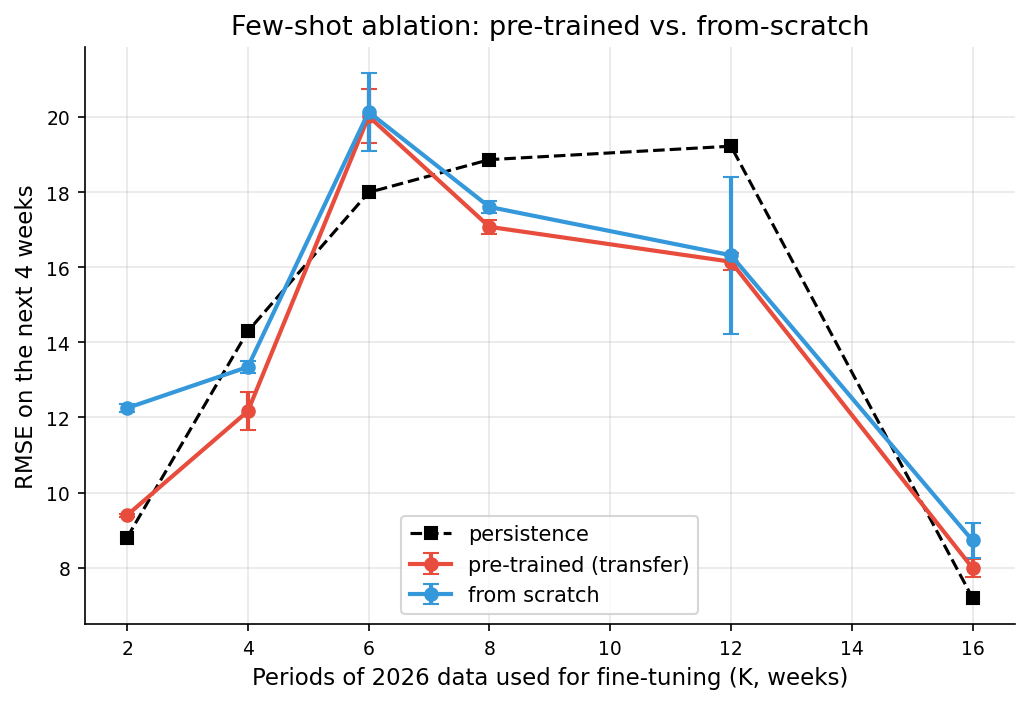

In [17]:

# MODULE 9.3 · Few-shot ablation: Does pre-training help when the target has only K periods of data?
# Train on the first K periods of the 2026 outbreak, evaluate on the next TL_EVAL_STEPS periods.

def tl_fewshot_ablation(pretrained, df_feat: pd.DataFrame, inc: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    dates = np.sort(df_feat['date'].unique())
    records = []
    for K in cfg.TL_K_LIST:
        if K + 2 > len(dates):
            continue
        tr_dates, ev_dates = dates[:K], dates[K:K + cfg.TL_EVAL_STEPS]
        tr = df_feat[df_feat['date'].isin(tr_dates)].sort_values(['zone', 'date'])
        ev = df_feat[df_feat['date'].isin(ev_dates)].sort_values(['zone', 'date'])
        if len(tr) < 6 or len(ev) < 5:
            continue
        Xtr, ytr, _, _ = tl_windows_for_rows(inc, tr, cfg.TL_SEQ_LEN)
        Xev, _, sev, yev_raw = tl_windows_for_rows(inc, ev, cfg.TL_SEQ_LEN)
        n_val = int(0.2 * len(tr)) if len(tr) >= 20 else 0                      # chronological validation tail
        order = np.argsort(tr['date'].to_numpy(), kind='stable')
        tr_idx, va_idx = order[:len(order) - n_val], order[len(order) - n_val:]
        rmse_naive = float(np.sqrt(np.mean((ev['lag_1'].to_numpy(float) - yev_raw) ** 2)))
        for seed in range(cfg.TL_SEEDS):
            for scratch in (False, True):
                m = finetune_encoder(pretrained, Xtr[tr_idx], ytr[tr_idx], Xtr[va_idx], ytr[va_idx], cfg,
                                     seed=seed, from_scratch=scratch)
                pred = tl_to_counts(predict_torch(m, Xev), sev)
                records.append(dict(K=K, n_train=len(tr), n_eval=len(ev), seed=seed,
                                    model='scratch' if scratch else 'transfer',
                                    RMSE=float(np.sqrt(np.mean((pred - yev_raw) ** 2))), RMSE_persistence=rmse_naive))
    return pd.DataFrame(records)


TL_ABLATION = pd.DataFrame()
if RUN_STATUS.get('transfer_learning') == 'ok':
    try:
        print("── Few-shot ablation ────────────────────────────────────────")
        TL_ABLATION = tl_fewshot_ablation(PRETRAINED_ENCODER, DF_FEAT, INC_TABLE, CFG)
        if len(TL_ABLATION):
            summ = (TL_ABLATION.groupby(['K', 'model'])['RMSE'].agg(['mean', 'std']).round(3).unstack('model'))
            naive = TL_ABLATION.groupby('K')[['n_train', 'n_eval', 'RMSE_persistence']].first().round(3)
            print(pd.concat([naive, summ], axis=1).to_string())
            fig, ax = plt.subplots(figsize=(8, 5))
            for model, color in (('transfer', PALETTE[1]), ('scratch', PALETTE[2])):
                s = TL_ABLATION[TL_ABLATION['model'] == model].groupby('K')['RMSE'].agg(['mean', 'std']).fillna(0)
                ax.errorbar(s.index, s['mean'], yerr=s['std'], marker='o', capsize=4, lw=2, color=color,
                            label='pre-trained (transfer)' if model == 'transfer' else 'from scratch')
            nv = TL_ABLATION.groupby('K')['RMSE_persistence'].first()
            ax.plot(nv.index, nv.values, 'k--', marker='s', label='persistence')
            ax.set_xlabel(f"Periods of 2026 data used for fine-tuning (K, {CFG.step_label}s)")
            ax.set_ylabel(f"RMSE on the next {CFG.TL_EVAL_STEPS} {CFG.step_label}s")
            ax.set_title("Few-shot ablation: pre-trained vs. from-scratch"); ax.legend(); ax.grid(True, alpha=0.3)
            save_fig(fig, "16_tl_fewshot_ablation.png")
            plt.show()
            RUN_STATUS['tl_fewshot_ablation'] = 'ok'
        else:
            RUN_STATUS['tl_fewshot_ablation'] = 'skipped: not enough rows for the K values'
            print("Not enough rows for the requested K values")
    except Exception as e:
        RUN_STATUS['tl_fewshot_ablation'] = f'failed: {e}'
        print(f"Few-shot ablation FAILED: {e}")
else:
    RUN_STATUS['tl_fewshot_ablation'] = 'skipped: transfer learning not run'
    print("Few-shot ablation skipped (transfer learning not run)")

## MODULE 10 · Spatio-Temporal Graph Neural Network

Forecasts **next-period new cases for every health zone**: a GRU encodes each zone's recent feature window, two GraphSAGE layers exchange information between neighbouring zones, and a head predicts `log1p(new cases)`. Edges are geographic (polygon contact, else known centroids) plus similarity edges computed on the **training period only**. A "no-graph" control (same network without neighbour aggregation) shows whether the graph helps. Implemented in plain PyTorch (dense adjacency, about 75 nodes), so `torch_geometric` is not required.

In [18]:

# MODULE 10.1 · Graph construction and spatio-temporal tensors
# 
def geographic_adjacency(zones: List[str]) -> Tuple[np.ndarray, str]:
    """Boolean adjacency from polygon contact (buffered by ~1 km) when GeoJSON polygons are available,
    otherwise k=3 nearest neighbours among zones with known centroids. Zones without geometry get no geographic edge."""
    Z = len(zones)
    A = np.zeros((Z, Z), dtype=bool)
    idx = [i for i, z in enumerate(zones) if z in GEO_ZONE_GEOMS]
    if GEO_AVAILABLE and len(idx) >= 2:
        from shapely.prepared import prep
        prepared = {i: prep(GEO_ZONE_GEOMS[zones[i]].buffer(0.01)) for i in idx}
        for a in idx:
            for b in idx:
                if b > a and prepared[a].intersects(GEO_ZONE_GEOMS[zones[b]]):
                    A[a, b] = A[b, a] = True
        return A, 'polygons'
    known = [(i, ZONE_GEO[z]) for i, z in enumerate(zones) if z in ZONE_GEO]
    if len(known) >= 4:
        coords = np.array([c for _, c in known])
        for a, (i, c) in enumerate(known):
            d = np.sqrt(((coords - np.array(c)) ** 2).sum(axis=1))
            for b in np.argsort(d)[1:4]:
                A[i, known[b][0]] = A[known[b][0], i] = True
        return A, 'approximate centroids'
    return A, 'none'


def similarity_adjacency(H: np.ndarray, first: np.ndarray, last_train_idx: int, thr: float, topk: int) -> np.ndarray:
    """Edges between zones whose log-incidence curves are correlated, using ONLY periods up to the end of the
    training window (the former version used the whole period, test included)."""
    Z = H.shape[0]
    LV = np.log1p(H[:, :last_train_idx + 1])
    t_idx = np.arange(LV.shape[1])
    corr = np.full((Z, Z), np.nan)
    for i in range(Z):
        for j in range(i + 1, Z):
            ov = (t_idx >= first[i]) & (t_idx >= first[j])
            if ov.sum() >= 6 and LV[i, ov].std() > 0 and LV[j, ov].std() > 0:
                corr[i, j] = corr[j, i] = np.corrcoef(LV[i, ov], LV[j, ov])[0, 1]
    A = np.zeros((Z, Z), dtype=bool)
    for i in range(Z):
        order = [j for j in np.argsort(-np.nan_to_num(corr[i], nan=-1)) if j != i and corr[i, j] >= thr][:topk]
        for j in order:
            A[i, j] = A[j, i] = True
    return A


def build_adjacency(arrays: Dict[str, Any], cfg: Config) -> Dict[str, Any]:
    zones, dates = arrays['zones'], arrays['dates']
    last_train_idx = int(np.flatnonzero(dates <= pd.Timestamp(cfg.TRAIN_END))[-1])
    A_geo, geo_src = geographic_adjacency(zones)
    A_sim = similarity_adjacency(arrays['H'], arrays['first'], last_train_idx, cfg.GNN_SIM_THRESHOLD, cfg.GNN_SIM_TOPK)
    A = (A_geo | A_sim)
    np.fill_diagonal(A, False)
    deg = A.sum(axis=1)
    A_norm = A / np.maximum(deg, 1)[:, None]                 # row-normalised mean aggregation
    print(f"Graph: {len(zones)} nodes | geographic edges: {int(A_geo.sum() // 2)} ({geo_src}) | "
          f"similarity edges (train only): {int(A_sim.sum() // 2)} | total: {int(A.sum() // 2)} | "
          f"isolated nodes: {int((deg == 0).sum())} | mean degree: {deg.mean():.1f}")
    return dict(A=A, A_norm=A_norm.astype(np.float32), geo_source=geo_src, n_geo=int(A_geo.sum() // 2),
                n_sim=int(A_sim.sum() // 2), n_edges=int(A.sum() // 2), isolated=int((deg == 0).sum()))


def build_gnn_tensors(df_feat: pd.DataFrame, feature_cols: List[str], prep: FeaturePrep,
                      arrays: Dict[str, Any], cfg: Config) -> Dict[str, Any]:
    """Arrays for the ST-GNN. Xn (T, Z, F) scaled features of every active zone-period (zeros otherwise),
    mask (T, Z) active cells, Yn (T, Z) new cases, Xw (T, W, Z, F) window ending at each period."""
    zones, dates = arrays['zones'], arrays['dates']
    Z, T, Fd, W = len(zones), len(dates), len(feature_cols), cfg.GNN_WINDOW      # Fd scaled features + 1 anchor channel
    zi, di = {z: i for i, z in enumerate(zones)}, {d: i for i, d in enumerate(dates)}
    Xs = prep.transform(df_feat[feature_cols].to_numpy())
    Xn = np.zeros((T, Z, Fd + 1), np.float32)
    mask = np.zeros((T, Z), bool)
    Yn = np.zeros((T, Z), np.float32)
    rt = np.array([di[d] for d in df_feat['date']])
    rz = np.array([zi[z] for z in df_feat['zone']])
    Xn[rt, rz, :Fd] = Xs
    Xn[rt, rz, Fd] = np.log1p(np.clip(df_feat['lag_1'].to_numpy(float), 0, None))   # unscaled anchor log1p(lag_1)
    mask[rt, rz], Yn[rt, rz] = True, df_feat['new_cases'].to_numpy(np.float32)
    Xw = np.zeros((T, W, Z, Fd + 1), np.float32)
    for t in range(T):
        for w in range(W):
            tt = t - W + 1 + w
            if tt >= 0:
                Xw[t, w] = Xn[tt]
    train_idx = [t for t in range(T) if dates[t] <= pd.Timestamp(cfg.TRAIN_END) and mask[t].any()]
    val_idx = train_idx[-cfg.VAL_STEPS:] if len(train_idx) > cfg.VAL_STEPS + 3 else []
    fit_idx = [t for t in train_idx if t not in val_idx]
    t_end = pd.Timestamp(cfg.TEST_END) if cfg.TEST_END else dates[-1]
    test_idx = [t for t in range(T) if pd.Timestamp(cfg.TEST_START) <= dates[t] <= t_end and mask[t].any()]
    return dict(zones=zones, dates=dates, Xn=Xn, mask=mask, Yn=Yn, Xw=Xw, fit_idx=fit_idx, val_idx=val_idx,
                test_idx=test_idx, zi=zi, di=di)


print("── Spatio-temporal graph ────────────────────────────────────────")
GNN_ADJ = build_adjacency(HIST_ARRAYS, CFG)
GNN_DATA = build_gnn_tensors(DF_FEAT, FEATURE_COLS, SCALER, HIST_ARRAYS, CFG)
GNN_TEST_ROW_T = np.array([GNN_DATA['di'][d] for d in TEST_DF['date']])
GNN_TEST_ROW_Z = np.array([GNN_DATA['zi'][z] for z in TEST_DF['zone']])
print(f"Periods → fit: {len(GNN_DATA['fit_idx'])} | validation: {len(GNN_DATA['val_idx'])} | test: {len(GNN_DATA['test_idx'])} "
      f"| window: {CFG.GNN_WINDOW} {CFG.step_label}s | node features: {len(FEATURE_COLS)} + 1 anchor")

── Spatio-temporal graph ────────────────────────────────────────
Graph: 74 nodes | geographic edges: 135 (polygons) | similarity edges (train only): 112 | total: 228 | isolated nodes: 3 | mean degree: 6.2
Periods → fit: 16 | validation: 3 | test: 7 | window: 4 weeks | node features: 13 + 1 anchor



── ST-GNN training ──────────────────────────────────────────
   ST-GNN-GraphSAGE           46 epochs | best epoch    6 | best val loss 0.18580
   ST-GNN-GraphSAGE         RMSE=   6.0304 MAE=  2.8118 R²= 0.8429 skill=  0.009 F1=0.6667
   ST-GRU-NoGraph             44 epochs | best epoch    4 | best val loss 0.17654
   ST-GRU-NoGraph           RMSE=   6.4519 MAE=  2.9131 R²= 0.8201 skill= -0.060 F1=0.6133
Saved figure: 06_gnn_results.png


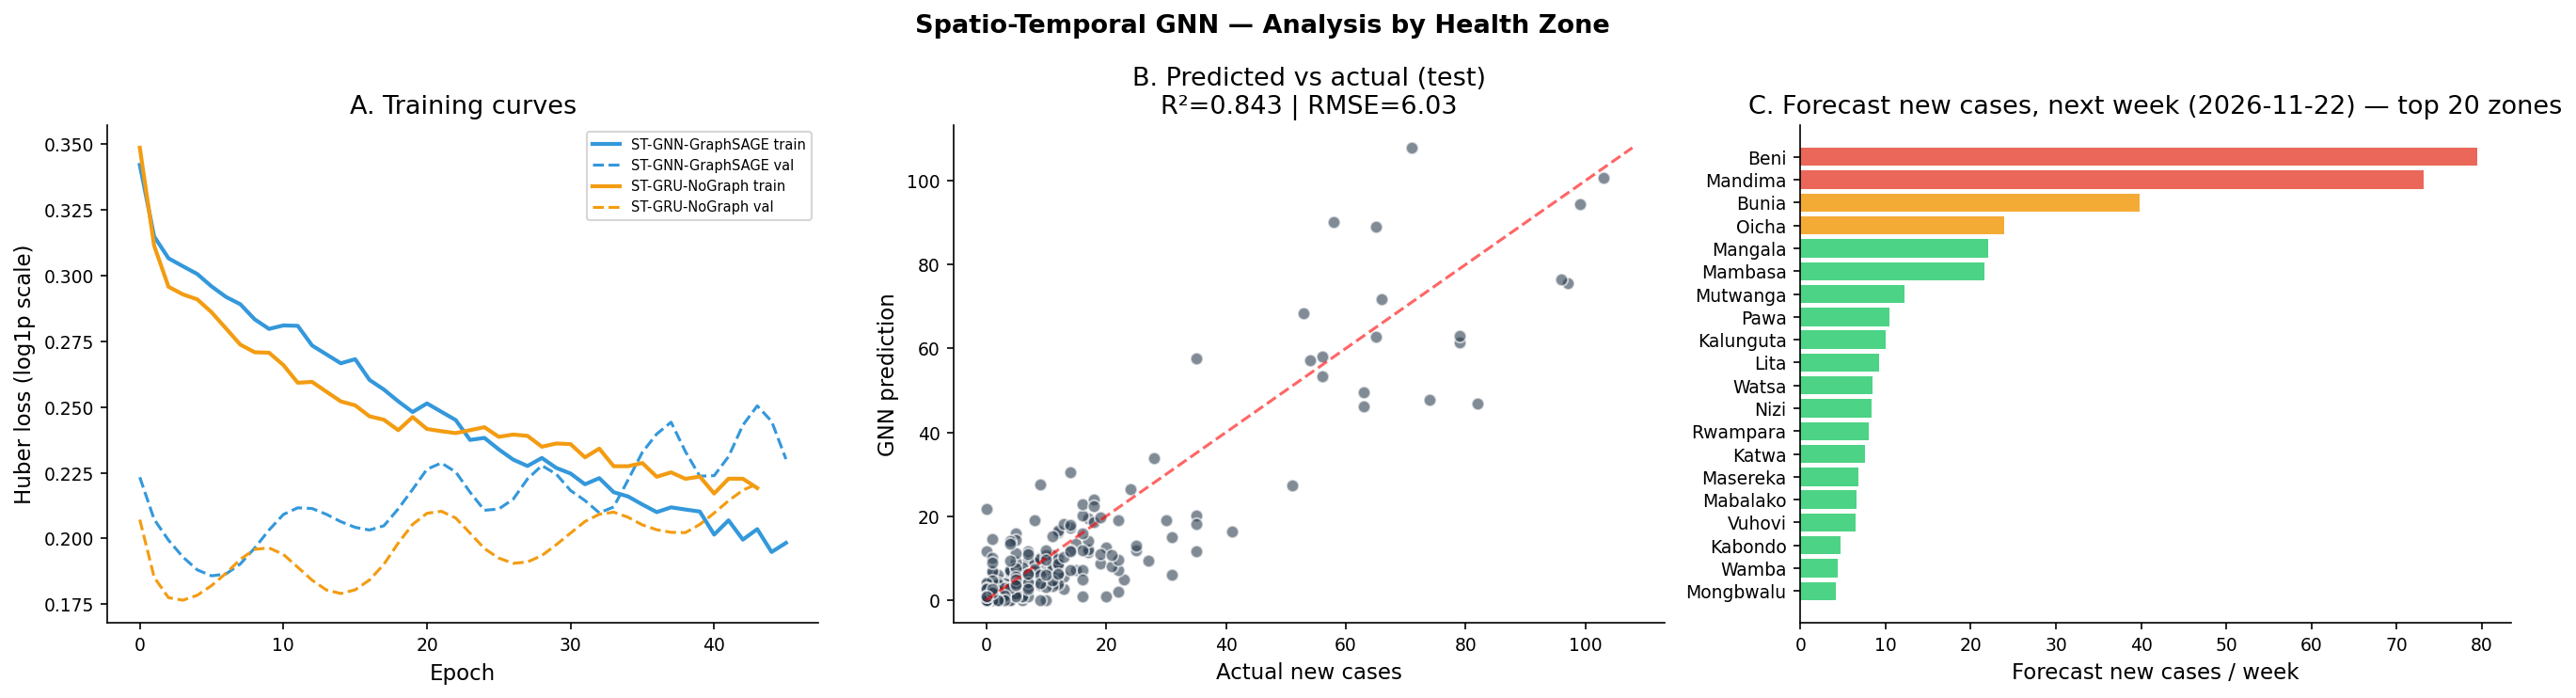

In [19]:

# MODULE 10.2 · Model, training, evaluation, and next-period risk scores.

if TORCH_OK:
    class DenseSAGELayer(nn.Module):
        """GraphSAGE (mean aggregator) with a dense, row-normalised adjacency matrix."""
        def __init__(self, d_in: int, d_out: int):
            super().__init__()
            self.self_lin = nn.Linear(d_in, d_out)
            self.neigh_lin = nn.Linear(d_in, d_out, bias=False)

        def forward(self, h, A):                         # h: (B, N, d), A: (N, N)
            return self.self_lin(h) + self.neigh_lin(torch.matmul(A, h))

    class STGraphSAGE(nn.Module):
        """GRU over each zone's window -> GraphSAGE layers over zones -> next-period log1p(new cases)."""
        def __init__(self, in_dim: int, hidden: int = 32, n_layers: int = 2, dropout: float = 0.2, use_graph: bool = True):
            super().__init__()
            self.use_graph = use_graph
            self.gru = nn.GRU(in_dim, hidden, batch_first=True)
            self.convs = nn.ModuleList([DenseSAGELayer(hidden, hidden) for _ in range(n_layers)])
            self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
            self.drop = nn.Dropout(dropout)
            self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))

        def forward(self, x, A):                         # x: (B, T, N, F)
            B, T, N, Fd = x.shape
            h = x.permute(0, 2, 1, 3).reshape(B * N, T, Fd)
            _, hn = self.gru(h)
            h = hn[-1].reshape(B, N, -1)
            for conv, norm in zip(self.convs, self.norms):
                z = conv(h, A) if self.use_graph else conv.self_lin(h)
                h = h + self.drop(torch.relu(norm(z)))
            return x[:, -1, :, -1] + self.head(h).squeeze(-1)     # (B, N): anchor log1p(lag_1) + learned log growth

    def train_stgnn(model, G: Dict, A_np: np.ndarray, cfg: Config, seed: int = 0, name: str = ''):
        """Full-batch training over periods with a masked Huber loss and chronological early stopping."""
        torch.manual_seed(seed)
        model = model.to(DEVICE)
        Xw = torch.as_tensor(G['Xw'], device=DEVICE)
        Y = torch.as_tensor(np.log1p(G['Yn']), device=DEVICE)
        M = torch.as_tensor(G['mask'], device=DEVICE)
        A = torch.as_tensor(A_np, device=DEVICE)
        fit, val = G['fit_idx'], G['val_idx']
        opt = torch.optim.Adam(model.parameters(), lr=cfg.GNN_LR, weight_decay=1e-4)
        best, best_state, best_ep, wait = float('inf'), None, 0, 0
        hist = {'train': [], 'val': []}
        for epoch in range(cfg.GNN_EPOCHS):
            model.train()
            opt.zero_grad()
            out = model(Xw[fit], A)
            m = M[fit]
            loss = tnf.huber_loss(out[m], Y[fit][m])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            hist['train'].append(loss.item())
            monitored = loss.item()
            if val:
                model.eval()
                with torch.no_grad():
                    ov, mv = model(Xw[val], A), M[val]
                    vloss = tnf.huber_loss(ov[mv], Y[val][mv]).item() if mv.any() else loss.item()
                hist['val'].append(vloss)
                monitored = vloss
            if monitored < best - 1e-6:
                best, best_ep, wait = monitored, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= cfg.GNN_PATIENCE:
                    break
        if best_state is not None:
            model.load_state_dict(best_state)
        hist['best_epoch'] = best_ep
        print(f"   {name:24s} {epoch + 1:4d} epochs | best epoch {best_ep + 1:4d} | best {'val' if val else 'train'} loss {best:.5f}")
        return model, hist

    def predict_stgnn(model, G: Dict, A_np: np.ndarray, idx: List[int]) -> np.ndarray:
        """Counts (len(idx), Z) for the periods in idx."""
        model.eval()
        with torch.no_grad():
            out = model(torch.as_tensor(G['Xw'][idx], device=DEVICE), torch.as_tensor(A_np, device=DEVICE)).cpu().numpy()
        return np.clip(np.expm1(out), 0, None)


GNN_MODELS: Dict[str, Any] = {}
GNN_HISTORY: Dict[str, Dict] = {}
GNN_FORECAST = pd.DataFrame()
if not TORCH_OK:
    RUN_STATUS['gnn'] = 'skipped: PyTorch unavailable'
    print("GNN skipped: PyTorch unavailable")
elif len(GNN_DATA['fit_idx']) < 5 or len(GNN_DATA['test_idx']) < 1:
    RUN_STATUS['gnn'] = 'skipped: too few periods'
    print("GNN skipped: too few periods")
else:
    print("\n── ST-GNN training ──────────────────────────────────────────")
    for _name, _use_graph in [('ST-GNN-GraphSAGE', True), ('ST-GRU-NoGraph', False)]:
        try:
            _m = STGraphSAGE(len(FEATURE_COLS) + 1, CFG.GNN_HIDDEN, CFG.GNN_LAYERS, CFG.GNN_DROPOUT, _use_graph)
            _m, _h = train_stgnn(_m, GNN_DATA, GNN_ADJ['A_norm'], CFG, seed=CFG.SEED, name=_name)
            counts = predict_stgnn(_m, GNN_DATA, GNN_ADJ['A_norm'], GNN_DATA['test_idx'])      # (n_test_periods, Z)
            pos = {t: i for i, t in enumerate(GNN_DATA['test_idx'])}
            preds = counts[[pos[t] for t in GNN_TEST_ROW_T], GNN_TEST_ROW_Z]                    # aligned with TEST_DF
            register_result(_name, preds, 'graph', _m)
            GNN_MODELS[_name], GNN_HISTORY[_name] = _m, _h
            RUN_STATUS[_name] = 'ok'
        except Exception as e:
            RUN_STATUS[_name] = f'failed: {e}'
            print(f"   FAILED {_name}: {e}")

    if 'ST-GNN-GraphSAGE' in GNN_MODELS:
        try:                                              # forecast of the first future period for every active zone
            X_next, next_date = next_step_feature_matrix(HIST_ARRAYS, CFG)
            x_next = np.c_[SCALER.transform(X_next), np.log1p(np.clip(X_next[:, LAG_IDX], 0, None))].astype(np.float32)
            W, Tn = CFG.GNN_WINDOW, GNN_DATA['Xn'].shape[0]
            win = np.zeros((1, W, len(ZONES), len(FEATURE_COLS) + 1), np.float32)
            win[0, :W - 1] = GNN_DATA['Xn'][Tn - (W - 1):]
            win[0, W - 1] = x_next
            m = GNN_MODELS['ST-GNN-GraphSAGE']
            m.eval()
            with torch.no_grad():
                out = m(torch.as_tensor(win, device=DEVICE), torch.as_tensor(GNN_ADJ['A_norm'], device=DEVICE)).cpu().numpy()[0]
            active = (Tn - HIST_ARRAYS['first']) >= 1
            GNN_FORECAST = pd.DataFrame({'zone': ZONES, 'forecast_next': np.clip(np.expm1(out), 0, None),
                                         'last_observed': HIST_ARRAYS['H'][:, -1], 'active': active})
            GNN_FORECAST = GNN_FORECAST[GNN_FORECAST['active']].sort_values('forecast_next', ascending=False)
            GNN_FORECAST.attrs['next_date'] = next_date
        except Exception as e:
            print(f"   next-period forecast failed: {e}")


def plot_gnn_results(cfg: Config) -> None:
    """Training curves, predicted vs actual on the test rows, and next-period risk ranking."""
    if 'ST-GNN-GraphSAGE' not in GNN_MODELS:
        print("No GNN results to plot")
        return
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Spatio-Temporal GNN — Analysis by Health Zone", fontsize=13, fontweight='bold')
    ax = axes[0]
    for name, color in (('ST-GNN-GraphSAGE', PALETTE[2]), ('ST-GRU-NoGraph', PALETTE[4])):
        if name in GNN_HISTORY:
            ax.plot(GNN_HISTORY[name]['train'], color=color, lw=2, label=f"{name} train")
            if GNN_HISTORY[name]['val']:
                ax.plot(GNN_HISTORY[name]['val'], color=color, lw=1.5, ls='--', label=f"{name} val")
    ax.set_title("A. Training curves"); ax.set_xlabel("Epoch"); ax.set_ylabel("Huber loss (log1p scale)"); ax.legend(fontsize=7)
    ax = axes[1]
    yp = ALL_PREDS['ST-GNN-GraphSAGE']
    ax.scatter(Y_TEST, yp, alpha=0.6, color=PALETTE[0], edgecolors='white', s=40)
    lim = max(Y_TEST.max(), yp.max(), 1)
    ax.plot([0, lim], [0, lim], 'r--', lw=1.5, alpha=0.6)
    r = next(x for x in ALL_RESULTS if x['Model'] == 'ST-GNN-GraphSAGE')
    ax.set_title(f"B. Predicted vs actual (test)\nR²={r['R2']:.3f} | RMSE={r['RMSE']:.2f}")
    ax.set_xlabel("Actual new cases"); ax.set_ylabel("GNN prediction")
    ax = axes[2]
    if len(GNN_FORECAST):
        top = GNN_FORECAST.head(20).iloc[::-1]
        mx = max(top['forecast_next'].max(), 1e-8)
        colors = [PALETTE[1] if v / mx > 0.6 else PALETTE[4] if v / mx > 0.3 else PALETTE[3] for v in top['forecast_next']]
        ax.barh(top['zone'], top['forecast_next'], color=colors, alpha=0.85)
        ax.set_title(f"C. Forecast new cases, next {cfg.step_label} "
                     f"({GNN_FORECAST.attrs.get('next_date', pd.NaT):%Y-%m-%d}) — top 20 zones")
        ax.set_xlabel(f"Forecast new cases / {cfg.step_label}")
    plt.tight_layout()
    save_fig(fig, "06_gnn_results.png")
    plt.show()


plot_gnn_results(CFG)

## MODULE 11 · Explainable AI: SHAP and LIME

SHAP uses the exact `TreeExplainer` on the whole test set (Kernel SHAP only as a documented fallback). LIME explains the best classical model **in raw feature units** (counts, not scaled values).

── SHAP ─────────────────────────────────────────────────────
   RandomForest: TreeSHAP (exact)
   RandomForest_logdelta: TreeSHAP (exact)
   XGBoost: TreeSHAP (exact)
   XGBoost_logdelta: TreeSHAP (exact)
   LightGBM: TreeSHAP (exact)
   LightGBM_logdelta: TreeSHAP (exact)
Saved figure: 07_shap_comparison.png


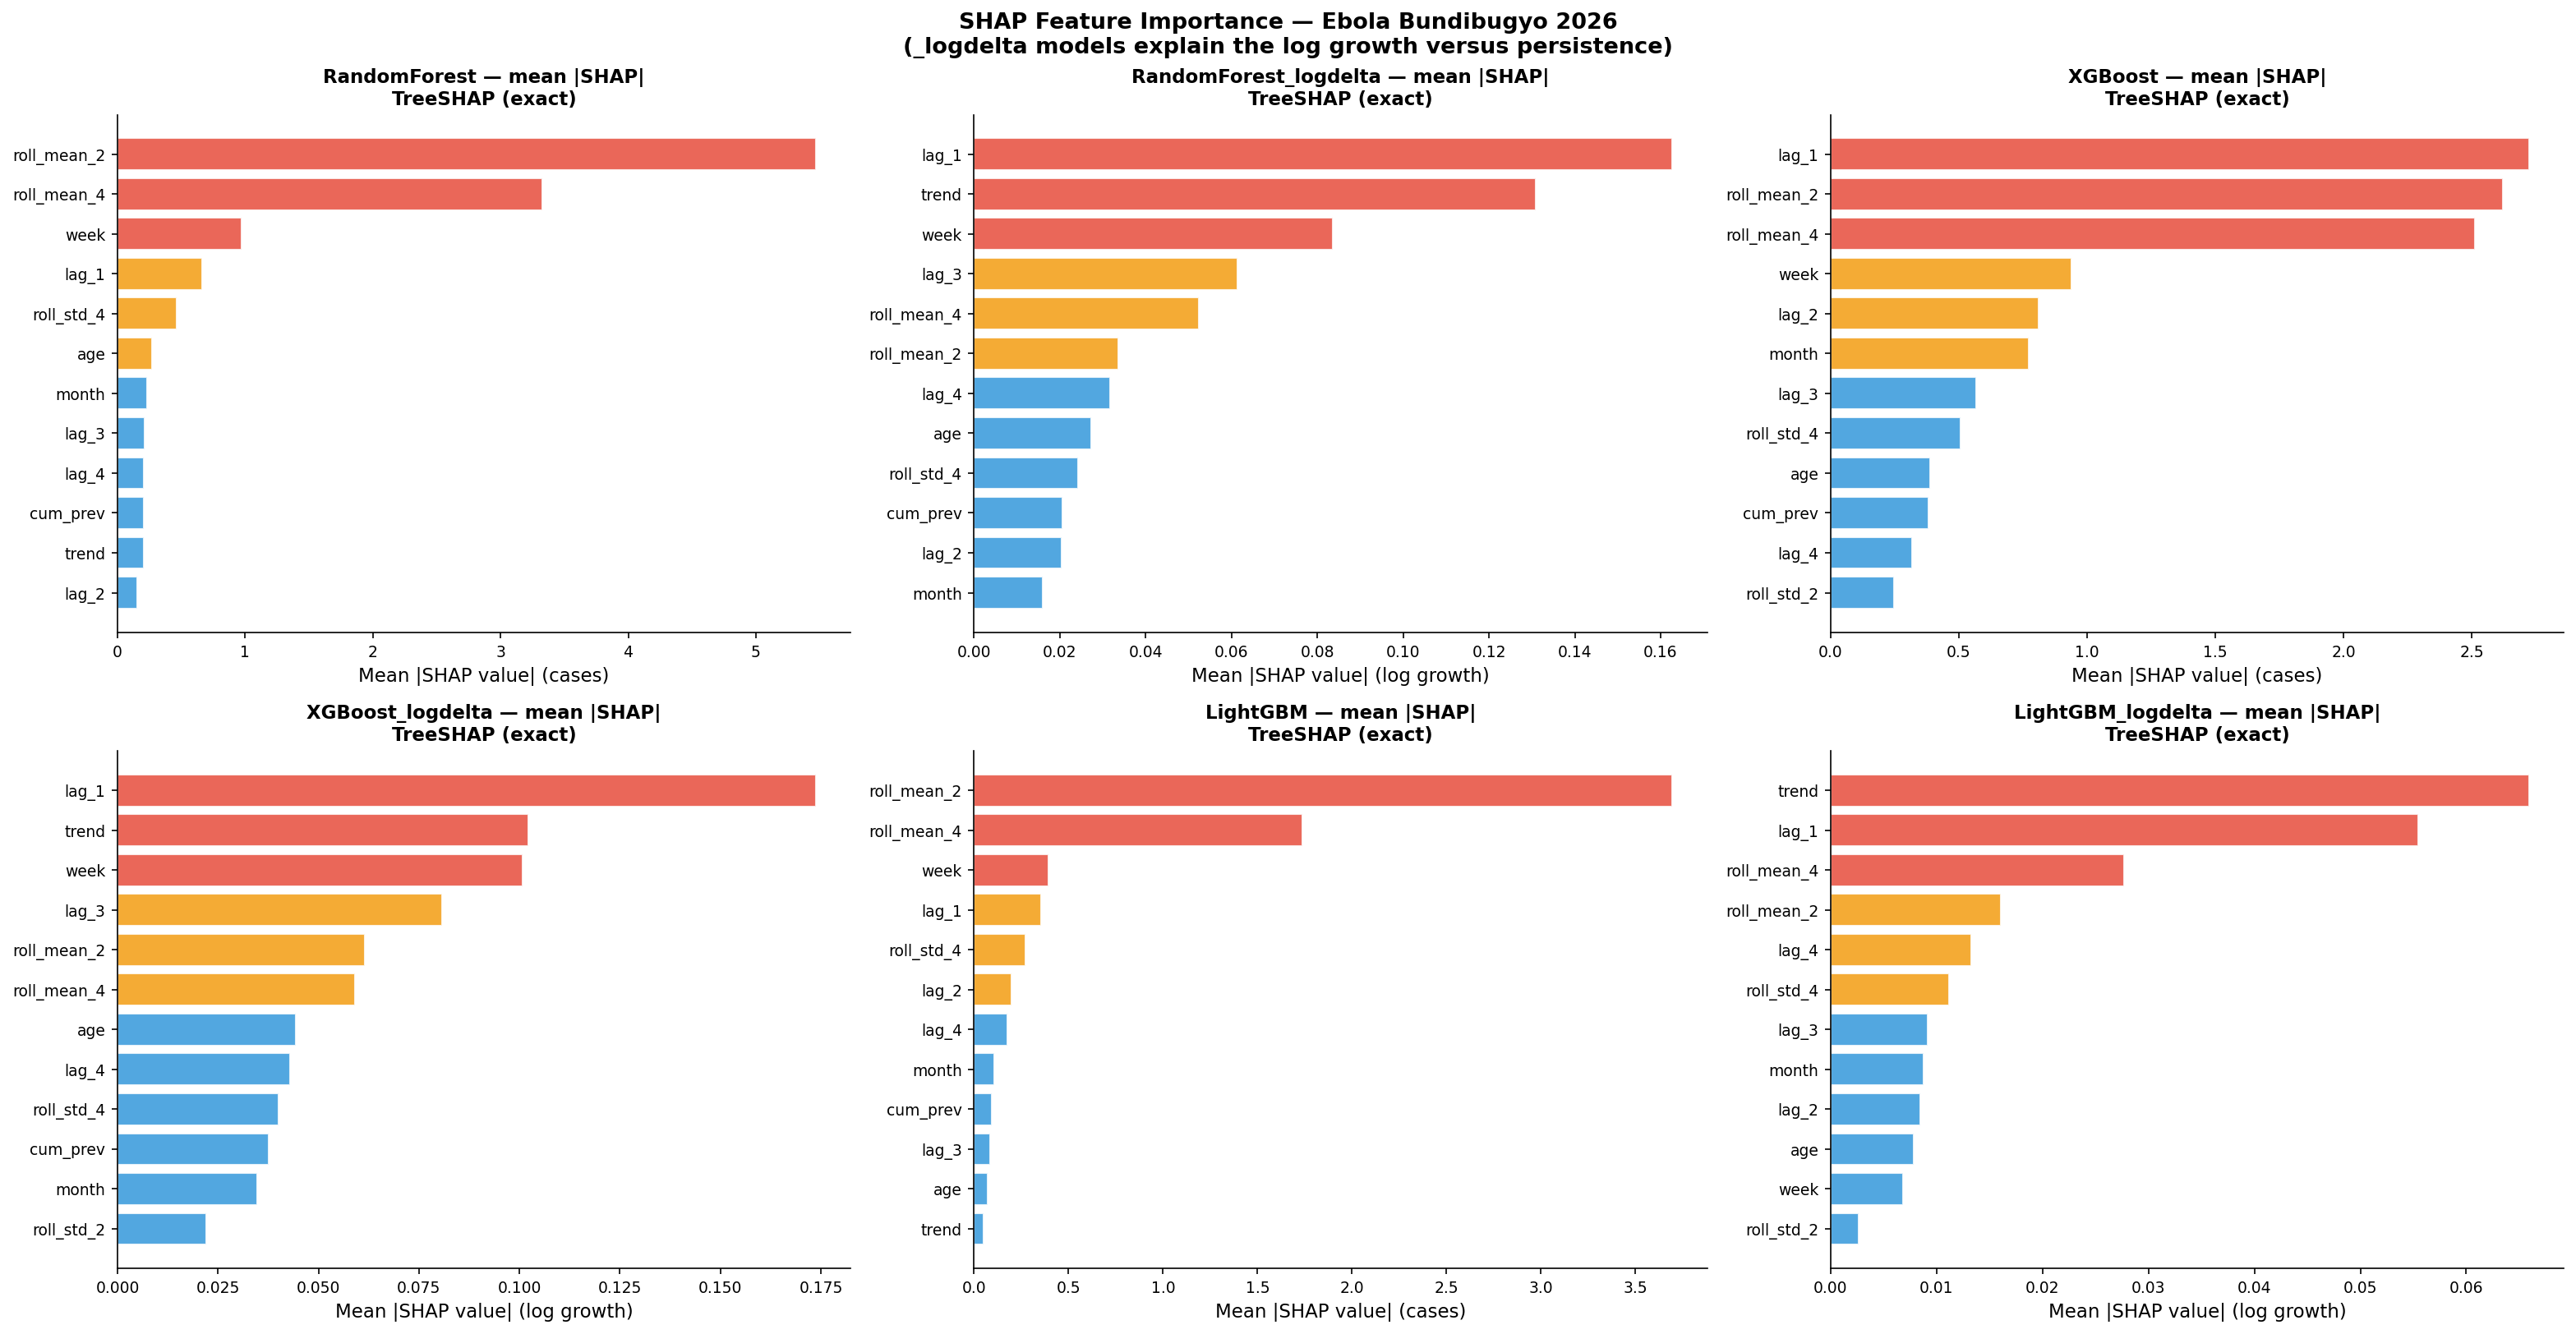

   Spearman (RandomForest vs RandomForest_logdelta): r=0.4780 p=0.0985
   Spearman (RandomForest vs XGBoost): r=0.7527 p=0.0030
   Spearman (RandomForest vs XGBoost_logdelta): r=0.5220 p=0.0673
   Spearman (RandomForest vs LightGBM): r=0.8022 p=0.0010
   Spearman (RandomForest vs LightGBM_logdelta): r=0.3626 p=0.2233
   Spearman (RandomForest_logdelta vs XGBoost): r=0.3352 p=0.2629
   Spearman (RandomForest_logdelta vs XGBoost_logdelta): r=0.9725 p=0.0000
   Spearman (RandomForest_logdelta vs LightGBM): r=0.3242 p=0.2799
   Spearman (RandomForest_logdelta vs LightGBM_logdelta): r=0.6429 p=0.0178
   Spearman (XGBoost vs XGBoost_logdelta): r=0.3077 p=0.3064
   Spearman (XGBoost vs LightGBM): r=0.8407 p=0.0003
   Spearman (XGBoost vs LightGBM_logdelta): r=0.2637 p=0.3839
   Spearman (XGBoost_logdelta vs LightGBM): r=0.2582 p=0.3943
   Spearman (XGBoost_logdelta vs LightGBM_logdelta): r=0.5989 p=0.0306
   Spearman (LightGBM vs LightGBM_logdelta): r=0.3407 p=0.2547

── LIME (best classical 

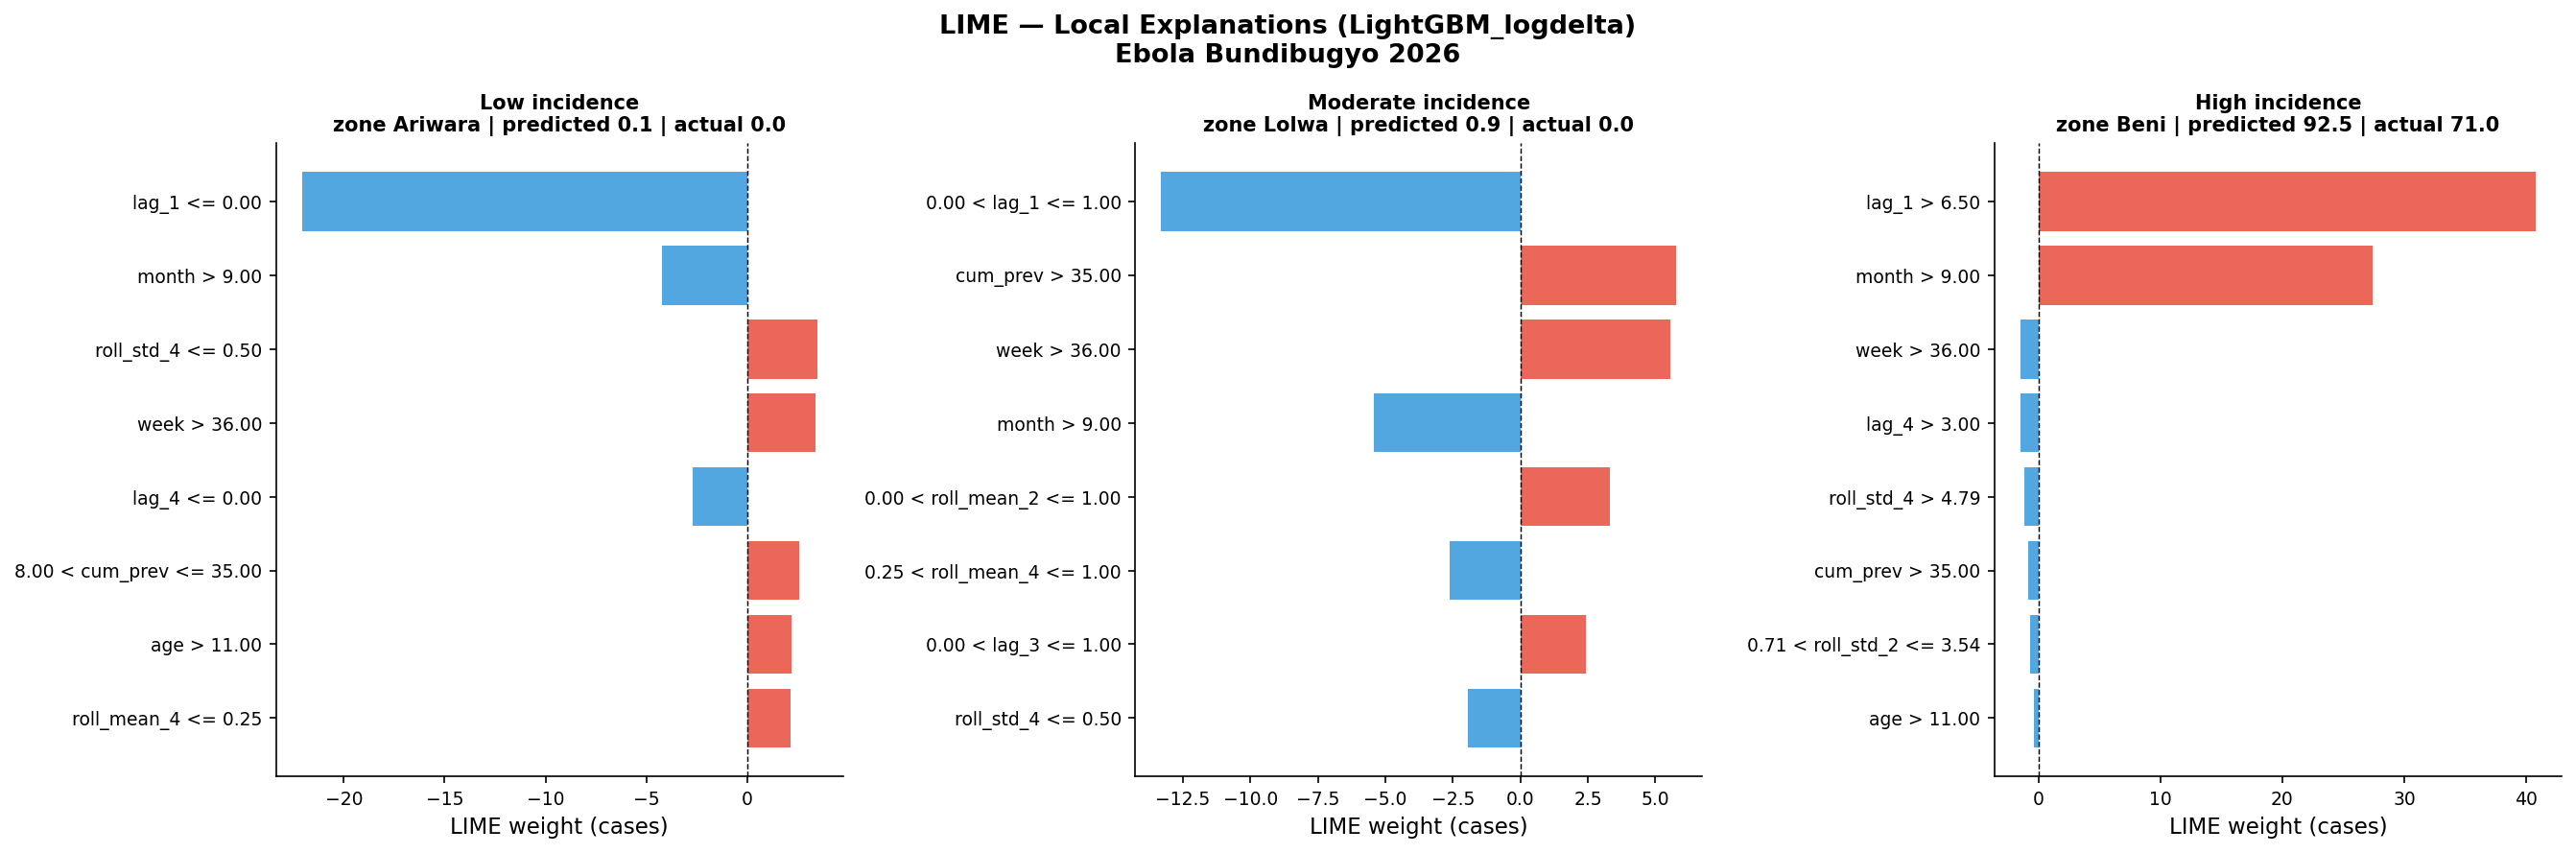


Top 5 LIME conditions (mean |weight|):
   lag_1 > 6.50                      : 40.7706
   lag_1 <= 0.00                     : 22.0872
   0.00 < lag_1 <= 1.00              : 13.3128
   month > 9.00                      : 12.3526
   week > 36.00                      : 3.4782


In [20]:

# MODULE 11 · XAI — SHAP & LIME

def run_shap_analysis(models: Dict, X_train: np.ndarray, X_test: np.ndarray, feature_names: List[str], cfg: Config) -> Dict:
    """Mean |SHAP| of the tree-based models. Exact TreeSHAP on the whole test set; if a model is not supported,
    Kernel SHAP on at most 50 test rows (the method used is printed and written in the panel title)."""
    shap_results: Dict[str, pd.DataFrame] = {}
    if not SHAP_OK:
        print("shap not installed — SHAP analysis skipped")
        return shap_results
    tree_models = {k: models[k] for k in TREE_MODEL_NAMES if k in models}
    if not tree_models:
        print("No tree-based model available for SHAP")
        return shap_results
    n_models = len(tree_models)
    ncols = min(3, n_models)
    nrows = (n_models + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5.5 * nrows), squeeze=False)
    methods = {}
    for ax, (name, model) in zip(axes.flatten(), tree_models.items()):
        sv, method = None, ''
        try:
            sv = shap.TreeExplainer(model).shap_values(X_test)
            sv = sv[0] if isinstance(sv, list) else sv
            method = 'TreeSHAP (exact)'
        except Exception as e1:
            print(f"   TreeExplainer unavailable for {name}: {str(e1)[:80]}")
        if sv is None:
            try:
                bg = shap.kmeans(X_train, min(len(X_train), 50))
                sv = shap.KernelExplainer(lambda x, m=model: m.predict(np.asarray(x)), bg).shap_values(
                    X_test[:min(50, len(X_test))], silent=True)
                sv = sv[0] if isinstance(sv, list) else sv
                method = 'Kernel SHAP (50 rows)'
            except Exception as e2:
                ax.text(0.5, 0.5, f"SHAP unavailable: {str(e2)[:60]}", ha='center', va='center', transform=ax.transAxes,
                        fontsize=9, color='gray')
                print(f"   SHAP failed for {name}: {e2}")
                continue
        ms = np.abs(np.asarray(sv)).mean(axis=0)
        sdf = pd.DataFrame({'feature': feature_names[:len(ms)], 'mean_shap': ms}).sort_values('mean_shap', ascending=True)
        top = sdf.tail(12)
        q75, q50 = top['mean_shap'].quantile(0.75), top['mean_shap'].quantile(0.50)
        ax.barh(top['feature'], top['mean_shap'], alpha=0.85, edgecolor='white',
                color=[PALETTE[1] if v > q75 else PALETTE[4] if v > q50 else PALETTE[2] for v in top['mean_shap']])
        ax.set_title(f"{name} — mean |SHAP|\n{method}", fontweight='bold', fontsize=11)
        ax.set_xlabel("Mean |SHAP value| (log growth)" if is_delta(name) else "Mean |SHAP value| (cases)")
        shap_results[name] = sdf
        methods[name] = method
        print(f"   {name}: {method}")
    for ax in axes.flatten()[n_models:]:
        ax.axis('off')
    plt.suptitle("SHAP Feature Importance — Ebola Bundibugyo 2026\n(_logdelta models explain the log growth versus persistence)", fontsize=13, fontweight='bold')
    plt.tight_layout()
    save_fig(fig, "07_shap_comparison.png")
    plt.show()
    names = list(shap_results)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            common = list(set(shap_results[names[i]]['feature']) & set(shap_results[names[j]]['feature']))
            if len(common) >= 3:
                v1 = shap_results[names[i]].set_index('feature').loc[common, 'mean_shap'].to_numpy()
                v2 = shap_results[names[j]].set_index('feature').loc[common, 'mean_shap'].to_numpy()
                r, p = stats.spearmanr(v1, v2)
                print(f"   Spearman ({names[i]} vs {names[j]}): r={r:.4f} p={p:.4f}")
    if shap_results:
        pd.concat({k: v.set_index('feature')['mean_shap'] for k, v in shap_results.items()}, axis=1).to_csv(
            cfg.REPORT_DIR / "shap_importance.csv")
    return shap_results


def run_lime_analysis(model, prep: FeaturePrep, train_df: pd.DataFrame, test_df: pd.DataFrame, feature_cols: List[str],
                      y_test: np.ndarray, cfg: Config, model_name: str) -> None:
    """LIME on three test instances (low / moderate / high predicted incidence), in raw feature units."""
    if not LIME_OK:
        print("lime not installed — LIME analysis skipped")
        return
    try:
        X_tr_raw, X_te_raw = train_df[feature_cols].to_numpy(float), test_df[feature_cols].to_numpy(float)
        predict_raw = lambda Xr: predict_counts_raw(model_name, model, Xr)      # counts, whatever the target formulation
        explainer = lime.lime_tabular.LimeTabularExplainer(training_data=X_tr_raw, feature_names=feature_cols,
                                                           mode='regression', random_state=cfg.SEED,
                                                           discretize_continuous=True)
        preds = predict_raw(X_te_raw)
        order = np.argsort(preds)
        instances = {'Low incidence': order[0], 'Moderate incidence': order[len(order) // 2], 'High incidence': order[-1]}
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        fig.suptitle(f"LIME — Local Explanations ({model_name})\nEbola Bundibugyo 2026", fontsize=13, fontweight='bold')
        records = []
        for ax, (label, idx) in zip(axes, instances.items()):
            exp = explainer.explain_instance(X_te_raw[idx], predict_raw, num_features=8, num_samples=500)
            feat_imp = exp.as_list()
            names = [f[0][:28] + ('…' if len(f[0]) > 28 else '') for f in feat_imp]
            weights = [f[1] for f in feat_imp]
            ax.barh(names[::-1], weights[::-1], color=[PALETTE[1] if w > 0 else PALETTE[2] for w in weights[::-1]], alpha=0.85)
            ax.axvline(0, color='black', lw=0.7, ls='--')
            ax.set_title(f"{label}\nzone {test_df['zone'].iloc[idx]} | predicted {preds[idx]:.1f} | actual {y_test[idx]:.1f}",
                         fontweight='bold', fontsize=10)
            ax.set_xlabel("LIME weight (cases)")
            records += [{'instance': label, 'zone': test_df['zone'].iloc[idx], 'feature': f[0], 'weight': f[1],
                         'abs_weight': abs(f[1])} for f in feat_imp]
        plt.tight_layout()
        save_fig(fig, "08_lime_explanations.png")
        plt.show()
        lime_df = pd.DataFrame(records)
        lime_df.to_csv(cfg.REPORT_DIR / "lime_explanations.csv", index=False)
        print("\nTop 5 LIME conditions (mean |weight|):")
        for feat, w in lime_df.groupby('feature')['abs_weight'].mean().sort_values(ascending=False).head(5).items():
            print(f"   {feat:<34}: {w:.4f}")
    except Exception as e:
        print(f"LIME failed: {e}")


def best_classical_name() -> Optional[str]:
    """Classical model with the lowest test RMSE (naive references excluded)."""
    cands = [r for r in ALL_RESULTS if MODEL_FAMILY.get(r['Model']) == 'classical' and r['Model'] in ALL_MODELS]
    return min(cands, key=lambda r: r['RMSE'])['Model'] if cands else None


BEST_CLASSICAL = best_classical_name()
print("── SHAP ─────────────────────────────────────────────────────")
SHAP_RESULTS = run_shap_analysis(ALL_MODELS, X_TRAIN, X_TEST, FEATURE_COLS, CFG)
RUN_STATUS['shap'] = 'ok' if SHAP_RESULTS else ('skipped: shap not installed' if not SHAP_OK else 'failed')
print(f"\n── LIME (best classical model: {BEST_CLASSICAL}) ───────────────────")
if BEST_CLASSICAL:
    run_lime_analysis(ALL_MODELS[BEST_CLASSICAL], SCALER, TRAIN_DF, TEST_DF, FEATURE_COLS, Y_TEST, CFG, BEST_CLASSICAL)
    RUN_STATUS['lime'] = 'ok' if LIME_OK else 'skipped: lime not installed'

## MODULE 12 · Final Evaluation, Cross-Validation, Probabilistic Forecast and Export

All models (naive references included) are compared on the same test rows. A model is only useful if its **skill versus persistence is positive**.

COMPLETE MODEL COMPARISON — Ebola Bundibugyo 2026
Resolution: W | test 2026-10-04 → 2026-11-15 | high-risk threshold: 18.0 cases/week | persistence RMSE: 6.0852
                    Model    Family   RMSE    MAE   MAPE     R2  Skill_vs_naive  Accuracy  Precision  Recall     F1    AUC
                  TL-LSTM  transfer 5.7499 2.6999  66.84 0.8571          0.0551    0.9339     0.6429  0.6000 0.6207 0.9540
        LightGBM_logdelta classical 5.8941 2.7965  73.07 0.8499          0.0314    0.9399     0.6829  0.6222 0.6512 0.9508
         ST-GNN-GraphSAGE     graph 6.0304 2.8118  78.81 0.8429          0.0090    0.9439     0.7179  0.6222 0.6667 0.9517
               Naive_lag1     naive 6.0852 2.8537  83.30 0.8400          0.0000    0.9359     0.6444  0.6444 0.6444 0.9496
        Naive_roll_mean_4     naive 6.0909 2.8948  76.54 0.8397         -0.0009    0.9319     0.6122  0.6667 0.6383 0.9515
               SVR_Linear classical 6.1870 2.8205  66.38 0.8346         -0.0167    0.9499     0.8125 

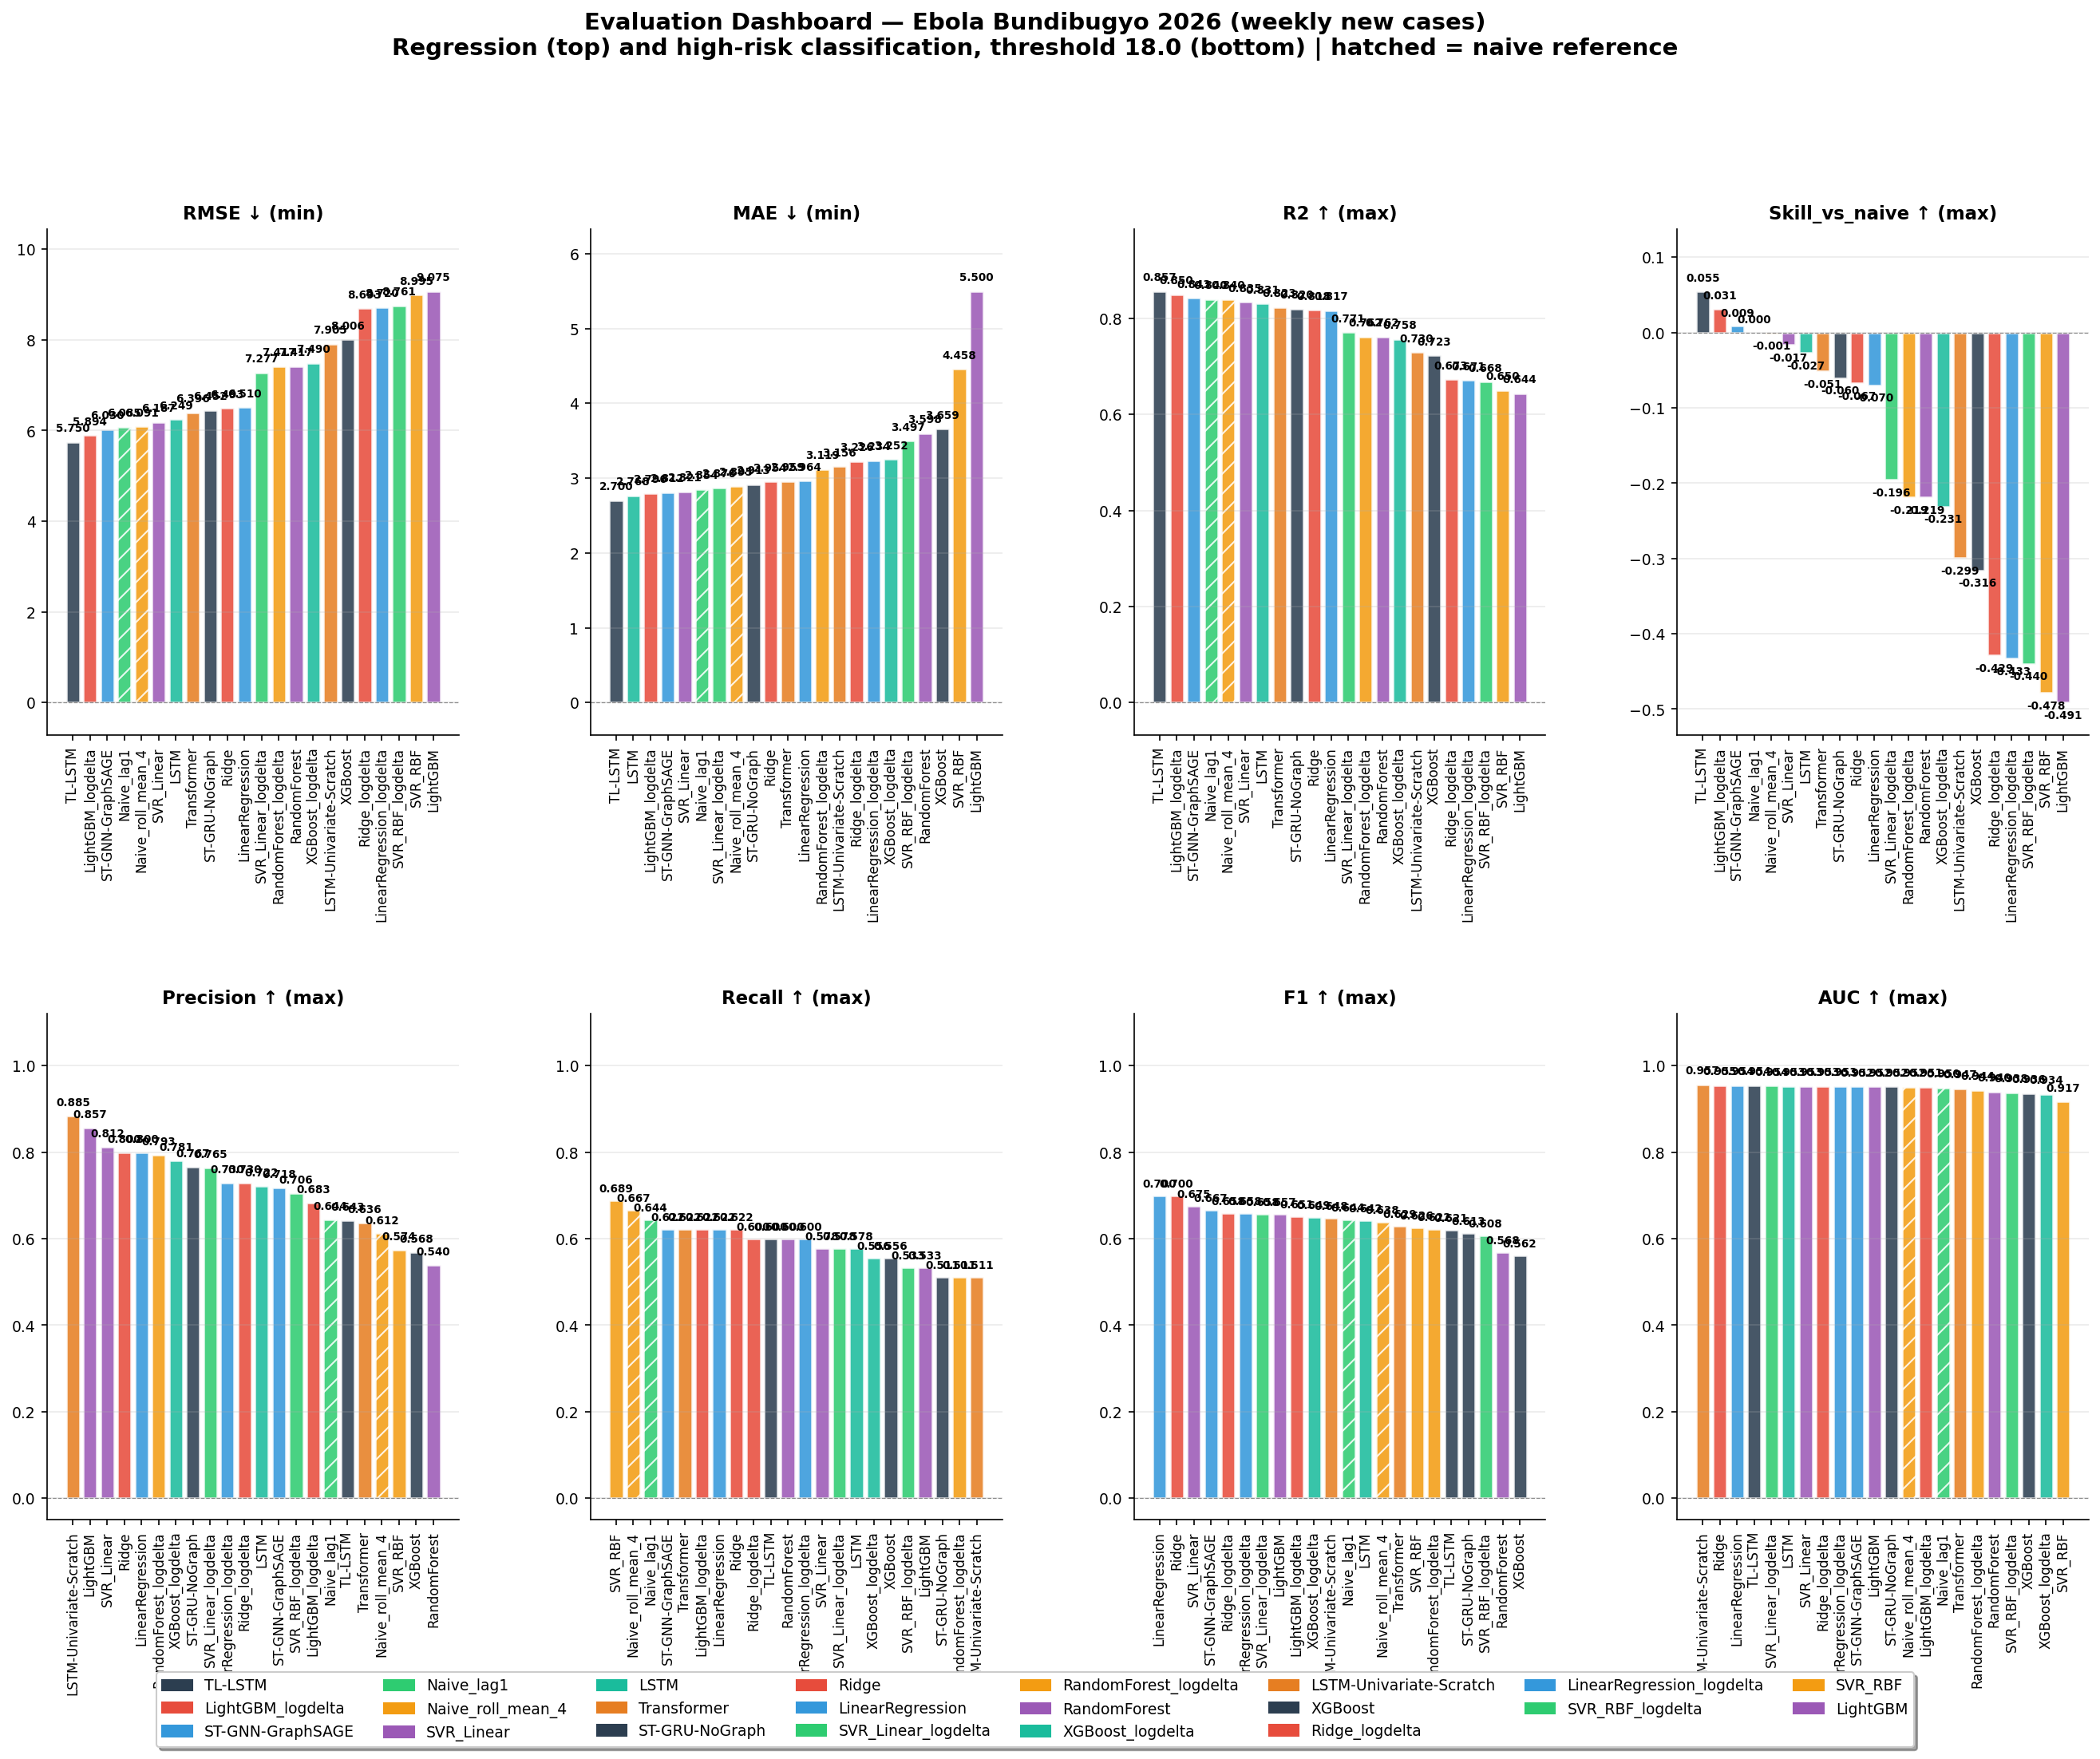

Saved figure: 10_pred_vs_actual.png


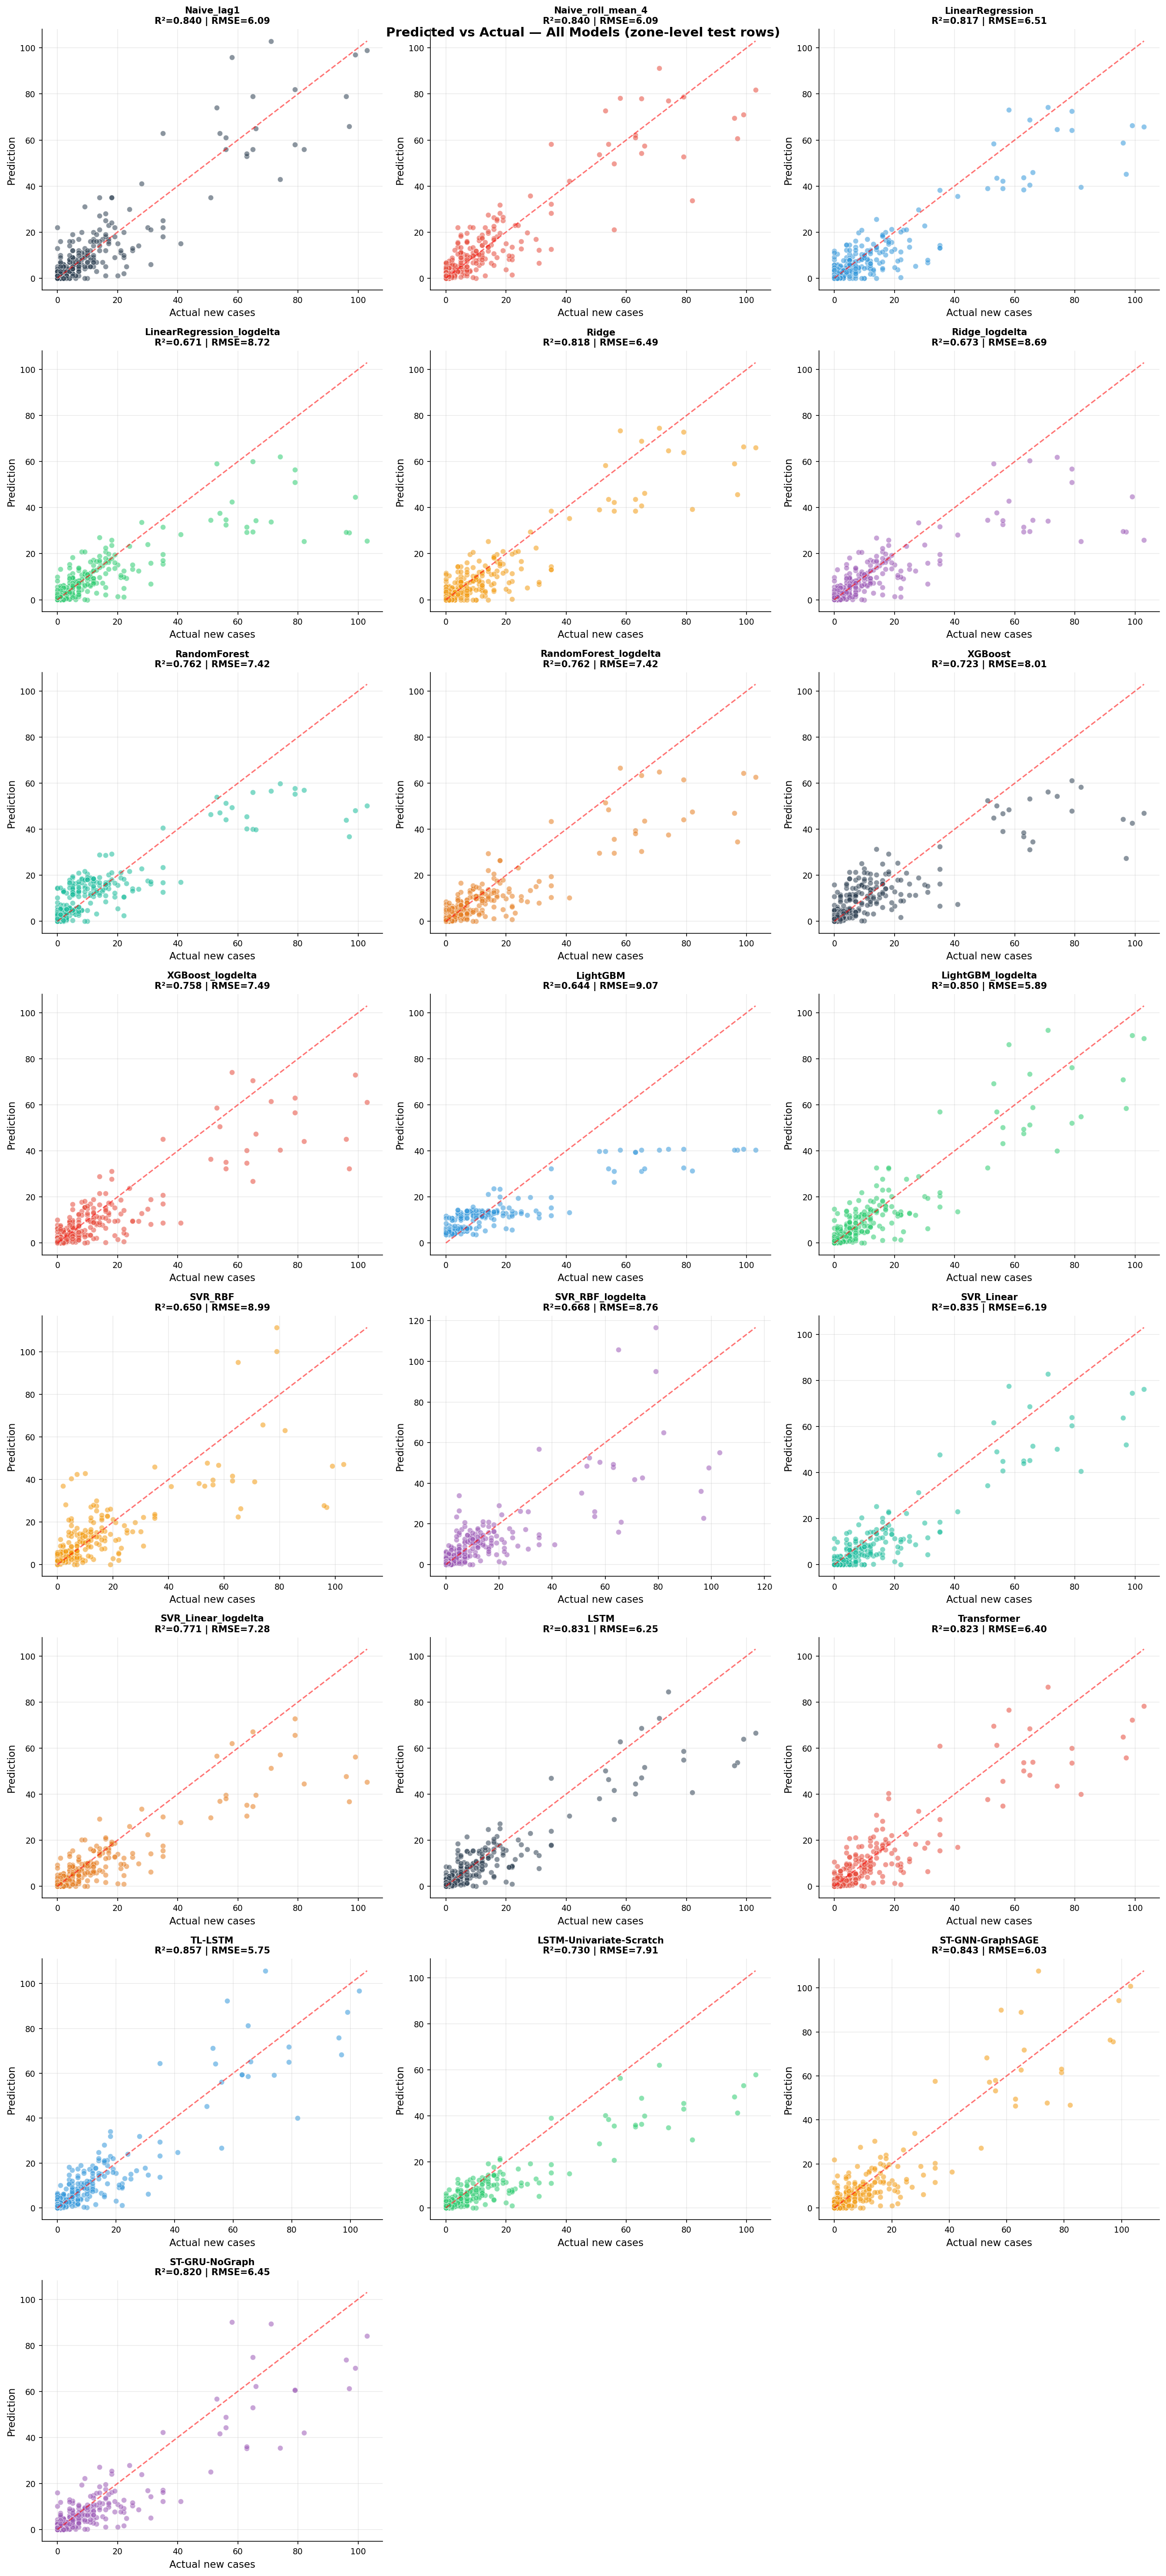

Saved figure: 10b_national_weekly_fit.png


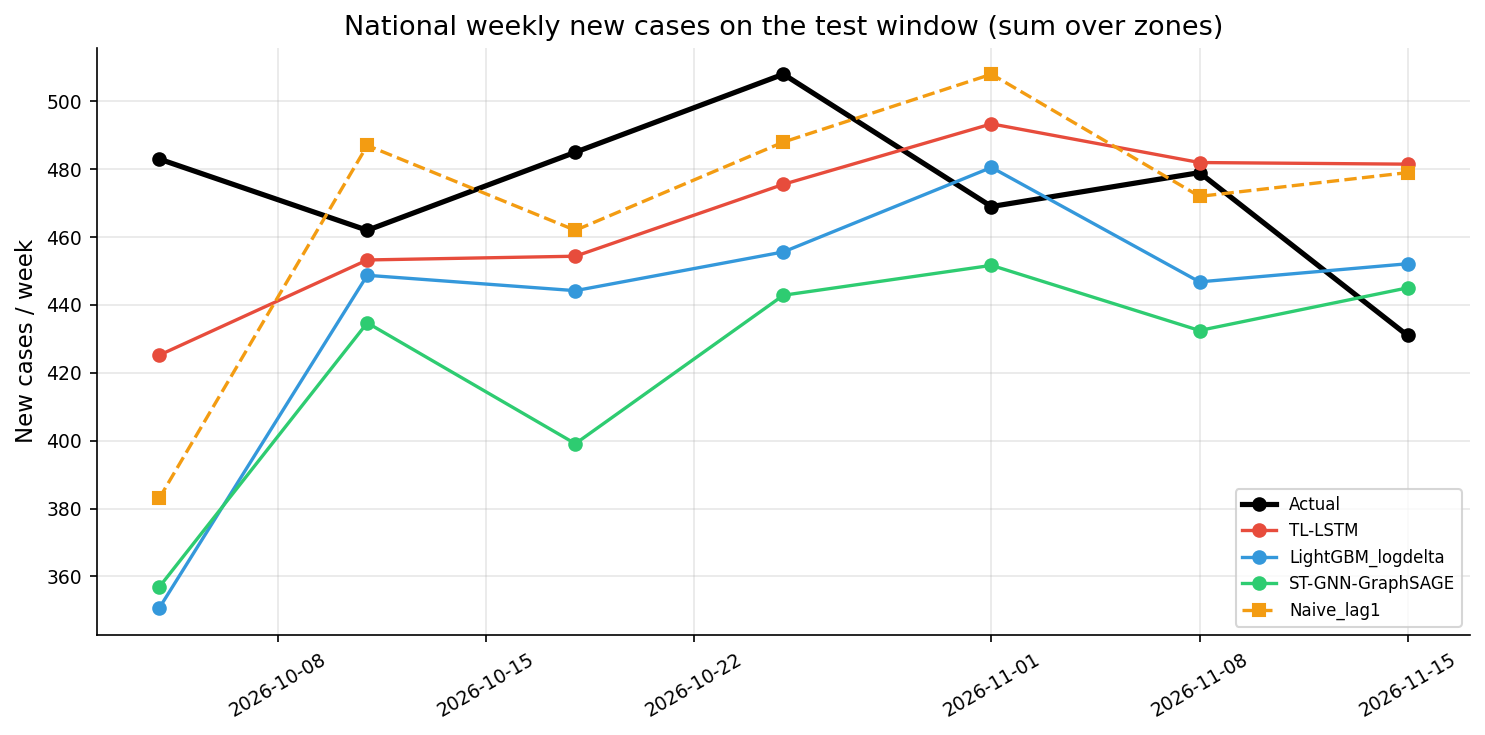

In [21]:

# MODULE 12.1 · Results table, dashboard, predicted vs actual

RESULTS_DF = pd.DataFrame(ALL_RESULTS).dropna(subset=['RMSE']).sort_values('RMSE').reset_index(drop=True)
RESULTS_DF['Family'] = RESULTS_DF['Model'].map(MODEL_FAMILY)
NAIVE_RMSE = float(RESULTS_DF.loc[RESULTS_DF['Model'] == 'Naive_lag1', 'RMSE'].iloc[0])


def bootstrap_skill_ci(pred: np.ndarray, n_boot: int, seed: int = 0):
    """95% interval of  skill = 1 − RMSE(model)/RMSE(persistence)  by resampling whole TEST PERIODS with replacement
    (all zones of a period are kept together, which respects the correlation between zones).
    Returns (low, high, P(skill > 0))."""
    dates = TEST_DF['date'].to_numpy()
    uniq = np.unique(dates)
    idx_by = [np.flatnonzero(dates == d) for d in uniq]
    rng = np.random.default_rng(seed)
    sk = np.full(n_boot, np.nan)
    for b in range(n_boot):
        idx = np.concatenate([idx_by[k] for k in rng.integers(0, len(uniq), len(uniq))])
        rm = np.sqrt(np.mean((Y_TEST[idx] - pred[idx]) ** 2))
        rn = np.sqrt(np.mean((Y_TEST[idx] - NAIVE_TEST[idx]) ** 2))
        if rn > 0:
            sk[b] = 1 - rm / rn
    sk = sk[~np.isnan(sk)]
    return (float(np.percentile(sk, 2.5)), float(np.percentile(sk, 97.5)), float((sk > 0).mean())) if len(sk) else (np.nan,) * 3


_ci = {m: bootstrap_skill_ci(ALL_PREDS[m], CFG.N_SKILL_BOOT, CFG.SEED) for m in RESULTS_DF['Model']}
RESULTS_DF['Skill_CI_low'] = RESULTS_DF['Model'].map(lambda m: round(_ci[m][0], 3))
RESULTS_DF['Skill_CI_high'] = RESULTS_DF['Model'].map(lambda m: round(_ci[m][1], 3))
RESULTS_DF['P_skill_gt0'] = RESULTS_DF['Model'].map(lambda m: round(_ci[m][2], 3))

print("=" * 96)
print("COMPLETE MODEL COMPARISON — Ebola Bundibugyo 2026")
print(f"Resolution: {CFG.FREQ} | test {SPLIT_INFO['test_start']} → {SPLIT_INFO['test_end']} | "
      f"high-risk threshold: {RISK_THR:.1f} cases/{CFG.step_label} | persistence RMSE: {NAIVE_RMSE:.4f}")
print("=" * 96)
DISPLAY_COLS = [c for c in ['Model', 'Family', 'RMSE', 'MAE', 'MAPE', 'R2', 'Skill_vs_naive', 'Accuracy', 'Precision',
                            'Recall', 'F1', 'AUC'] if c in RESULTS_DF.columns]
print(RESULTS_DF[DISPLAY_COLS].to_string(index=False))

LEARNED = RESULTS_DF[RESULTS_DF['Family'] != 'naive']
print(f"\nSkill vs persistence with a 95% bootstrap interval over the {TEST_DF['date'].nunique()} test periods "
      f"({CFG.N_SKILL_BOOT} resamples) — an interval above 0 is needed to claim a real improvement:")
print(LEARNED.sort_values('Skill_vs_naive', ascending=False)[['Model', 'Skill_vs_naive', 'Skill_CI_low', 'Skill_CI_high', 'P_skill_gt0']]
      .head(12).to_string(index=False))
N_SIGNIFICANT = int((LEARNED['Skill_CI_low'] > 0).sum())
print(f"→ {N_SIGNIFICANT} learned model(s) are significantly better than persistence on this test window.")
BEST_ROW = LEARNED.iloc[0] if len(LEARNED) else RESULTS_DF.iloc[0]
print(f"\nBest learned model: {BEST_ROW['Model']} | RMSE={BEST_ROW['RMSE']:.4f} | R²={BEST_ROW['R2']:.4f} | "
      f"skill vs persistence={BEST_ROW['Skill_vs_naive']:+.3f}")
if BEST_ROW['Skill_vs_naive'] <= 0:
    print("NOTE: no learned model beats persistence ('next = last') on this test window. "
          "Report this honestly; the test window is short.")
else:
    n_beat = int((LEARNED['Skill_vs_naive'] > 0).sum())
    print(f"{n_beat} of {len(LEARNED)} learned models beat persistence.")


def plot_complete_dashboard(results_df: pd.DataFrame, cfg: Config) -> None:
    """2 x 4 panels: regression metrics (top) and high-risk classification metrics (bottom)."""
    colors = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(results_df['Model'])}
    lower_better = {'RMSE', 'MAE', 'MAPE'}
    fig = plt.figure(figsize=(22, 14))
    gs = gridspec.GridSpec(2, 4, figure=fig, hspace=0.55, wspace=0.32)

    def _panel(ax, metric: str, bounded: bool) -> None:
        sub = results_df.dropna(subset=[metric]).copy()
        if sub.empty:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(metric, fontweight='bold')
            return
        asc = metric in lower_better
        sub = sub.sort_values(metric, ascending=asc)
        bars = ax.bar(range(len(sub)), sub[metric], color=[colors[m] for m in sub['Model']], edgecolor='white', lw=1.2, alpha=0.87,
                      hatch=None)
        for b, fam in zip(bars, sub['Family']):
            if fam == 'naive':
                b.set_hatch('//')
        ax.set_xticks(range(len(sub)))
        ax.set_xticklabels(sub['Model'], fontsize=8, rotation=90, ha='center', va='top')
        ax.axhline(0, color='black', lw=0.6, ls='--', alpha=0.4)
        mx = max(sub[metric].abs().max(), 1e-8)
        for b, v in zip(bars, sub[metric]):
            sign = 1 if b.get_height() >= 0 else -1
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + sign * mx * 0.02, f'{v:.3f}', ha='center',
                    va='bottom' if sign > 0 else 'top', fontsize=6.5, fontweight='bold')
        ax.set_title(f"{metric} {'↓ (min)' if asc else '↑ (max)'}", fontweight='bold', fontsize=11)
        ax.grid(True, alpha=0.25, axis='y')
        if bounded:
            ax.set_ylim(-0.05, 1.12)
        else:
            lo, hi = min(sub[metric].min(), 0), sub[metric].max()
            ax.set_ylim(lo - 0.08 * (hi - lo + 1e-8), hi + 0.15 * (hi - lo + 1e-8))

    for col, m in enumerate(['RMSE', 'MAE', 'R2', 'Skill_vs_naive']):
        _panel(fig.add_subplot(gs[0, col]), m, False)
    for col, m in enumerate(['Precision', 'Recall', 'F1', 'AUC']):
        _panel(fig.add_subplot(gs[1, col]), m, True)
    fig.legend(handles=[Patch(color=c, label=m) for m, c in colors.items()], loc='lower center',
               ncol=min(8, len(colors)), fontsize=9, bbox_to_anchor=(0.5, -0.03), frameon=True, fancybox=True, shadow=True)
    fig.suptitle(f"Evaluation Dashboard — Ebola Bundibugyo 2026 ({cfg.step_label}ly new cases)\n"
                 f"Regression (top) and high-risk classification, threshold {RISK_THR:.1f} (bottom) | hatched = naive reference",
                 fontweight='bold', fontsize=14, y=1.01)
    save_fig(fig, "09_complete_dashboard.png")
    plt.show()


plot_complete_dashboard(RESULTS_DF, CFG)


def plot_pred_vs_actual(all_preds: Dict[str, np.ndarray], y_test: np.ndarray, cfg: Config) -> None:
    n = len(all_preds)
    nc = min(3, n)
    nr = (n + nc - 1) // nc
    fig, axes = plt.subplots(nr, nc, figsize=(6 * nc, 5 * nr), squeeze=False)
    for k, (ax, (name, preds)) in enumerate(zip(axes.flatten(), all_preds.items())):
        yp = np.clip(preds, 0, None)
        r2v = r2_score(y_test, yp) if len(np.unique(y_test)) > 1 else np.nan
        rmse = np.sqrt(mean_squared_error(y_test, yp))
        ax.scatter(y_test, yp, alpha=0.55, s=35, color=PALETTE[k % len(PALETTE)], edgecolors='white', lw=0.5)
        lim = max(y_test.max(), yp.max(), 1)
        ax.plot([0, lim], [0, lim], 'r--', lw=1.5, alpha=0.55)
        ax.set_title(f"{name}\nR²={r2v:.3f} | RMSE={rmse:.2f}", fontweight='bold', fontsize=10)
        ax.set_xlabel("Actual new cases"); ax.set_ylabel("Prediction"); ax.grid(True, alpha=0.25)
    for ax in axes.flatten()[n:]:
        ax.axis('off')
    fig.suptitle("Predicted vs Actual — All Models (zone-level test rows)", fontweight='bold', fontsize=14)
    plt.tight_layout()
    save_fig(fig, "10_pred_vs_actual.png")
    plt.show()


plot_pred_vs_actual(ALL_PREDS, Y_TEST, CFG)


def plot_national_fit(cfg: Config, n_models: int = 3) -> None:
    """Sum over zones per test period: actual vs the best learned models and persistence."""
    top = list(LEARNED['Model'].head(n_models))
    d = TEST_DF[['date']].copy()
    d['actual'] = Y_TEST
    for name in top + ['Naive_lag1']:
        d[name] = ALL_PREDS[name]
    agg = d.groupby('date').sum()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(agg.index, agg['actual'], 'k-o', lw=2.5, label='Actual')
    for i, name in enumerate(top + ['Naive_lag1']):
        ax.plot(agg.index, agg[name], '--s' if name == 'Naive_lag1' else '-o', lw=1.6, color=PALETTE[(i + 1) % len(PALETTE)], label=name)
    ax.set_title(f"National {cfg.step_label}ly new cases on the test window (sum over zones)")
    ax.set_ylabel(f"New cases / {cfg.step_label}"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    save_fig(fig, "10b_national_weekly_fit.png")
    plt.show()


plot_national_fit(CFG)

── Chronological cross-validation (expanding window) ────────
   4 folds | blocks of ~4 weeks
                    Model  RMSE_mean  RMSE_std  R2_mean  R2_std  Skill_mean
             RandomForest    14.0611    1.9863   0.4939  0.1946     -0.0506
               SVR_Linear    14.1221    3.3957   0.5408  0.0267      0.0117
                  XGBoost    14.2074    2.5437   0.5117  0.1059     -0.0305
                    Ridge    14.4140    2.8479   0.5064  0.0699     -0.0315
        LightGBM_logdelta    14.5158    4.3204   0.5259  0.0982      0.0191
               Naive_lag1    14.9616    4.7462   0.4989  0.1250      0.0000
                 LightGBM    15.4750    3.9542   0.4444  0.1343     -0.0662
         XGBoost_logdelta    15.5141    4.4864   0.4467  0.1447     -0.0594
                  SVR_RBF    15.9908    2.0118   0.3367  0.2833     -0.2031
    RandomForest_logdelta    16.1182    5.2154   0.4040  0.2069     -0.0801
         SVR_RBF_logdelta    17.0486    2.7643   0.2914  0.1478     -0

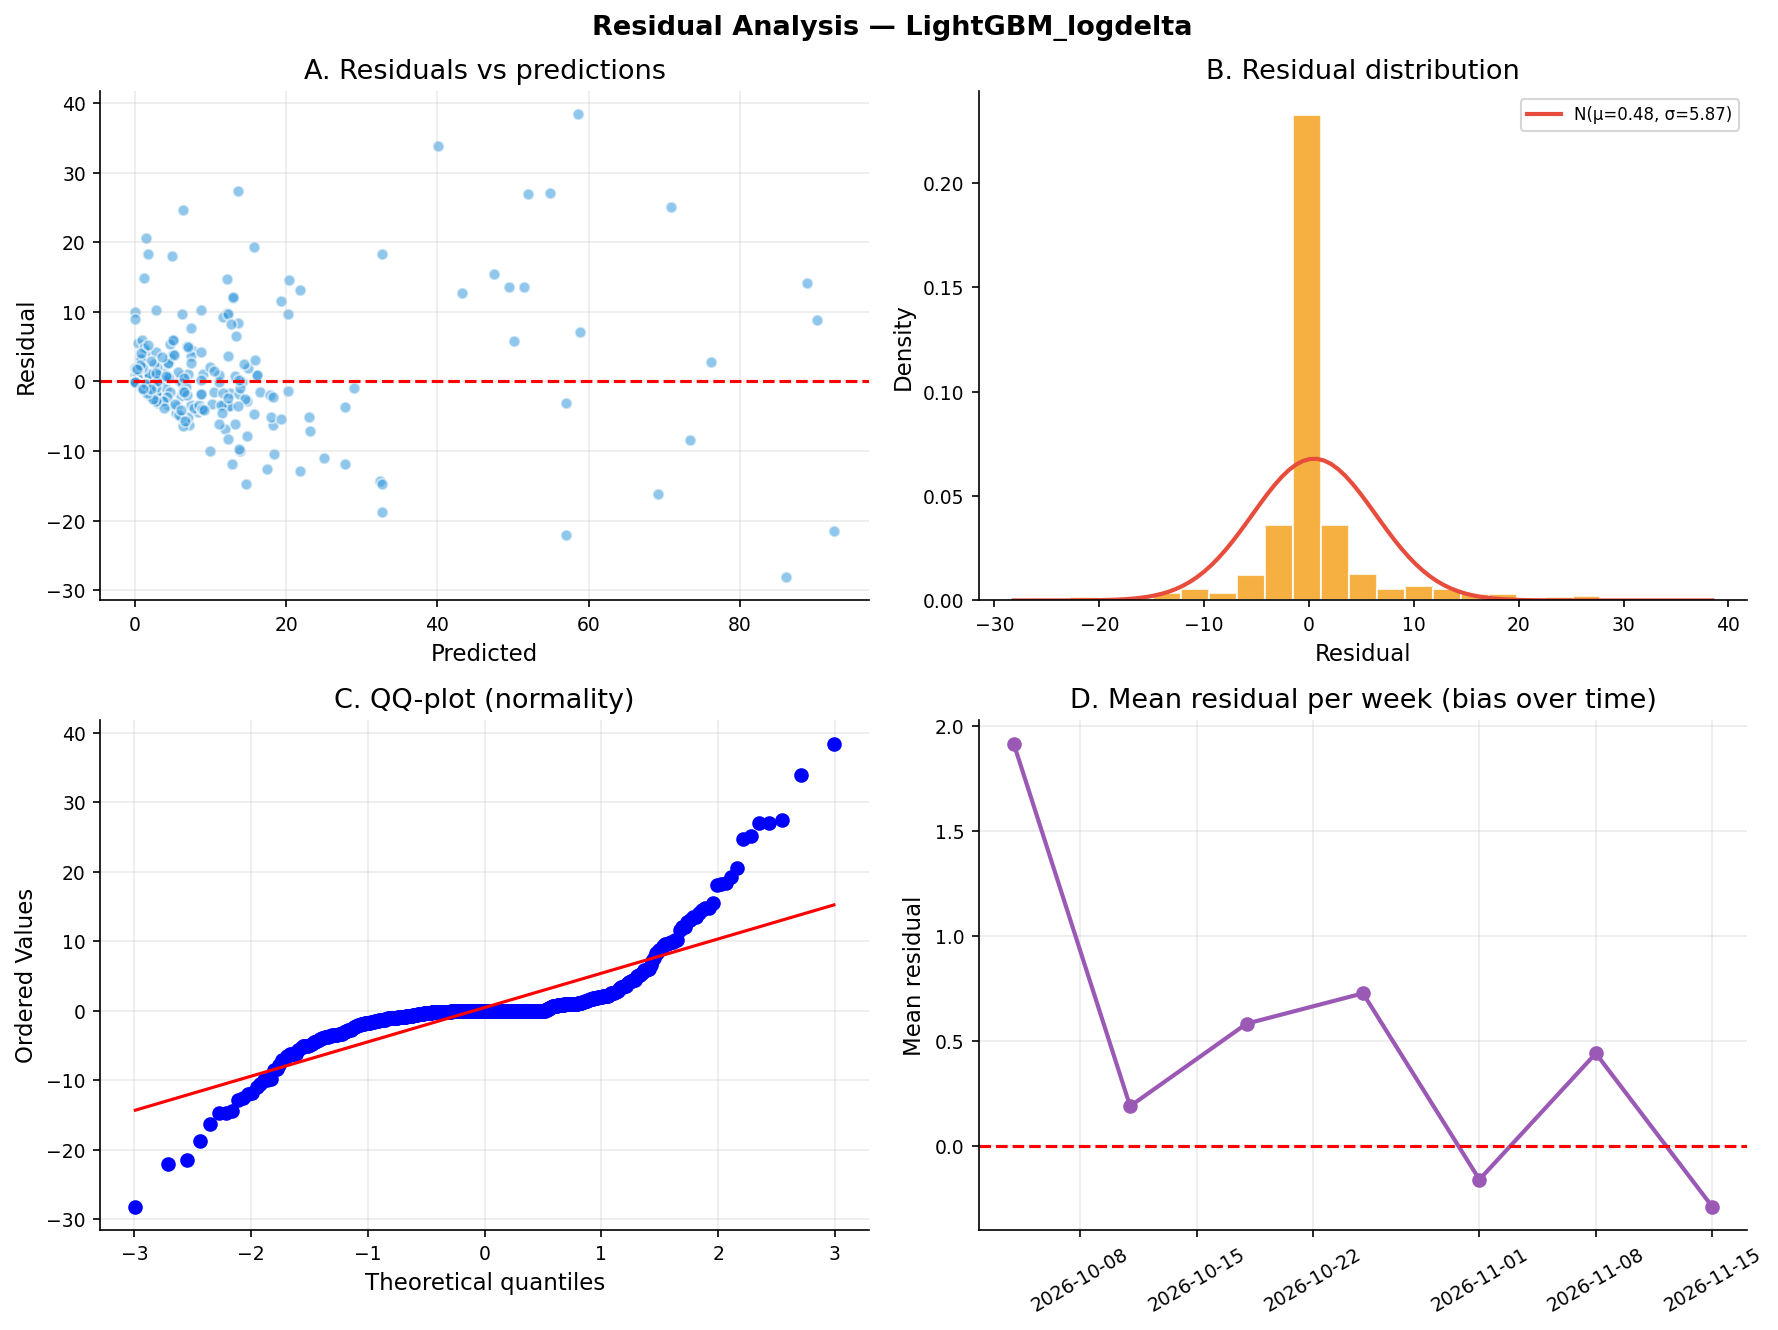

   Shapiro-Wilk: stat=0.7048 p=0.0000 (non-normal)
   Mean bias: 0.4775 | MAE: 2.7965


In [22]:

# MODULE 12.2 · Chronological cross-validation, residual analysis

def run_chronological_cv(train_df: pd.DataFrame, feature_cols: List[str], target_col: str, cfg: Config,
                         collect_for: Optional[str] = None):
    """Expanding-window CV by date: the periods are split in N+1 consecutive blocks; fold k trains on blocks
    0..k-1 and validates on block k. Fresh estimators and a fresh FeaturePrep are fitted in every fold.
    Raw-target and log-delta variants of every model are evaluated. For `collect_for`, the out-of-fold Pearson residuals
    (y − ŷ)/sqrt(ŷ + 1) are returned with their zone and date (used by the probabilistic forecast)."""
    d = train_df.sort_values(['date', 'zone']).reset_index(drop=True)
    dates = np.sort(d['date'].unique())
    blocks = np.array_split(dates, cfg.N_CV_FOLDS + 1)
    base_names = list(MODEL_FACTORIES)
    names = base_names + [n + DELTA_SUFFIX for n in base_names]
    rec = {n: {'rmse': [], 'r2': [], 'skill': []} for n in names + ['Naive_lag1']}
    oof_rows, folds_used = [], 0
    print("── Chronological cross-validation (expanding window) ────────")
    for k in range(1, cfg.N_CV_FOLDS + 1):
        tr = d[d['date'].isin(np.concatenate(blocks[:k]))]
        va = d[d['date'].isin(blocks[k])]
        if len(tr) < 30 or len(va) < 10:
            continue
        folds_used += 1
        prep = FeaturePrep().fit(tr[feature_cols].to_numpy())
        Xtr, Xva = prep.transform(tr[feature_cols].to_numpy()), prep.transform(va[feature_cols].to_numpy())
        ytr, yva = tr[target_col].to_numpy(float), va[target_col].to_numpy(float)
        lag_tr, lag_va = tr['lag_1'].to_numpy(float), va['lag_1'].to_numpy(float)
        rm_n = float(np.sqrt(mean_squared_error(yva, lag_va)))
        rec['Naive_lag1']['rmse'].append(rm_n)
        rec['Naive_lag1']['r2'].append(float(r2_score(yva, lag_va)))
        rec['Naive_lag1']['skill'].append(0.0)
        for n in names:
            try:
                m = fit_model(n, Xtr, target_for(n, ytr, lag_tr), y_counts=ytr)
                p = predict_counts(n, m, Xva, lag_va)
                rm = float(np.sqrt(mean_squared_error(yva, p)))
                rec[n]['rmse'].append(rm)
                rec[n]['r2'].append(float(r2_score(yva, p)))
                rec[n]['skill'].append(1 - rm / rm_n if rm_n > 0 else np.nan)
                if collect_for == n:
                    oof_rows.append(pd.DataFrame({'zone': va['zone'].to_numpy(), 'date': va['date'].to_numpy(),
                                                  'fold': k, 'r': (yva - p) / np.sqrt(p + 1.0)}))
            except Exception as e:
                print(f"   fold {k} {n}: {e}")
    rows = []
    for n, v in rec.items():
        if v['rmse']:
            rows.append({'Model': n, 'RMSE_mean': round(np.mean(v['rmse']), 4), 'RMSE_std': round(np.std(v['rmse']), 4),
                         'R2_mean': round(np.mean(v['r2']), 4), 'R2_std': round(np.std(v['r2']), 4),
                         'Skill_mean': round(float(np.nanmean(v['skill'])), 4)})
    cv = pd.DataFrame(rows).sort_values('RMSE_mean').reset_index(drop=True)
    print(f"   {folds_used} folds | blocks of ~{len(blocks[0])} {cfg.step_label}s")
    print(cv.to_string(index=False))
    return cv, (pd.concat(oof_rows, ignore_index=True) if oof_rows else pd.DataFrame(columns=['zone', 'date', 'fold', 'r']))


CV_RESULTS, OOF_RESID = run_chronological_cv(TRAIN_DF, FEATURE_COLS, TARGET_COL, CFG, collect_for=BEST_CLASSICAL)


def plot_residual_analysis(name: str, cfg: Config) -> None:
    """Residuals of the best classical model on the test rows."""
    preds = ALL_PREDS[name]
    res = Y_TEST - preds
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    fig.suptitle(f"Residual Analysis — {name}", fontweight='bold', fontsize=13)
    ax = axes[0, 0]
    ax.scatter(preds, res, alpha=0.55, color=PALETTE[2], edgecolors='white', s=30)
    ax.axhline(0, color='red', ls='--', lw=1.5)
    ax.set_title("A. Residuals vs predictions"); ax.set_xlabel("Predicted"); ax.set_ylabel("Residual"); ax.grid(True, alpha=0.25)
    ax = axes[0, 1]
    mu, sd = res.mean(), res.std()
    ax.hist(res, bins=min(25, max(5, len(res) // 5)), color=PALETTE[4], edgecolor='white', alpha=0.8, density=True)
    xs = np.linspace(res.min(), res.max(), 100)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color=PALETTE[1], lw=2, label=f"N(μ={mu:.2f}, σ={sd:.2f})")
    ax.set_title("B. Residual distribution"); ax.set_xlabel("Residual"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
    ax = axes[1, 0]
    stats.probplot(res, dist='norm', plot=ax)
    ax.set_title("C. QQ-plot (normality)"); ax.grid(True, alpha=0.25)
    ax = axes[1, 1]
    per = pd.DataFrame({'date': TEST_DF['date'], 'res': res}).groupby('date')['res'].mean()
    ax.plot(per.index, per.values, 'o-', color=PALETTE[5], lw=2)
    ax.axhline(0, color='red', ls='--', lw=1.5)
    ax.set_title(f"D. Mean residual per {cfg.step_label} (bias over time)"); ax.set_ylabel("Mean residual")
    ax.tick_params(axis='x', rotation=30); ax.grid(True, alpha=0.25)
    plt.tight_layout()
    save_fig(fig, f"11_residuals_{name.replace(' ', '_')}.png")
    plt.show()
    sw_stat, sw_p = stats.shapiro(res) if 3 <= len(res) <= 5000 else (np.nan, np.nan)
    print(f"   Shapiro-Wilk: stat={sw_stat:.4f} p={sw_p:.4f} ({'normal' if sw_p > 0.05 else 'non-normal'})")
    print(f"   Mean bias: {res.mean():.4f} | MAE: {np.abs(res).mean():.4f}")


if BEST_CLASSICAL:
    plot_residual_analysis(BEST_CLASSICAL, CFG)


── Probabilistic forecast — LightGBM_logdelta (793 out-of-fold residuals) ─────────
   Last observed national value: 440 cases/week
   2026-11-22  median=  496.2  mean=  653.7  95% [439.0, 1285.5]  deterministic=419.2
   2026-11-29  median=  682.3  mean=  825.8  95% [472.0, 1632.1]  deterministic=403.7
   2026-12-06  median=  888.7  mean= 1035.3  95% [501.8, 2374.8]  deterministic=391.2
   2026-12-13  median= 1017.6  mean= 1212.5  95% [559.2, 2796.0]  deterministic=382.3
Saved figure: 12_probabilistic_forecast.png


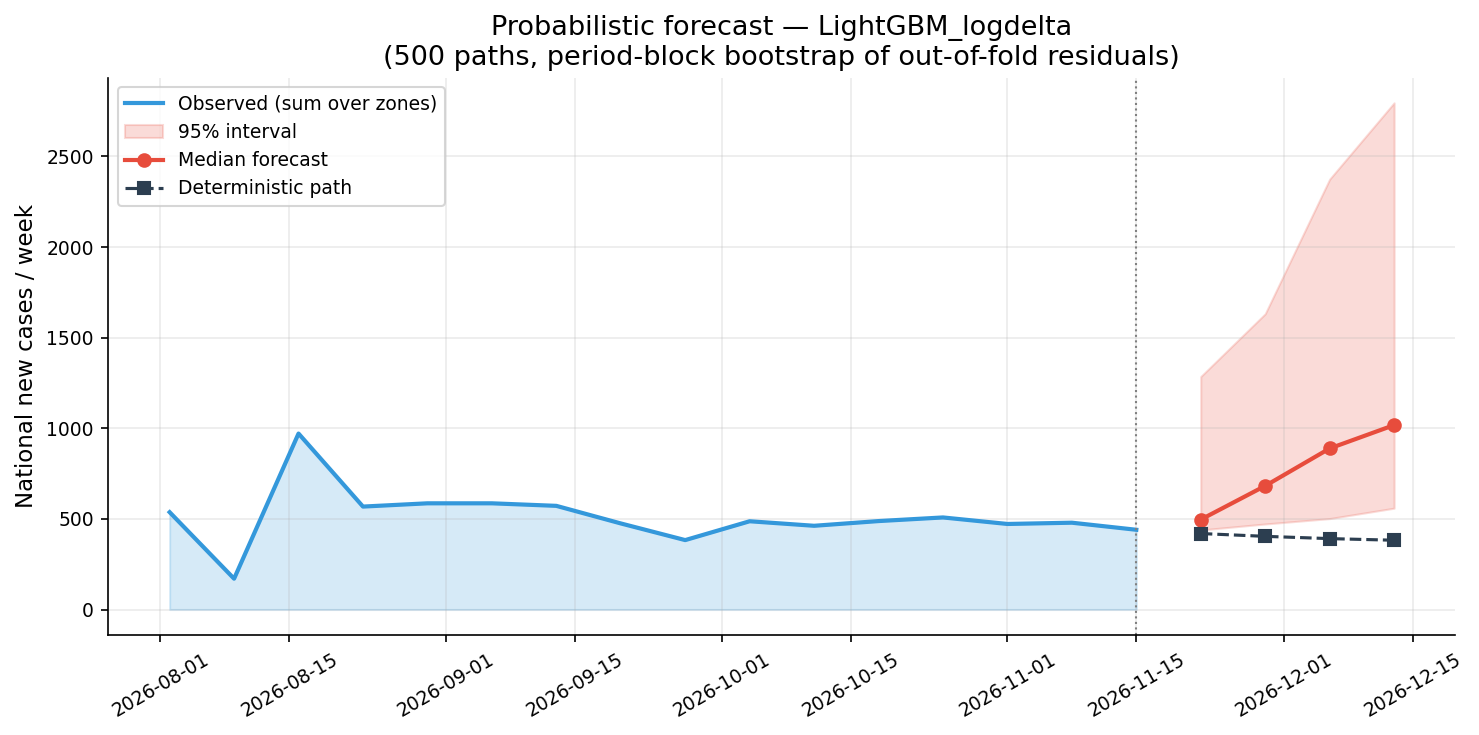

In [23]:

# MODULE 12.3 · Probabilistic recursive forecast of national incidence

def residual_matrix(oof: pd.DataFrame) -> np.ndarray:
    """(periods x zones) matrix of out-of-fold Pearson residuals, winsorised at the 2.5th / 97.5th percentiles
    (NaN where a zone was not active in that period)."""
    oof = oof[oof['fold'] > oof['fold'].max() - CFG.RESID_LAST_FOLDS]          # most recent error regime only
    piv = oof.pivot_table(index='date', columns='zone', values='r', aggfunc='mean').reindex(columns=ZONES)
    R = piv.to_numpy(float)
    if np.isfinite(R).any():
        lo, hi = np.nanpercentile(R, [2.5, 97.5])
        R = np.clip(R, lo, hi)
    return R


def draw_residuals(R: np.ndarray, n_paths: int, rng: np.random.Generator) -> np.ndarray:
    """One residual vector per path: a whole PERIOD of the out-of-fold residuals is drawn at random, so the errors of the
    zones stay correlated (as in reality); zones missing in that period get a random residual of the same period."""
    out = np.zeros((n_paths, R.shape[1]))
    for i, k in enumerate(rng.integers(0, len(R), n_paths)):
        row = R[k]
        ok = np.isfinite(row)
        if not ok.any():
            continue
        v = row.copy()
        v[~ok] = rng.choice(row[ok], size=int((~ok).sum()))
        out[i] = v
    return out


def recursive_forecast(name: str, model, cfg: Config, n_paths: int, oof: pd.DataFrame, seed: int = 0) -> Dict[str, Any]:
    """Multi-step national forecast with the best classical model.

    Zone-level forecasts are rolled forward recursively (features are recomputed from the simulated history with the SAME
    function as the training table). Uncertainty: for every simulated period one period of out-of-fold Pearson residuals
    (most recent cross-validation folds) is drawn and applied as  y = max(ŷ + sqrt(ŷ + 1)·r, 0)  (count-scaled noise, correlated across zones).
    The national value is the sum over zones. Limitation: no new zone can appear during the forecast horizon."""
    rng = np.random.default_rng(seed)
    A = HIST_ARRAYS
    H0, C0, first, dates = A['H'], A['C'][:, -1], A['first'], A['dates']
    Z, T = H0.shape
    steps = cfg.forecast_steps
    R = residual_matrix(oof) if len(oof) else np.empty((0, Z))

    def roll(P: int, noisy: bool) -> np.ndarray:
        Hp = np.zeros((P, Z, T + steps))
        Hp[:, :, :T] = H0[None]
        cum = np.tile(C0, (P, 1))
        nat = np.zeros((P, steps))
        for h in range(steps):
            t = T + h
            date = dates[-1] + pd.Timedelta(days=cfg.step_days * (h + 1))
            feats = features_from_history(Hp[:, :, :t], cum, t - first, date, cfg)          # (P, Z, F)
            pred = predict_counts_raw(name, model, feats)                                   # (P, Z) counts
            if noisy:
                pred = np.clip(pred + np.sqrt(pred + 1.0) * draw_residuals(R, P, rng), 0, None)
            Hp[:, :, t] = pred
            cum = cum + pred
            nat[:, h] = pred.sum(axis=1)
        return nat

    det = roll(1, False)[0]
    sims = roll(n_paths, True) if len(R) else np.tile(det, (n_paths, 1))
    f_dates = [dates[-1] + pd.Timedelta(days=cfg.step_days * (h + 1)) for h in range(steps)]
    return {'dates': f_dates, 'deterministic': det, 'mean': sims.mean(axis=0), 'median': np.median(sims, axis=0),
            'lower': np.percentile(sims, 2.5, axis=0), 'upper': np.percentile(sims, 97.5, axis=0)}


def plot_probabilistic_forecast(fc: Dict[str, Any], name: str, cfg: Config) -> None:
    hist_dates = HIST_ARRAYS['dates'][-16:]
    hist_vals = HIST_ARRAYS['H'].sum(axis=0)[-16:]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.fill_between(hist_dates, 0, hist_vals, alpha=0.2, color=PALETTE[2])
    ax.plot(hist_dates, hist_vals, color=PALETTE[2], lw=2, label="Observed (sum over zones)")
    ax.fill_between(fc['dates'], fc['lower'], fc['upper'], color=PALETTE[1], alpha=0.2, label="95% interval")
    ax.plot(fc['dates'], fc['median'], 'o-', color=PALETTE[1], lw=2, label="Median forecast")
    ax.plot(fc['dates'], fc['deterministic'], 's--', color=PALETTE[0], lw=1.5, label="Deterministic path")
    ax.axvline(HIST_ARRAYS['dates'][-1], color='gray', ls=':', lw=1)
    ax.set_title(f"Probabilistic forecast — {name}\n({cfg.N_BOOTSTRAP} paths, period-block bootstrap of out-of-fold residuals)")
    ax.set_ylabel(f"National new cases / {cfg.step_label}"); ax.grid(True, alpha=0.25); ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    save_fig(fig, "12_probabilistic_forecast.png")
    plt.show()


FORECAST: Dict[str, Any] = {}
if BEST_CLASSICAL:
    try:
        _fc = recursive_forecast(BEST_CLASSICAL, ALL_MODELS[BEST_CLASSICAL], CFG, CFG.N_BOOTSTRAP, OOF_RESID, seed=CFG.SEED)
        print(f"\n── Probabilistic forecast — {BEST_CLASSICAL} ({len(OOF_RESID)} out-of-fold residuals) ─────────")
        print(f"   Last observed national value: {HIST_ARRAYS['H'].sum(axis=0)[-1]:.0f} cases/{CFG.step_label}")
        for i, d in enumerate(_fc['dates']):
            print(f"   {d.date()}  median={_fc['median'][i]:7.1f}  mean={_fc['mean'][i]:7.1f}  "
                  f"95% [{_fc['lower'][i]:.1f}, {_fc['upper'][i]:.1f}]  deterministic={_fc['deterministic'][i]:.1f}")
        plot_probabilistic_forecast(_fc, BEST_CLASSICAL, CFG)
        FORECAST = {'model': BEST_CLASSICAL, 'resolution': CFG.FREQ, 'n_paths': CFG.N_BOOTSTRAP,
                    'uncertainty': 'out-of-fold Pearson residuals, period-block bootstrap (correlated across zones)',
                    'dates': [str(d.date()) for d in _fc['dates']],
                    **{k: [round(float(x), 2) for x in _fc[k]] for k in ('median', 'mean', 'lower', 'upper', 'deterministic')}}
        RUN_STATUS['forecast'] = 'ok'
    except Exception as e:
        RUN_STATUS['forecast'] = f'failed: {e}'
        print(f"Forecast FAILED: {e}")

In [24]:

# MODULE 12.4 · Export: LaTeX table, JSON report, final summary

def _tex(s: str) -> str:
    return str(s).replace('_', r'\_').replace('%', r'\%').replace('&', r'\&')


def export_latex_table(results_df: pd.DataFrame, cfg: Config) -> str:
    """booktabs table; the best value of every column is in bold (underscores escaped)."""
    cols = [c for c in ['RMSE', 'MAE', 'R2', 'Skill_vs_naive', 'F1', 'AUC'] if c in results_df.columns]
    results_df = results_df.copy()
    results_df['Model'] = results_df['Model'].str.replace('_logdelta', r'+$\Delta$', regex=False)
    lower = {'RMSE', 'MAE'}
    head = {'Skill_vs_naive': 'Skill'}
    lines = [r"\begin{table}[htbp]", r"\centering",
             r"\caption{Model comparison on the chronological test window --- Ebola Bundibugyo 2026 "
             rf"({cfg.step_label}ly new cases per health zone; Skill = 1 $-$ RMSE/RMSE of persistence)}}",
             r"\label{tab:model_comparison}", r"\begin{tabular}{l" + "r" * len(cols) + "}", r"\toprule",
             r"\textbf{Model} & " + " & ".join(rf"\textbf{{{head.get(c, c)}}}" for c in cols) + r" \\", r"\midrule"]
    for _, row in results_df.iterrows():
        vals = []
        for c in cols:
            v = row.get(c)
            if pd.isna(v):
                vals.append("---")
                continue
            best = results_df[c].min() if c in lower else results_df[c].max()
            txt = f"{v:.3f}"
            vals.append(rf"\textbf{{{txt}}}" if v == best else txt)
        lines.append(_tex(row['Model']) + " & " + " & ".join(vals) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    latex = "\n".join(lines)
    (cfg.REPORT_DIR / "table_results.tex").write_text(latex, encoding='utf-8')
    print(f"LaTeX table saved: {cfg.REPORT_DIR / 'table_results.tex'}")
    return latex


def _py(obj):
    """JSON-safe conversion of NumPy / pandas objects."""
    if isinstance(obj, (np.integer,)):  return int(obj)
    if isinstance(obj, (np.floating,)): return None if np.isnan(obj) else float(obj)
    if isinstance(obj, (np.ndarray,)):  return [_py(x) for x in obj.tolist()]
    if isinstance(obj, (pd.Timestamp, datetime, Path)): return str(obj)
    if isinstance(obj, dict):  return {str(k): _py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)): return [_py(v) for v in obj]
    if isinstance(obj, float) and np.isnan(obj): return None
    return obj


def export_full_report(results_df: pd.DataFrame, cfg: Config) -> Dict:
    best = BEST_ROW.to_dict()
    tl_summary = (TL_SEED_TABLE.groupby('model')['RMSE'].agg(['mean', 'std']).round(4).reset_index().to_dict('records')
                  if len(TL_SEED_TABLE) else [])
    abl = (TL_ABLATION.groupby(['K', 'model'])['RMSE'].mean().round(4).reset_index().to_dict('records')
           if len(TL_ABLATION) else [])
    versions = {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__}
    if TORCH_OK:
        versions['torch'] = torch.__version__
    report = {
        "title": "Ebola Bundibugyo 2026 (DRC) — Forecasting with real transfer learning, spatio-temporal GNN and XAI",
        "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "version": "3.0",
        "source": "INRB-UMIE BDBV2026-Data",
        "provenance": PROVENANCE,
        "package_versions": versions,
        "config": {"resolution": cfg.FREQ, "train_end": cfg.TRAIN_END, "test_start": cfg.TEST_START,
                   "test_end": cfg.TEST_END or SPLIT_INFO['test_end'], "risk_pctile": cfg.RISK_PCTILE,
                   "risk_threshold": round(RISK_THR, 3), "seq_len": cfg.seq_len, "lags": list(cfg.lags),
                   "rolls": list(cfg.rolls), "n_cv_folds": cfg.N_CV_FOLDS, "n_bootstrap": cfg.N_BOOTSTRAP,
                   "seed": cfg.SEED, "tl_seq_len": cfg.TL_SEQ_LEN, "tl_seeds": cfg.TL_SEEDS},
        "split": SPLIT_INFO,
        "leakage_test_passed": bool(LEAK_TEST_PASSED),
        "persistence_rmse": NAIVE_RMSE,
        "best_learned_model": {k: best.get(k) for k in ('Model', 'RMSE', 'MAE', 'R2', 'Skill_vs_naive', 'F1', 'AUC')},
        "n_models_beating_persistence": int((LEARNED['Skill_vs_naive'] > 0).sum()),
        "n_models_significantly_beating_persistence": int(N_SIGNIFICANT),
        "persistence_anchored_variants": sorted(n for n in ALL_MODELS if is_delta(n)),
        "model_ranking": results_df.to_dict('records'),
        "statistical_tests": STAT_RESULTS,
        "cv_results": CV_RESULTS.to_dict('records') if len(CV_RESULTS) else [],
        "forecast": FORECAST,
        "transfer_learning": {"sources": PROVENANCE.get('historical_sources', {}), "label": TL_LABEL,
                              "seed_summary": tl_summary, "leave_one_outbreak_out": LOO_TABLE.to_dict('records'),
                              "fewshot_ablation_mean_rmse": abl},
        "graph": {k: GNN_ADJ[k] for k in ('geo_source', 'n_geo', 'n_sim', 'n_edges', 'isolated')},
        "run_status": RUN_STATUS,
        "figures": sorted(p.name for p in cfg.FIG_DIR.glob("*.png")),
    }
    path = cfg.REPORT_DIR / "complete_report.json"
    with path.open('w', encoding='utf-8') as f:
        json.dump(_py(report), f, indent=2, ensure_ascii=False)
    print(f"Report JSON saved: {path}")
    return report


LATEX_TABLE = export_latex_table(RESULTS_DF, CFG)
print(LATEX_TABLE)
REPORT = export_full_report(RESULTS_DF, CFG)
RESULTS_DF.to_csv(CFG.REPORT_DIR / "model_comparison.csv", index=False)

print("\n" + "=" * 68)
print("COMPLETE PIPELINE — EBOLA BUNDIBUGYO 2026")
print("=" * 68)
print(f"""
Date              : {datetime.now().strftime('%Y-%m-%d %H:%M')}
Data release      : {PROVENANCE.get('data_release')}
Resolution        : {CFG.FREQ} | test {SPLIT_INFO['test_start']} → {SPLIT_INFO['test_end']}
Leakage test      : {'passed' if LEAK_TEST_PASSED else 'FAILED'}
Models evaluated  : {len(RESULTS_DF)} (including {int((RESULTS_DF['Family'] == 'naive').sum())} naive references)
Best learned model: {BEST_ROW['Model']}  RMSE={BEST_ROW['RMSE']:.4f}  R²={BEST_ROW['R2']:.4f}  skill vs persistence={BEST_ROW['Skill_vs_naive']:+.3f}
Figures ({len(list(CFG.FIG_DIR.glob('*.png')))}) → {CFG.FIG_DIR}
Report            → {CFG.REPORT_DIR / 'complete_report.json'}
LaTeX             → {CFG.REPORT_DIR / 'table_results.tex'}
""")
print("Transfer-learning sources:", {n: v['kind'] for n, v in PROVENANCE.get('historical_sources', {}).items()})
print("Section status:")
for _k, _v in RUN_STATUS.items():
    print(f"   {_k:24s} {_v}")
print("\nFull ranking:")
for _i, _r in RESULTS_DF.iterrows():
    _medal = ["1st", "2nd", "3rd"][_i] if _i < 3 else f"{_i + 1}th"
    print(f" {_medal:>4} {_r['Model']:<26} RMSE={_r['RMSE']:.4f} R²={_r['R2']:.4f} skill={_r['Skill_vs_naive']:+.3f} F1={_r['F1']:.4f}")

LaTeX table saved: outputs\reports\table_results.tex
\begin{table}[htbp]
\centering
\caption{Model comparison on the chronological test window --- Ebola Bundibugyo 2026 (weekly new cases per health zone; Skill = 1 $-$ RMSE/RMSE of persistence)}
\label{tab:model_comparison}
\begin{tabular}{lrrrrrr}
\toprule
\textbf{Model} & \textbf{RMSE} & \textbf{MAE} & \textbf{R2} & \textbf{Skill} & \textbf{F1} & \textbf{AUC} \\
\midrule
TL-LSTM & \textbf{5.750} & \textbf{2.700} & \textbf{0.857} & \textbf{0.055} & 0.621 & 0.954 \\
LightGBM+$\Delta$ & 5.894 & 2.796 & 0.850 & 0.031 & 0.651 & 0.951 \\
ST-GNN-GraphSAGE & 6.030 & 2.812 & 0.843 & 0.009 & 0.667 & 0.952 \\
Naive\_lag1 & 6.085 & 2.854 & 0.840 & 0.000 & 0.644 & 0.950 \\
Naive\_roll\_mean\_4 & 6.091 & 2.895 & 0.840 & -0.001 & 0.638 & 0.952 \\
SVR\_Linear & 6.187 & 2.821 & 0.835 & -0.017 & 0.675 & 0.953 \\
LSTM & 6.249 & 2.768 & 0.831 & -0.027 & 0.642 & 0.953 \\
Transformer & 6.396 & 2.959 & 0.823 & -0.051 & 0.629 & 0.947 \\
ST-GRU-NoGraph & 6.45

## Notes, assumptions and known limitations

* **Target and unit.** New confirmed cases per health zone and per `CFG.FREQ` period (week by default); the emergence period of a zone (its first case) is not forecast. Metrics are pooled over zone-periods, so they are dominated by the few large zones; read them together with the persistence reference (`Skill_vs_naive`).
* **Persistence-anchored models.** `*_logdelta` models predict the log growth versus "next = last"; the neural networks and the GNN add a learned correction to an anchor channel `log1p(lag_1)`. They can match persistence by construction, so any gain is a genuine improvement. Read `Skill_CI_low` / `Skill_CI_high` in the results table: only an interval above 0 supports a claim of improvement.
* **Short test window.** With weekly resolution the test set covers only a few weeks. Treat the ranking as indicative, use the chronological cross-validation table for stability, and re-run when new data are released.
* **Transfer learning.** It is only genuine when every source in `PROVENANCE['historical_sources']` is `real`. The model name carries a `*` (`TL-LSTM*`) when a source is simulated. Compare `TL-LSTM` with `LSTM-Univariate-Scratch` (same architecture and input), over seeds and few-shot sizes, before claiming any benefit; a null or negative result is a valid finding. Zaire-strain sources differ from Bundibugyo (vaccine, treatment, context): check the leave-one-outbreak-out table.
* **Case definitions.** The 2026 series is confirmed cases. Make sure the historical files use the same definition (the loader prefers "confirmed" indicators and reports which one it used).
* **Graph.** Geographic edges come from GeoJSON polygons when available, otherwise from approximate centroids of a few zones (not verified); similarity edges use the training period only. The "no-graph" control quantifies the contribution of the graph.
* **Forecast.** Recursive multi-step forecast of the best classical model; uncertainty comes from out-of-fold residuals; no new zone can appear inside the horizon, and reporting delays/backfilling are not modelled.
* **Reproducibility.** Seeds are fixed (`CFG.SEED`), the data release tag and the source files are stored in `outputs/reports/complete_report.json`.